# Introduction to the Tidyverse


In this class will get you started on the path to exploring and visualizing your own data with the R programming language. 

<b>tidyverse</b> is a collection of data science tools within R for transforming and visualizing data. This is not the only set of tools in R, but it's a powerful and popular approach for exploring data. 




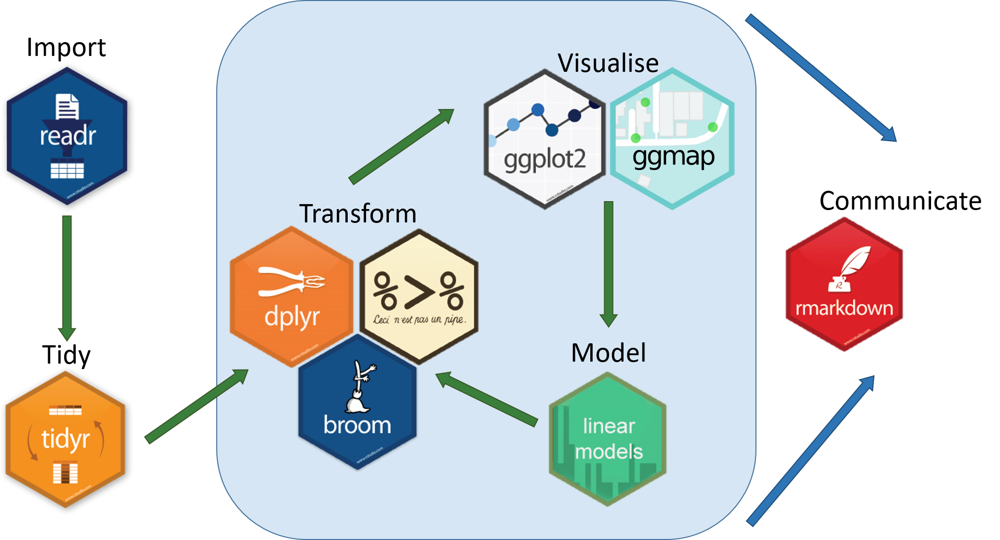

A useful R package for data science is <b>dplyr</b> created by Hadley Wickham (hadley.nz), which provides step-by-step tools for transforming this data, such as filtering, sorting, and summarizing it.

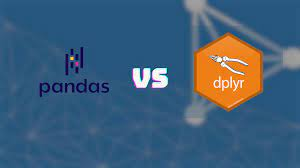

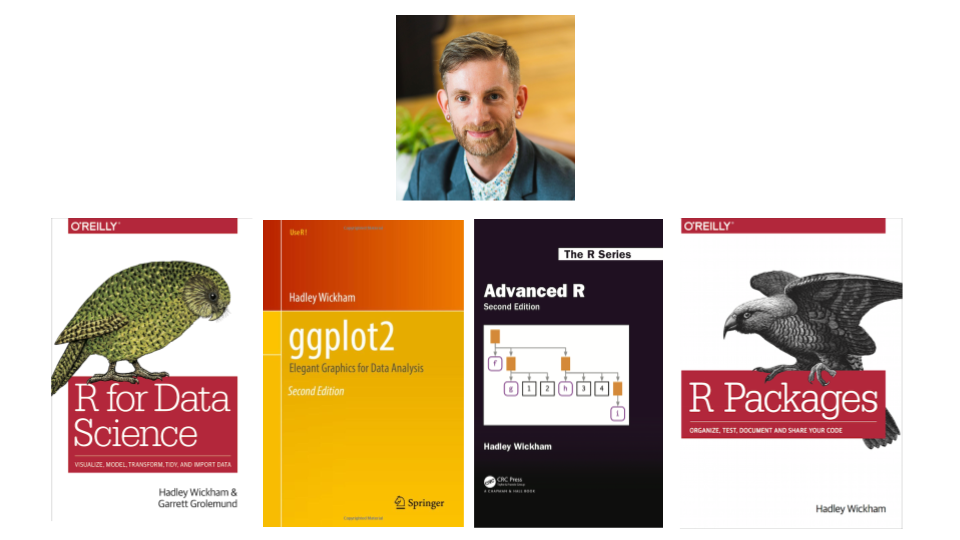

## Gapminder

For this, we will use the dataset Gapminder. Gapminder tracks economic and social indicators like life expectancy and the GDP per capita of countries over time. 

https://github.com/jennybc/gapminder


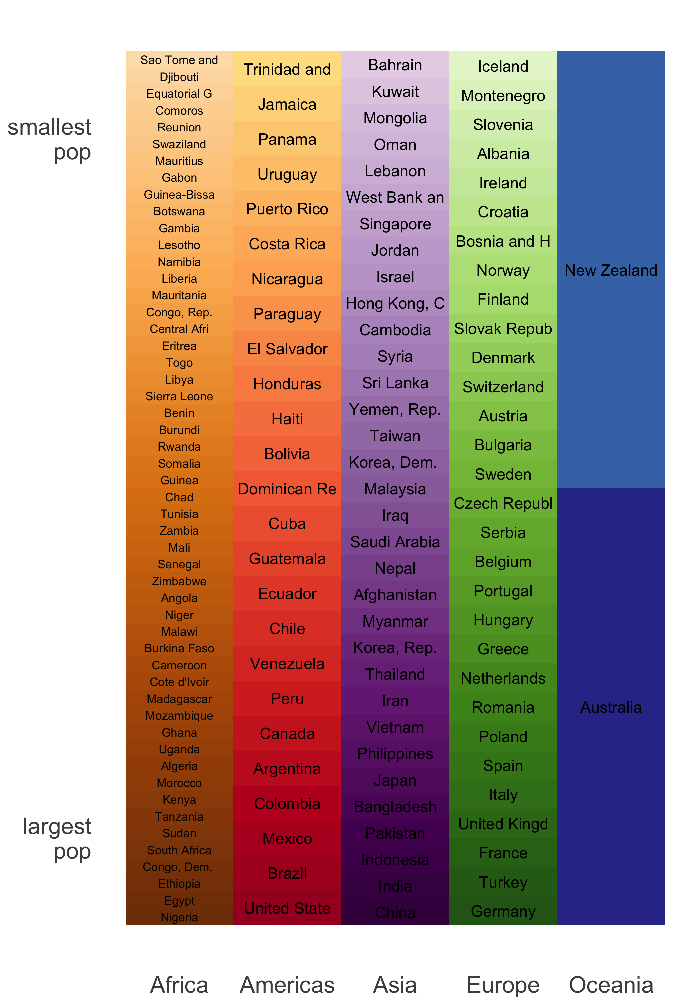

what kinds of questions emerge from these data and how to answer them?

Let's starts

In [ ]:
#install.packages("gapminder")


In [1]:
library(gapminder)

In [2]:
gapminder

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134
Afghanistan,Asia,1982,39.854,12881816,978.0114
Afghanistan,Asia,1987,40.822,13867957,852.3959
Afghanistan,Asia,1992,41.674,16317921,649.3414


In [3]:
str(gapminder)

tibble [1,704 × 6] (S3: tbl_df/tbl/data.frame)
 $ country  : Factor w/ 142 levels "Afghanistan",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ continent: Factor w/ 5 levels "Africa","Americas",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ year     : int [1:1704] 1952 1957 1962 1967 1972 1977 1982 1987 1992 1997 ...
 $ lifeExp  : num [1:1704] 28.8 30.3 32 34 36.1 ...
 $ pop      : int [1:1704] 8425333 9240934 10267083 11537966 13079460 14880372 12881816 13867957 16317921 22227415 ...
 $ gdpPercap: num [1:1704] 779 821 853 836 740 ...


Gapminder is structured as a data frame. A data frame keeps rectangular data in rows and columns, similar to a spreadsheet, or a table in a SQL database. Most data analyses in R are centered around data frames. 

    gapminder
    
    A tibble: 1704 × 6

This tells you the <b>tibble</b> has one 1704 rows, each of which we call an <b>observation</b>. It has six columns, each of which we call a <b>variable</b>. It's important in an analysis to understand what each observation, or row, represents. 

Here, each represents a unique pair of a country and a year. For example, the first observation represents country statistics for Afghanistan in 1952, the second for Afghanistan in 1957, and so on. For each combination of a country and year, the dataset contains several variables, or columns, describing the country's demographics.

We see the continent - in this case, Asia - the life expectancy in years, the population, and the GDP per capita. The GDP per capita is the country's total economic output (Gross Domestic Product) divided by its population, and it's a common measure of how wealthy a country is. Each variable is of one consistent data type: some are numbers, like life expectancy and population and some are categorical, like country and continent.

In [21]:
library(gapminder)
library(dplyr)

gapminder %>% dplyr::glimpse()

Rows: 1,704
Columns: 6
$ country   <fct> "Afghanistan", "Afghanistan", "Afghanistan", "Afghanistan", …
$ continent <fct> Asia, Asia, Asia, Asia, Asia, Asia, Asia, Asia, Asia, Asia, …
$ year      <int> 1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, …
$ lifeExp   <dbl> 28.801, 30.332, 31.997, 34.020, 36.088, 38.438, 39.854, 40.8…
$ pop       <int> 8425333, 9240934, 10267083, 11537966, 13079460, 14880372, 12…
$ gdpPercap <dbl> 779.4453, 820.8530, 853.1007, 836.1971, 739.9811, 786.1134, …


## Count()

The count() function in R is a powerful tool that allows you to determine the frequency or count of unique values within a numerical variable. This means you can quickly and easily find out how many times each distinct value appears in your dataset. This can be particularly useful for understanding the distribution of your data or identifying common patterns within it.

In [29]:
library(gapminder)
library(dplyr)

gapminder %>% count()

n
<int>
1704


In [32]:
library(gapminder)
library(dplyr)

gapminder %>% count(year)

year,n
<int>,<int>
1952,142
1957,142
1962,142
1967,142
1972,142
1977,142
1982,142
1987,142
1992,142


In [33]:
library(gapminder)
library(dplyr)

gapminder %>% count(year, continent)

year,continent,n
<int>,<fct>,<int>
1952,Africa,52
1952,Americas,25
1952,Asia,33
1952,Europe,30
1952,Oceania,2
1957,Africa,52
1957,Americas,25
1957,Asia,33
1957,Europe,30


In [36]:
library(gapminder)
library(dplyr)

gapminder %>% count(year, sort = TRUE)

year,n
<int>,<int>
1952,142
1957,142
1962,142
1967,142
1972,142
1977,142
1982,142
1987,142
1992,142


The weight option in the count function of the dplyr package in R is used to assign weights to the rows in a data frame or tibble when counting the occurrences of unique values in one or more columns. This is particularly useful when you want to give different importance or frequencies to individual rows while computing counts.

In [45]:
library(gapminder)
library(dplyr)

gapminder %>% count(year, wt = pop)

year,n
<int>,<dbl>
1952,2406957150
1957,2664404580
1962,2899782974
1967,3217478384
1972,3576977158
1977,3930045807
1982,4289436840
1987,4691477418
1992,5110710260


## Select()

<b>select()</b> function is used to choose a subset of variables (columns) from a data frame. It is particularly helpful when you have a large dataset with many variables, and you want to focus only on a subset of those variables for analysis or visualization.

In [1]:
library(gapminder)
library(dplyr)

gapminder %>% select(continent)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




continent
<fct>
Asia
Asia
Asia
Asia
Asia
Asia
Asia
Asia
Asia


In [2]:
library(gapminder)
library(dplyr)

gapminder %>% select(continent, year)

continent,year
<fct>,<int>
Asia,1952
Asia,1957
Asia,1962
Asia,1967
Asia,1972
Asia,1977
Asia,1982
Asia,1987
Asia,1992


In [4]:
library(gapminder)
library(dplyr)

gapminder %>% select(country:year)

country,continent,year
<fct>,<fct>,<int>
Afghanistan,Asia,1952
Afghanistan,Asia,1957
Afghanistan,Asia,1962
Afghanistan,Asia,1967
Afghanistan,Asia,1972
Afghanistan,Asia,1977
Afghanistan,Asia,1982
Afghanistan,Asia,1987
Afghanistan,Asia,1992


In [5]:
library(gapminder)
library(dplyr)

gapminder %>% select(-year)

country,continent,lifeExp,pop,gdpPercap
<fct>,<fct>,<dbl>,<int>,<dbl>
Afghanistan,Asia,28.801,8425333,779.4453
Afghanistan,Asia,30.332,9240934,820.8530
Afghanistan,Asia,31.997,10267083,853.1007
Afghanistan,Asia,34.020,11537966,836.1971
Afghanistan,Asia,36.088,13079460,739.9811
Afghanistan,Asia,38.438,14880372,786.1134
Afghanistan,Asia,39.854,12881816,978.0114
Afghanistan,Asia,40.822,13867957,852.3959
Afghanistan,Asia,41.674,16317921,649.3414


In [14]:
library(gapminder)
library(dplyr)

gapminder %>% select(starts_with("co"))

#gapminder %>% select(ends_with("co"))

country,continent
<fct>,<fct>
Afghanistan,Asia
Afghanistan,Asia
Afghanistan,Asia
Afghanistan,Asia
Afghanistan,Asia
Afghanistan,Asia
Afghanistan,Asia
Afghanistan,Asia
Afghanistan,Asia


In [11]:
library(gapminder)
library(dplyr)

gapminder %>% select(contains("e"))

continent,year,lifeExp,gdpPercap
<fct>,<int>,<dbl>,<dbl>
Asia,1952,28.801,779.4453
Asia,1957,30.332,820.8530
Asia,1962,31.997,853.1007
Asia,1967,34.020,836.1971
Asia,1972,36.088,739.9811
Asia,1977,38.438,786.1134
Asia,1982,39.854,978.0114
Asia,1987,40.822,852.3959
Asia,1992,41.674,649.3414


In [61]:
library(gapminder)
library(dplyr)

gapminder %>% select(2:last_col())

continent,year,lifeExp,pop,gdpPercap
<fct>,<int>,<dbl>,<int>,<dbl>
Asia,1952,28.801,8425333,779.4453
Asia,1957,30.332,9240934,820.8530
Asia,1962,31.997,10267083,853.1007
Asia,1967,34.020,11537966,836.1971
Asia,1972,36.088,13079460,739.9811
Asia,1977,38.438,14880372,786.1134
Asia,1982,39.854,12881816,978.0114
Asia,1987,40.822,13867957,852.3959
Asia,1992,41.674,16317921,649.3414


In [62]:
library(gapminder)
library(dplyr)

gapminder %>% select(1:last_col()-1)

country,continent,year,lifeExp,pop
<fct>,<fct>,<int>,<dbl>,<int>
Afghanistan,Asia,1952,28.801,8425333
Afghanistan,Asia,1957,30.332,9240934
Afghanistan,Asia,1962,31.997,10267083
Afghanistan,Asia,1967,34.020,11537966
Afghanistan,Asia,1972,36.088,13079460
Afghanistan,Asia,1977,38.438,14880372
Afghanistan,Asia,1982,39.854,12881816
Afghanistan,Asia,1987,40.822,13867957
Afghanistan,Asia,1992,41.674,16317921


we can even change the name of a variable

In [13]:
library(gapminder)
library(dplyr)

a <- gapminder %>% select(continente = continent)
a

continente
<fct>
Asia
Asia
Asia
Asia
Asia
Asia
Asia
Asia
Asia


## Rename()

In dplyr, the <b>rename()</b> function is used to rename columns in a data frame. It allows you to change the names of one or more variables (columns) to new names.

In [74]:
library(gapminder)
library(dplyr)

a <- gapminder %>% rename(population = pop)
a

country,continent,year,lifeExp,population,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134
Afghanistan,Asia,1982,39.854,12881816,978.0114
Afghanistan,Asia,1987,40.822,13867957,852.3959
Afghanistan,Asia,1992,41.674,16317921,649.3414


## Filter()

You use <b>filter</b> when you want to look only at a subset of your observations, based on a particular condition. Filtering data is a common first step in an analysis. 

A pipe: %>% says "take whatever is before it, and feed it into the next step.

In [8]:
#install.packages('dplyr')
library(gapminder)
library(dplyr)

gapminder %>% filter(continent == "Asia") %>% 
filter(year == 2007)



country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,2007,43.828,31889923,974.5803
Bahrain,Asia,2007,75.635,708573,29796.0483
Bangladesh,Asia,2007,64.062,150448339,1391.2538
Cambodia,Asia,2007,59.723,14131858,1713.7787
China,Asia,2007,72.961,1318683096,4959.1149
"Hong Kong, China",Asia,2007,82.208,6980412,39724.9787
India,Asia,2007,64.698,1110396331,2452.2104
Indonesia,Asia,2007,70.650,223547000,3540.6516
Iran,Asia,2007,70.964,69453570,11605.7145


In [26]:
#install.packages('dplyr')
library(gapminder)
library(dplyr)

gapminder %>% filter(continent == "Asia", year == 2007) 

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,2007,43.828,31889923,974.5803
Bahrain,Asia,2007,75.635,708573,29796.0483
Bangladesh,Asia,2007,64.062,150448339,1391.2538
Cambodia,Asia,2007,59.723,14131858,1713.7787
China,Asia,2007,72.961,1318683096,4959.1149
"Hong Kong, China",Asia,2007,82.208,6980412,39724.9787
India,Asia,2007,64.698,1110396331,2452.2104
Indonesia,Asia,2007,70.650,223547000,3540.6516
Iran,Asia,2007,70.964,69453570,11605.7145


Notice that now, we have only 142 rows: that's how many countries are in the dataset. It's important to note that you're not removing any rows from the original gapminder data. You can still use the gapminder object for other analyses.

In [9]:
gapminder %>%
filter(country == "Chile")

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Chile,Americas,1952,54.745,6377619,3939.979
Chile,Americas,1957,56.074,7048426,4315.623
Chile,Americas,1962,57.924,7961258,4519.094
Chile,Americas,1967,60.523,8858908,5106.654
Chile,Americas,1972,63.441,9717524,5494.024
Chile,Americas,1977,67.052,10599793,4756.764
Chile,Americas,1982,70.565,11487112,5095.666
Chile,Americas,1987,72.492,12463354,5547.064
Chile,Americas,1992,74.126,13572994,7596.126


### Multiple conditions

In [10]:
gapminder %>%
filter(year <= 2007, continent == "Asia")

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134
Afghanistan,Asia,1982,39.854,12881816,978.0114
Afghanistan,Asia,1987,40.822,13867957,852.3959
Afghanistan,Asia,1992,41.674,16317921,649.3414


In [80]:
gapminder %>%
filter(continent %in% c("Asia", "Europe"))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134
Afghanistan,Asia,1982,39.854,12881816,978.0114
Afghanistan,Asia,1987,40.822,13867957,852.3959
Afghanistan,Asia,1992,41.674,16317921,649.3414


## Arrange()

arrange sorts the observations in a dataset, in ascending or descending order based on one of its variables. This is useful, for example, when you want to know the most extreme values in a dataset.

In [11]:
library(dplyr)
gapminder %>% arrange(gdpPercap)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
"Congo, Dem. Rep.",Africa,2002,44.966,55379852,241.1659
"Congo, Dem. Rep.",Africa,2007,46.462,64606759,277.5519
Lesotho,Africa,1952,42.138,748747,298.8462
Guinea-Bissau,Africa,1952,32.500,580653,299.8503
"Congo, Dem. Rep.",Africa,1997,42.587,47798986,312.1884
Eritrea,Africa,1952,35.928,1438760,328.9406
Myanmar,Asia,1952,36.319,20092996,331.0000
Lesotho,Africa,1957,45.047,813338,335.9971
Burundi,Africa,1952,39.031,2445618,339.2965


The observations are now sorted in ascending order, with the lowest GDP per capita appearing first. Look at the rightmost column: notice that it starts with 241, the smallest value in the dataset, then keeps increasing.

You can see that the country-year pair with the lowest GDP per capita was the Democratic Republic of the Congo in 2002. 

Just like with filter, the gapminder object itself is unchanged: arrange is just giving you a new, sorted dataset.

Arrange also lets you sort in <b>descending order</b>.

In [12]:
gapminder %>%
arrange(desc(gdpPercap))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Kuwait,Asia,1957,58.033,212846,113523.13
Kuwait,Asia,1972,67.712,841934,109347.87
Kuwait,Asia,1952,55.565,160000,108382.35
Kuwait,Asia,1962,60.470,358266,95458.11
Kuwait,Asia,1967,64.624,575003,80894.88
Kuwait,Asia,1977,69.343,1140357,59265.48
Norway,Europe,2007,80.196,4627926,49357.19
Kuwait,Asia,2007,77.588,2505559,47306.99
Singapore,Asia,2007,79.972,4553009,47143.18


Looking across all countries and all years might not be that useful. Suppose you wanted to find the highest GDP-per-capita countries in just one year.

### Combining filter and arrange

In [4]:
library(gapminder)
library(dplyr)
gapminder %>%
filter(country == "Lesotho") %>%
arrange(desc(year))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Lesotho,Africa,2007,42.592,2012649,1569.3314
Lesotho,Africa,2002,44.593,2046772,1275.1846
Lesotho,Africa,1997,55.558,1982823,1186.1480
Lesotho,Africa,1992,59.685,1803195,977.4863
Lesotho,Africa,1987,57.180,1599200,773.9932
Lesotho,Africa,1982,55.078,1411807,797.2631
Lesotho,Africa,1977,52.208,1251524,745.3695
Lesotho,Africa,1972,49.767,1116779,496.5816
Lesotho,Africa,1967,48.492,996380,498.6390


## Mutate()

Suppose you want to change one of the variables in your dataset, based on the other ones. Or suppose you want to add a new variable. For that, you would use the <b>mutate</b> function.

### Modifying a variable with mutate

In [5]:
#gapminder

gapminder %>%
mutate(pop = pop/10e6)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<dbl>,<dbl>
Afghanistan,Asia,1952,28.801,0.8425333,779.4453
Afghanistan,Asia,1957,30.332,0.9240934,820.8530
Afghanistan,Asia,1962,31.997,1.0267083,853.1007
Afghanistan,Asia,1967,34.020,1.1537966,836.1971
Afghanistan,Asia,1972,36.088,1.3079460,739.9811
Afghanistan,Asia,1977,38.438,1.4880372,786.1134
Afghanistan,Asia,1982,39.854,1.2881816,978.0114
Afghanistan,Asia,1987,40.822,1.3867957,852.3959
Afghanistan,Asia,1992,41.674,1.6317921,649.3414


This is how you manipulate existing variables in the table. That's often necessary during data processing and cleaning. Just like filter and arrange, you're not altering the original gapminder data, you're just changing the value in this new data frame.

### Adding a new variable with mutate

you may want to add a new variable. For instance, you currently have the GDP per capita: that's the Gross Domestic Product of the country divided by the current population. But in your analysis, you may want to know the total GDP. You'd have to multiply the population by the GDP per capita to find this. 

In [6]:
gapminder %>%
mutate(gpd = gdpPercap * pop)

country,continent,year,lifeExp,pop,gdpPercap,gpd
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453,6567086330
Afghanistan,Asia,1957,30.332,9240934,820.8530,7585448670
Afghanistan,Asia,1962,31.997,10267083,853.1007,8758855797
Afghanistan,Asia,1967,34.020,11537966,836.1971,9648014150
Afghanistan,Asia,1972,36.088,13079460,739.9811,9678553274
Afghanistan,Asia,1977,38.438,14880372,786.1134,11697659231
Afghanistan,Asia,1982,39.854,12881816,978.0114,12598563401
Afghanistan,Asia,1987,40.822,13867957,852.3959,11820990309
Afghanistan,Asia,1992,41.674,16317921,649.3414,10595901589


### Combining filter, arrange and mutate

Suppose we wanted to know the countries with the highest total GDP in the year 2007. We would do this in three steps- create the column, filter for 2007, then sort. We use mutate to create the total GDP column. Then we'd use filter to restrict our analysis to only the year 2007. Then we'd use arrange to sort the data in descending order of our new GDP variable.

In [7]:
gapminder %>%
mutate(gdp = gdpPercap * pop) %>%
filter(year == 2007) %>%
arrange(desc(gdp))

country,continent,year,lifeExp,pop,gdpPercap,gdp
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>,<dbl>
United States,Americas,2007,78.242,301139947,42951.653,1.293446e+13
China,Asia,2007,72.961,1318683096,4959.115,6.539501e+12
Japan,Asia,2007,82.603,127467972,31656.068,4.035135e+12
India,Asia,2007,64.698,1110396331,2452.210,2.722925e+12
Germany,Europe,2007,79.406,82400996,32170.374,2.650871e+12
United Kingdom,Europe,2007,79.425,60776238,33203.261,2.017969e+12
France,Europe,2007,80.657,61083916,30470.017,1.861228e+12
Brazil,Americas,2007,72.390,190010647,9065.801,1.722599e+12
Italy,Europe,2007,80.546,58147733,28569.720,1.661264e+12


In [27]:
# Measure the time taken for the code block
timing_result <- system.time({
  result <- gapminder %>%
    mutate(gdp = gdpPercap * pop) %>%
    filter(year == 2007) %>%
    arrange(desc(gdp))
})

# Print the result and timing information
print(result)
print(timing_result)

# A tibble: 142 × 7
   country        continent  year lifeExp        pop gdpPercap     gdp
   <fct>          <fct>     <int>   <dbl>      <int>     <dbl>   <dbl>
 1 United States  Americas   2007    78.2  301139947    42952. 1.29e13
 2 China          Asia       2007    73.0 1318683096     4959. 6.54e12
 3 Japan          Asia       2007    82.6  127467972    31656. 4.04e12
 4 India          Asia       2007    64.7 1110396331     2452. 2.72e12
 5 Germany        Europe     2007    79.4   82400996    32170. 2.65e12
 6 United Kingdom Europe     2007    79.4   60776238    33203. 2.02e12
 7 France         Europe     2007    80.7   61083916    30470. 1.86e12
 8 Brazil         Americas   2007    72.4  190010647     9066. 1.72e12
 9 Italy          Europe     2007    80.5   58147733    28570. 1.66e12
10 Mexico         Americas   2007    76.2  108700891    11978. 1.30e12
# ℹ 132 more rows
   user  system elapsed 
  0.004   0.000   0.004 


In [28]:
# Measure the time taken for the code block
timing_result <- system.time({
  result <- gapminder %>%
    filter(year == 2007) %>%
    mutate(gdp = gdpPercap * pop) %>%
    arrange(desc(gdp))
})

# Print the result and timing information
print(result)
print(timing_result)

# A tibble: 142 × 7
   country        continent  year lifeExp        pop gdpPercap     gdp
   <fct>          <fct>     <int>   <dbl>      <int>     <dbl>   <dbl>
 1 United States  Americas   2007    78.2  301139947    42952. 1.29e13
 2 China          Asia       2007    73.0 1318683096     4959. 6.54e12
 3 Japan          Asia       2007    82.6  127467972    31656. 4.04e12
 4 India          Asia       2007    64.7 1110396331     2452. 2.72e12
 5 Germany        Europe     2007    79.4   82400996    32170. 2.65e12
 6 United Kingdom Europe     2007    79.4   60776238    33203. 2.02e12
 7 France         Europe     2007    80.7   61083916    30470. 1.86e12
 8 Brazil         Americas   2007    72.4  190010647     9066. 1.72e12
 9 Italy          Europe     2007    80.5   58147733    28570. 1.66e12
10 Mexico         Americas   2007    76.2  108700891    11978. 1.30e12
# ℹ 132 more rows
   user  system elapsed 
  0.002   0.000   0.003 


## Transmute()

The <b>transmute()</b> function, part of the dplyr package in R, is used for creating new columns and modifying existing ones in a data frame or tibble, all within a single step. It's particularly useful when you want to transform your data and keep only the newly created or modified columns, discarding the rest.


In [78]:
result <- gapminder %>%
    filter(year == 2007) %>%
    transmute(gdp = gdpPercap * pop) 

result

gdp
<dbl>
3.107929e+10
2.137641e+10
2.074449e+11
5.958390e+10
5.150336e+11
7.036584e+11
2.962294e+11
2.111268e+10
2.093118e+11


In [79]:
result <- gapminder %>%
    filter(year == 2007) %>%
    transmute(year, country, gdp = gdpPercap * pop) 

result

year,country,gdp
<int>,<fct>,<dbl>
2007,Afghanistan,3.107929e+10
2007,Albania,2.137641e+10
2007,Algeria,2.074449e+11
2007,Angola,5.958390e+10
2007,Argentina,5.150336e+11
2007,Australia,7.036584e+11
2007,Austria,2.962294e+11
2007,Bahrain,2.111268e+10
2007,Bangladesh,2.093118e+11


## Lag() function

The lag() function in R is used to create a new column in a data frame or tibble that contains lagged (shifted) values from an existing column. A lagged value is the previous value in the same column. This function is particularly useful for time series analysis and for comparing data points with their previous values.


In [88]:
sel_chile <- gapminder %>%
filter(country == "Chile") %>%
mutate(diff = lifeExp - lag(lifeExp)) %>%
mutate(ratio = lifeExp / lag(lifeExp))

sel_chile

country,continent,year,lifeExp,pop,gdpPercap,diff,ratio
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
Chile,Americas,1952,54.745,6377619,3939.979,NA,NA
Chile,Americas,1957,56.074,7048426,4315.623,1.329,1.024276
Chile,Americas,1962,57.924,7961258,4519.094,1.850,1.032992
Chile,Americas,1967,60.523,8858908,5106.654,2.599,1.044869
Chile,Americas,1972,63.441,9717524,5494.024,2.918,1.048213
Chile,Americas,1977,67.052,10599793,4756.764,3.611,1.056919
Chile,Americas,1982,70.565,11487112,5095.666,3.513,1.052392
Chile,Americas,1987,72.492,12463354,5547.064,1.927,1.027308
Chile,Americas,1992,74.126,13572994,7596.126,1.634,1.022540


# Visualizing with ggplot2


Previously, you used the dplyr package to answer some questions about the gapminder dataset. You've been able to filter for particular observations, arrange to find the highest or lowest values, and mutate to add new columns. However, so far you've engaged with the results only as a table printed out from your code. Often a better way to understand and present this kind of data is as a graph.

Now, we will learn the essential skill of data visualization using the <b>ggplot2 package</b>. Here, we will see how the <b>dplyr</b> and <b>ggplot2</b> packages work closely together to create informative graphs.

When you're working with just a subset, it's useful to save the filtered data, as a new data frame.

In [8]:
gapminder_2007 <- gapminder %>%
filter(year ==2007)

gapminder_2007

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,2007,43.828,31889923,974.5803
Albania,Europe,2007,76.423,3600523,5937.0295
Algeria,Africa,2007,72.301,33333216,6223.3675
Angola,Africa,2007,42.731,12420476,4797.2313
Argentina,Americas,2007,75.320,40301927,12779.3796
Australia,Oceania,2007,81.235,20434176,34435.3674
Austria,Europe,2007,79.829,8199783,36126.4927
Bahrain,Asia,2007,75.635,708573,29796.0483
Bangladesh,Asia,2007,64.062,150448339,1391.2538


We can see that it's another table. But this one has only 142 rows, and they come only from the year 2007. Now that you've saved this variable, you can use it to create our visualization.

Suppose you want to examine the relationship between a country's wealth and its life expectancy. You could do this with a scatterplot comparing two variables in our gapminder dataset: GDP per capita on the X axis and life expectancy on the y-axis.

In [9]:
#install.packages("ggplot2")
library(ggplot2)
library(dplyr)

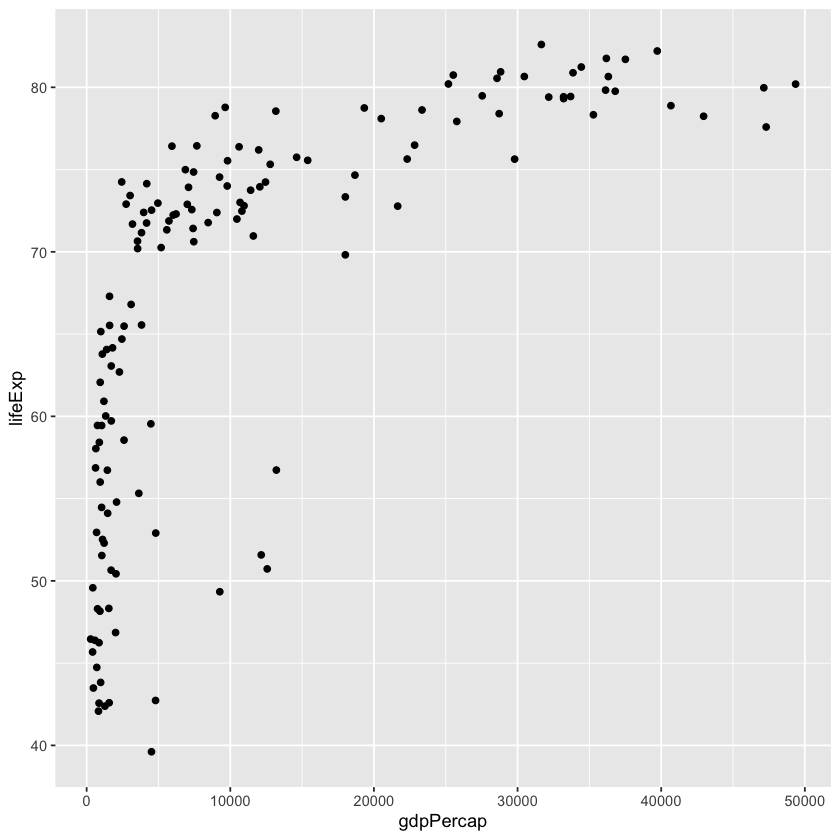

In [10]:
ggplot(gapminder_2007, aes(x = gdpPercap, y = lifeExp)) +
      geom_point()
#?geom_smooth

## Scatter plots

### What is a scatter plot?

A scatter plot (aka scatter chart, scatter graph) uses dots to represent values for two different numeric variables. 

The position of each dot on the horizontal and vertical axis indicates values for an individual data point. 

Scatter plots are used to observe relationships between variables such as GDP per capita and life expectancy in gapminder dataset.

### When you should use a scatter plot

Scatter plots’ primary uses are to observe and show relationships between two numeric variables. The dots in a scatter plot not only report the values of individual data points, but also patterns when the data are taken as a whole.

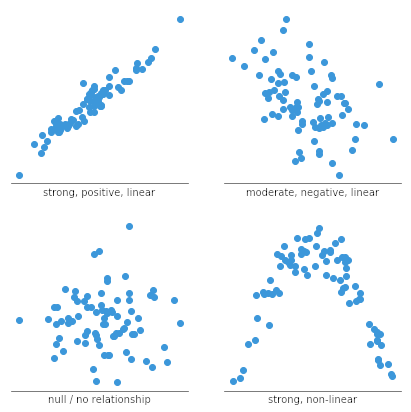

A scatter plot can also be useful for identifying other patterns in data. We can divide data points into groups based on how closely sets of points cluster together. Scatter plots can also show if there are any unexpected gaps in the data and if there are any outlier points. This can be useful if we want to segment the data into different parts.

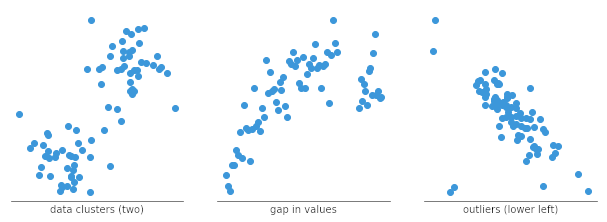

### Common issues when using scatter plots

This is not so much an issue with creating a scatter plot as it is an issue with its interpretation. Simply because we observe a relationship between two variables in a scatter plot, it does not mean that changes in one variable are responsible for changes in the other. This gives rise to the common phrase in statistics that <b>correlation does not imply causation</b>. It is possible that the observed relationship is driven by some third variable that affects both of the plotted variables, that the causal link is reversed, or that the pattern is simply coincidental.

### Common scatter plot options

#### Add a trend line

When a scatter plot is used to look at a predictive or correlational relationship between variables, it is common to add a trend line to the plot showing the mathematically best fit to the data. This can provide an additional signal as to how strong the relationship between the two variables is, and if there are any unusual points that are affecting the computation of the trend line.

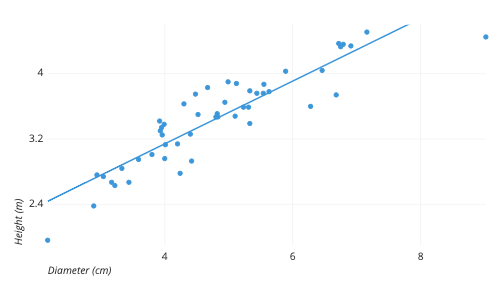

`geom_smooth()` using formula = 'y ~ x'


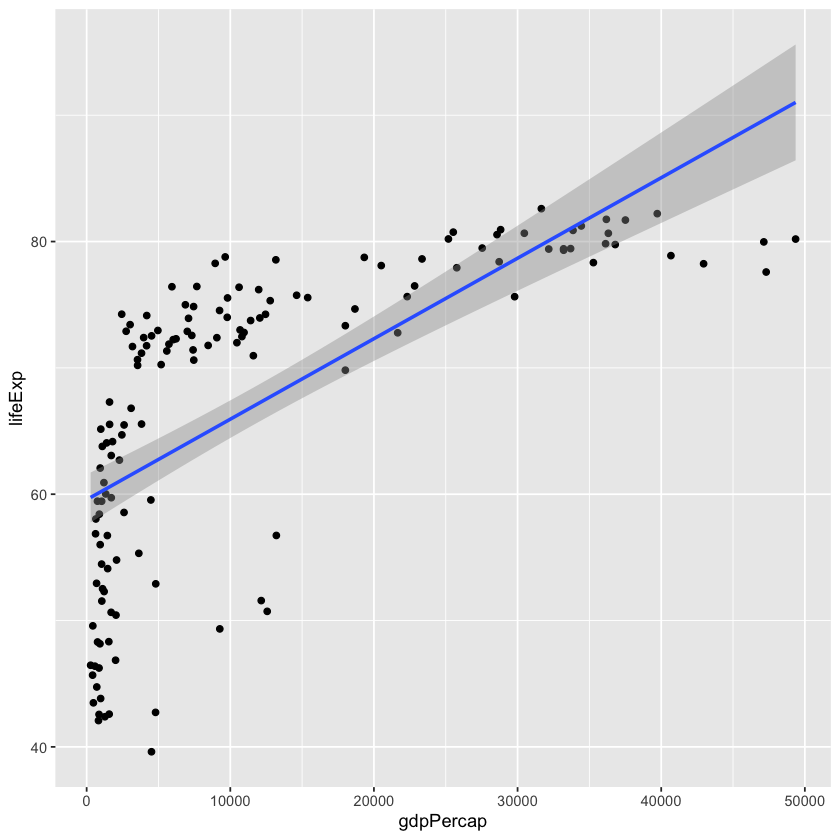

In [11]:
ggplot(gapminder_2007, aes(x = gdpPercap, y = lifeExp)) +
      geom_point() + 
    geom_smooth(method="lm")

#geom_smooth(method="lm")
#?geom_smooth

#### Categorical third variable

A common modification of the basic scatter plot is the addition of a third variable. Values of the third variable can be encoded by modifying how the points are plotted. For a third variable that indicates categorical values (like geographical region or gender), the most common encoding is through point color. Giving each point a distinct hue makes it easy to show membership of each point to a respective group.

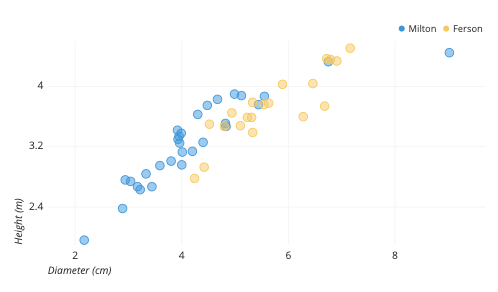

One other option that is sometimes seen for third-variable encoding is that of shape. One potential issue with shape is that different shapes can have different sizes and surface areas, which can have an effect on how groups are perceived. However, in certain cases where color cannot be used (like in print), shape may be the best option for distinguishing between groups.

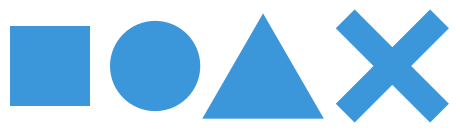

#### Numeric third variable

For third variables that have numeric values, a common encoding comes from changing the point size. A scatter plot with point size based on a third variable actually goes by a distinct name, the <b>bubble chart</b>. Larger points indicate higher values.

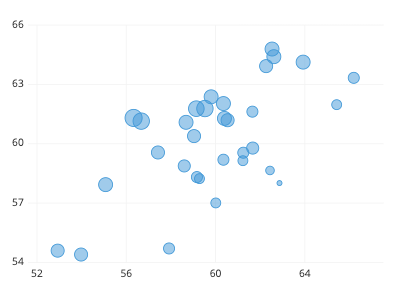

Another alternative. Rather than using distinct colors for points like in the categorical case, we want to use a continuous sequence of colors, so that, for example, darker colors indicate higher value. Note that, for both size and color, a legend is important for interpretation of the third variable, since our eyes are much less able to discern size and color as easily as position.

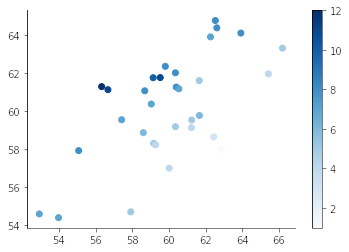

as homework, find out how to implement points 2.1.4.1 to 2.1.4.3 in ggplot

explore outliers

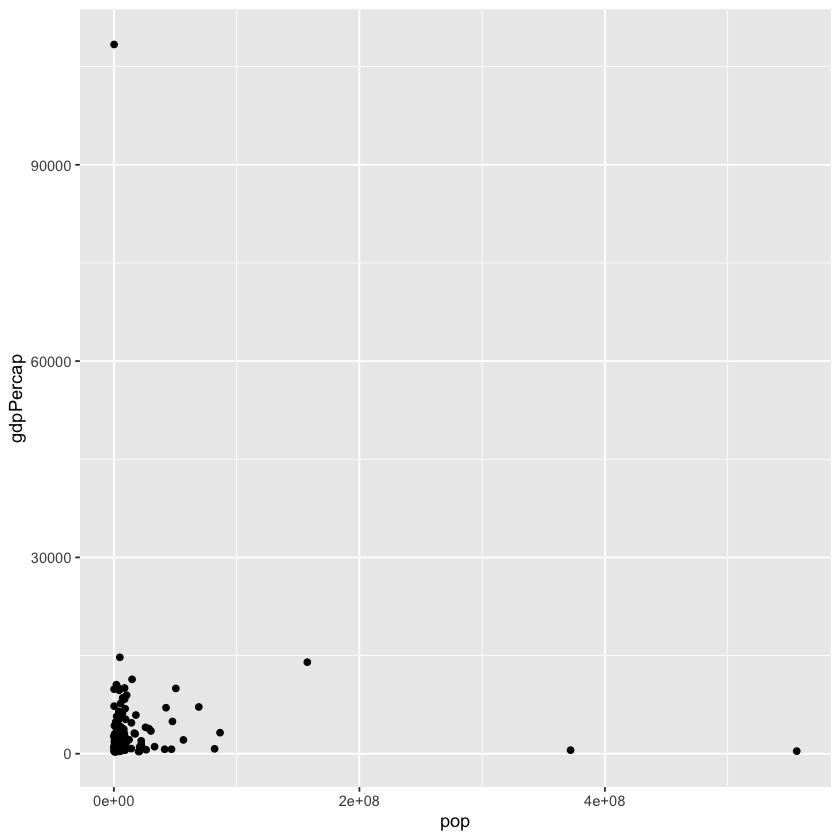

In [12]:
gapminder_1952 <- gapminder %>%
  filter(year == 1952)

# Change to put pop on the x-axis and gdpPercap on the y-axis
ggplot(gapminder_1952, aes(x = pop , y = gdpPercap)) +
  geom_point() 

## Logarithmic scales

Let plot comparing the GDP per capita of each country to its life expectancy.

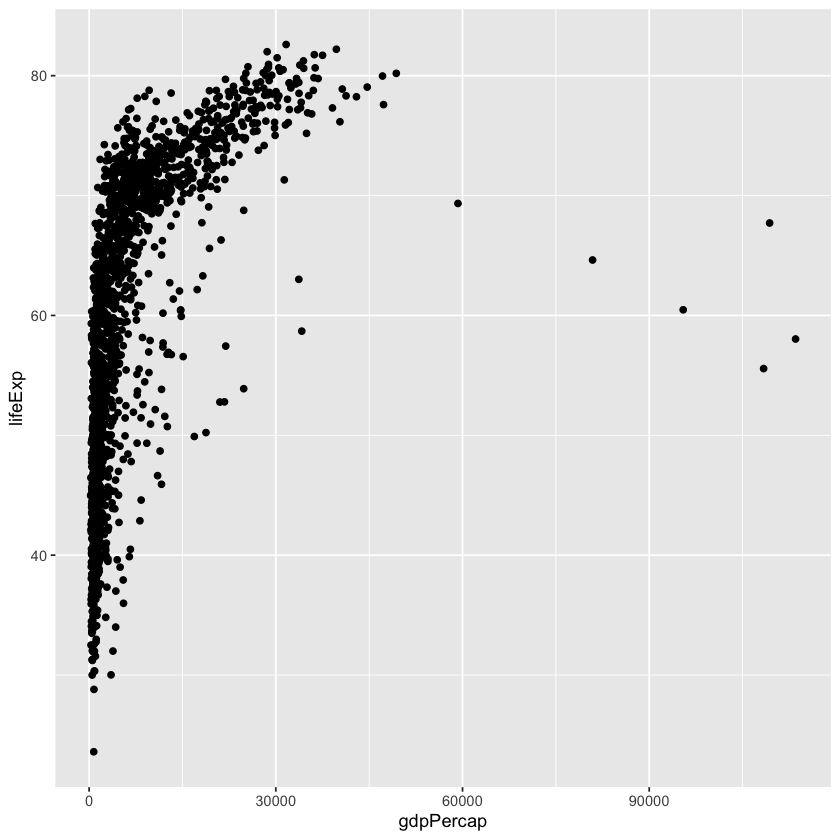

In [16]:
library(ggplot2)
library(gapminder)
library(dplyr)


ggplot(gapminder, aes(x = gdpPercap , y = lifeExp)) +
  geom_point()

 This plot communicates some interesting information: we can see that higher income countries tend to have higher life expectancy. One problem with this plot, however, is that a lot of countries get crammed into the leftmost part of the x-axis. This is because the distribution of GDP per capita spans several orders of magnitude, with some countries in the tens of thousands of dollars and others in the hundreds. When one of your axes has that kind of distribution, it's useful to work with a <b>logarithmic scale</b>
 
 
 https://www.youtube.com/watch?v=W_BZb_va6jY&list=WL&index=2

`geom_smooth()` using formula = 'y ~ x'


[1] 0.340713

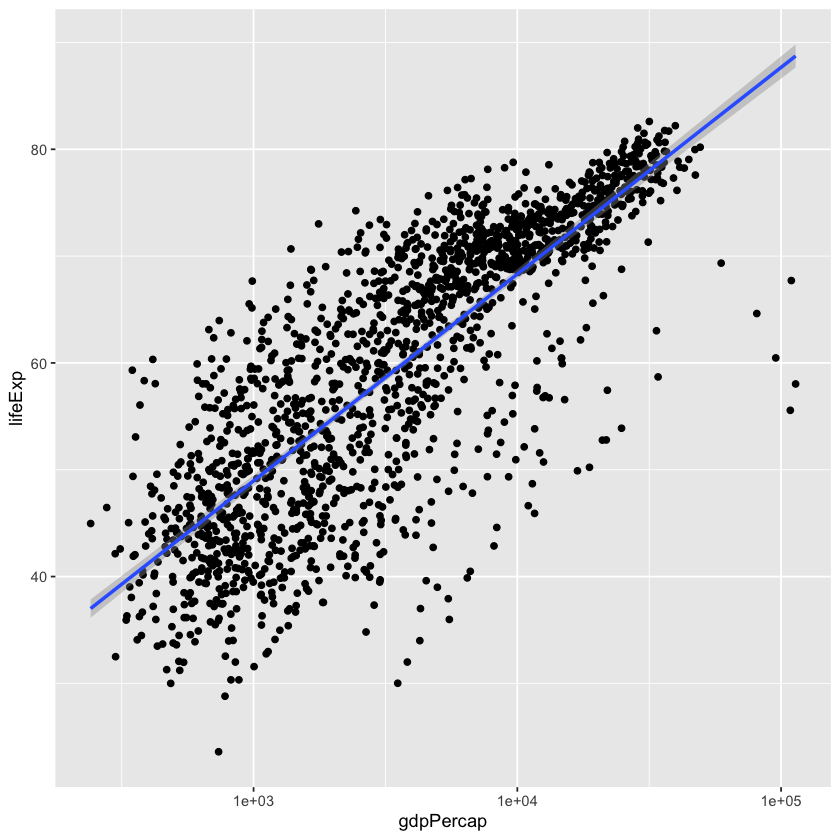

In [20]:
ggplot(gapminder, aes(x = gdpPercap , y = lifeExp)) +
  geom_point() +
scale_x_log10() +
geom_smooth(method="lm")

gdpPercap.lm = lm(gdpPercap ~ lifeExp, data=gapminder)

summary(gdpPercap.lm)$r.squared


On this scale, the relationship between GDP per capita and life expectancy looks more linear: and you can more easily distinguish the countries at the lower end of the spectrum.

### When should use Logarithmic scales?

There are one main reason to use logarithmic scales in charts and graphs:

* To respond to skewness towards large values; i.e., cases in which one or a few points are much larger than the bulk of the data. 

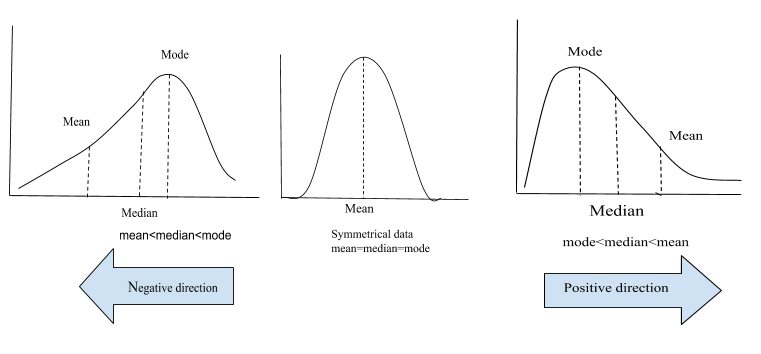


<b>It is extremely useful when graphing a large variance in data!.</b>

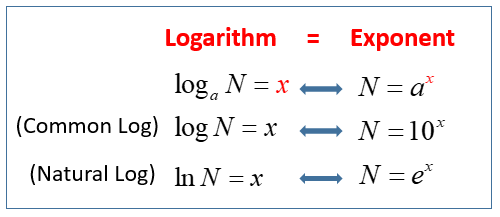

To refresh your memory of school math, logs are just another way of writing exponential equations, one that allows you to separate the exponent on one side of the equation. 

The equation: 
$$
x = log_{a} (N)
$$

means that <b>x</b> is the power or exponent that <b>a</b> is raised to in order to get <b>N</b>.

The common base for logarithmic scales is the base 10. However, other bases are also useful. While a base of ten is useful when the data range over several orders of magnitude.



## Additional aesthetics in ggplot2

Previously, we plot to compare two variables within your data using two visual aesthetics: GDP per capita on the x-axis, and life expectancy on the y-axis. 

But these aren't the only variables in the gapminder dataset: for example, you also have continent and population. You may want to examine relationships among all these variables in the same plot.

<b>You already used the x-axis to represent GDP per capita and the y-axis to represent life expectancy. Now you'll learn to add two more aesthetics- color and size- to communicate even more information in your scatter plot. 



In [1]:
library(gapminder)
library(dplyr)
library(ggplot2)
summary(gapminder)




Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




        country        continent        year         lifeExp     
 Afghanistan:  12   Africa  :624   Min.   :1952   Min.   :23.60  
 Albania    :  12   Americas:300   1st Qu.:1966   1st Qu.:48.20  
 Algeria    :  12   Asia    :396   Median :1980   Median :60.71  
 Angola     :  12   Europe  :360   Mean   :1980   Mean   :59.47  
 Argentina  :  12   Oceania : 24   3rd Qu.:1993   3rd Qu.:70.85  
 Australia  :  12                  Max.   :2007   Max.   :82.60  
 (Other)    :1632                                                
      pop              gdpPercap       
 Min.   :6.001e+04   Min.   :   241.2  
 1st Qu.:2.794e+06   1st Qu.:  1202.1  
 Median :7.024e+06   Median :  3531.8  
 Mean   :2.960e+07   Mean   :  7215.3  
 3rd Qu.:1.959e+07   3rd Qu.:  9325.5  
 Max.   :1.319e+09   Max.   :113523.1  
                                       

<b>Continent is a categorical variable: it has a few specific values, such as Asia and Europe. A good way to represent a categorical variable in a scatterplot is the color of your points.



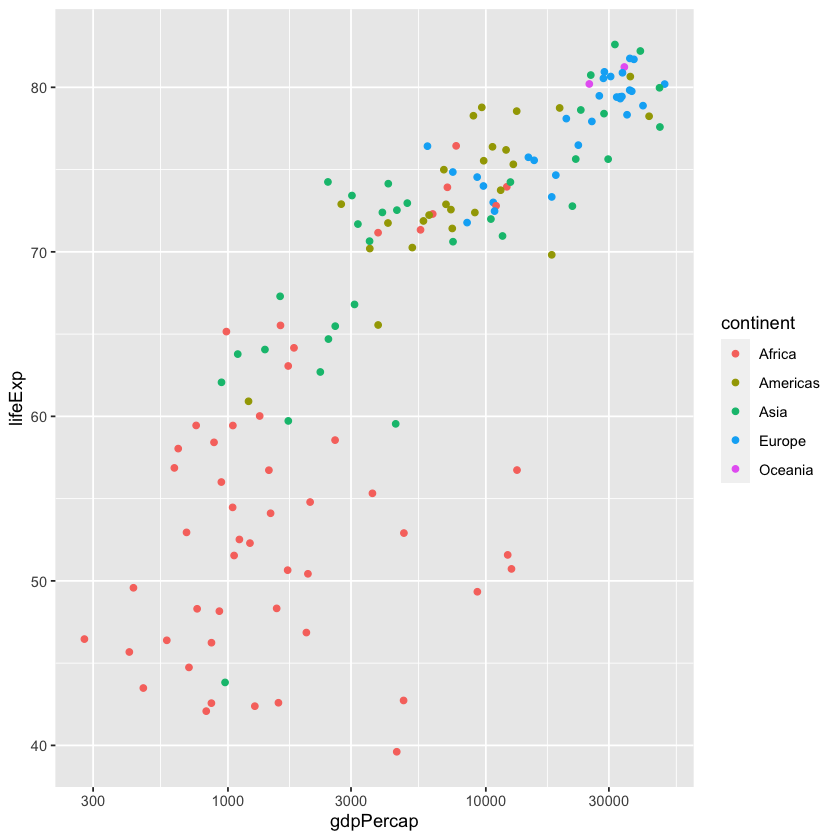

In [3]:
gapminder_2007 <- gapminder %>%
  filter(year == 2007)

# Change to put pop on the x-axis and gdpPercap on the y-axis
ggplot(gapminder_2007, aes(x = gdpPercap , y = lifeExp, color = continent)) +
  geom_point() +
scale_x_log10()

This communicates a lot about differences between continents. The average life expectancy and GDP per capita tends to be lowest for African countries, shown in red, and highest for European countries, shown in blue. 

<b>Another variable you may want to include in the graph is population, represented by the pop variable in the dataset. This is a numeric variable, so a good way to represent it is with the size of the points in the scatterplot.

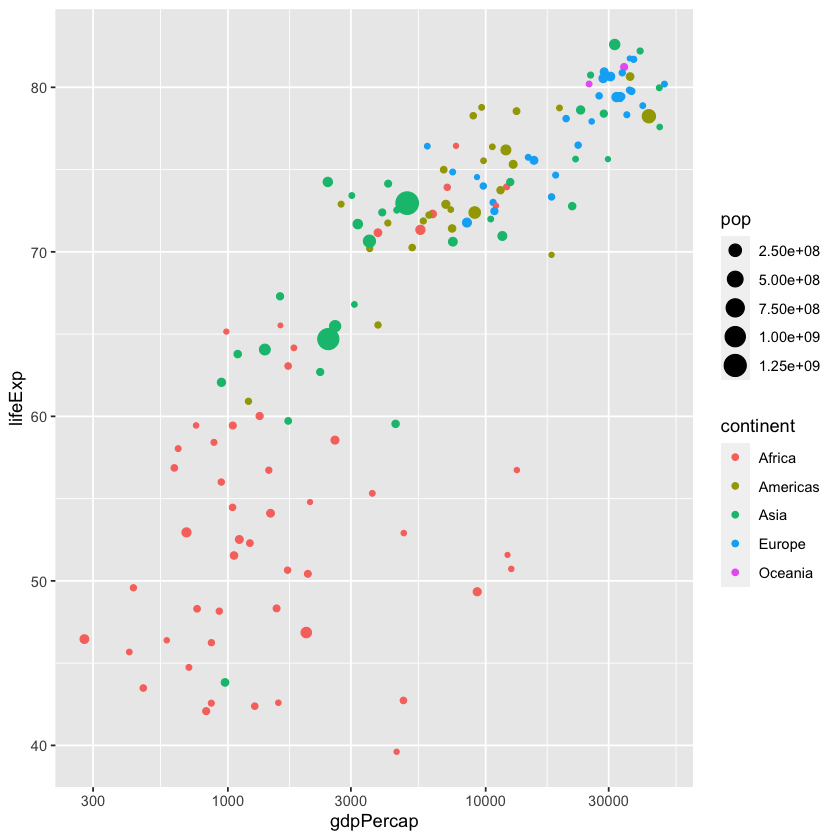

In [22]:
gapminder_2007 <- gapminder %>%
  filter(year == 2007)

# Change to put pop on the x-axis and gdpPercap on the y-axis
ggplot(gapminder_2007, aes(x = gdpPercap , y = lifeExp, color = continent, size = pop)) +
  geom_point() +
scale_x_log10()

<b>ggplot2 lets you divide your plot into subplots to get one smaller graph for each continent</b>: Africa, the Americas, and so on. This is called faceting, and it's another powerful way to communicate relationships within your data. 

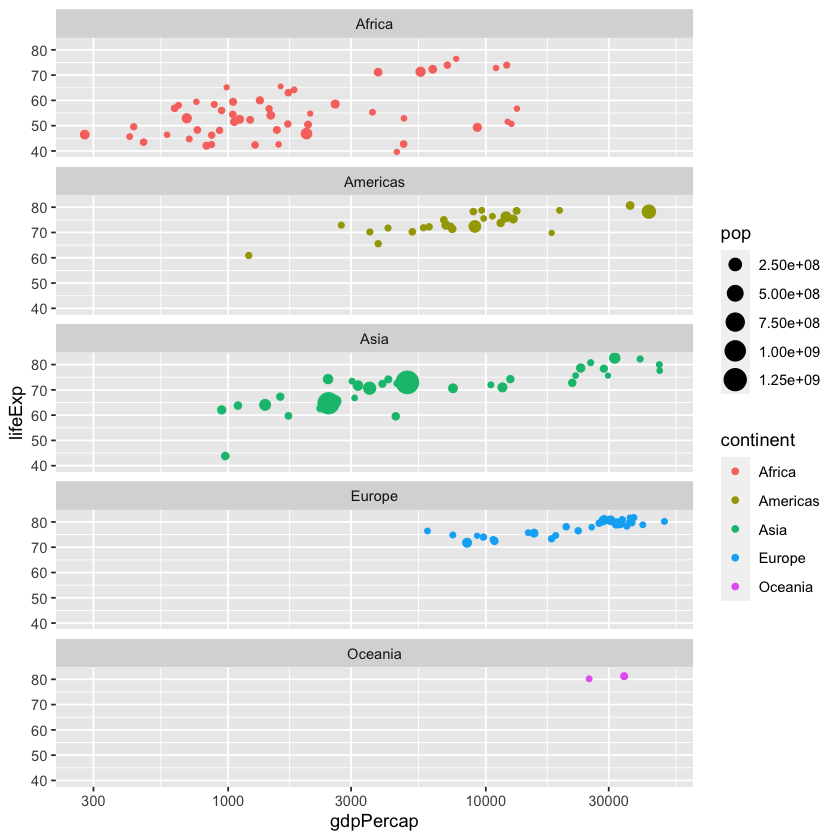

In [25]:
gapminder_2007 <- gapminder %>%
  filter(year == 2007)

# Change to put pop on the x-axis and gdpPercap on the y-axis
ggplot(gapminder_2007, aes(x = gdpPercap , y = lifeExp, color=continent, size = pop)) +
  geom_point() +
scale_x_log10() +
facet_wrap(~ continent, nrow=5, ncol=1)

In R, the tilde (~) symbol typically means "by"

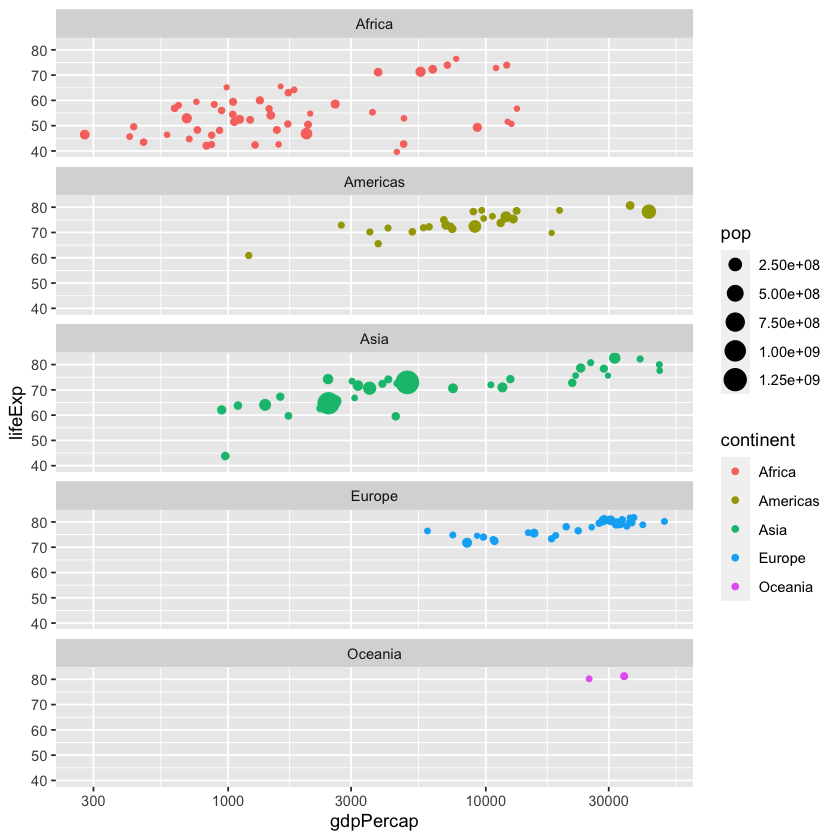

In [4]:
gapminder_2007 <- gapminder %>%
  filter(year == 2007)

# Change to put pop on the x-axis and gdpPercap on the y-axis
ggplot(gapminder_2007, aes(x = gdpPercap , y = lifeExp, color = continent, size = pop)) +
  geom_point() +
scale_x_log10() +
facet_wrap(~ continent, nrow=5, ncol=1)

In [22]:
a <- gapminder %>%
filter(gapminder$continent == "Africa") 

a <- a %>%
  mutate(pop_group = case_when(
    pop <= 3000000 ~ 1,
    pop > 3000000 & pop < 10000000 ~ 2,
    pop >= 10000000 ~ 3
  ))


a$pop_group <- as.factor(a$pop_group)
summary(a)

         country       continent        year         lifeExp     
 Algeria     : 12   Africa  :624   Min.   :1952   Min.   :23.60  
 Angola      : 12   Americas:  0   1st Qu.:1966   1st Qu.:42.37  
 Benin       : 12   Asia    :  0   Median :1980   Median :47.79  
 Botswana    : 12   Europe  :  0   Mean   :1980   Mean   :48.87  
 Burkina Faso: 12   Oceania :  0   3rd Qu.:1993   3rd Qu.:54.41  
 Burundi     : 12                  Max.   :2007   Max.   :76.44  
 (Other)     :552                                                
      pop              gdpPercap       pop_group
 Min.   :    60011   Min.   :  241.2   1:242    
 1st Qu.:  1342075   1st Qu.:  761.2   2:211    
 Median :  4579311   Median : 1192.1   3:171    
 Mean   :  9916003   Mean   : 2193.8            
 3rd Qu.: 10801490   3rd Qu.: 2377.4            
 Max.   :135031164   Max.   :21951.2            
                                                

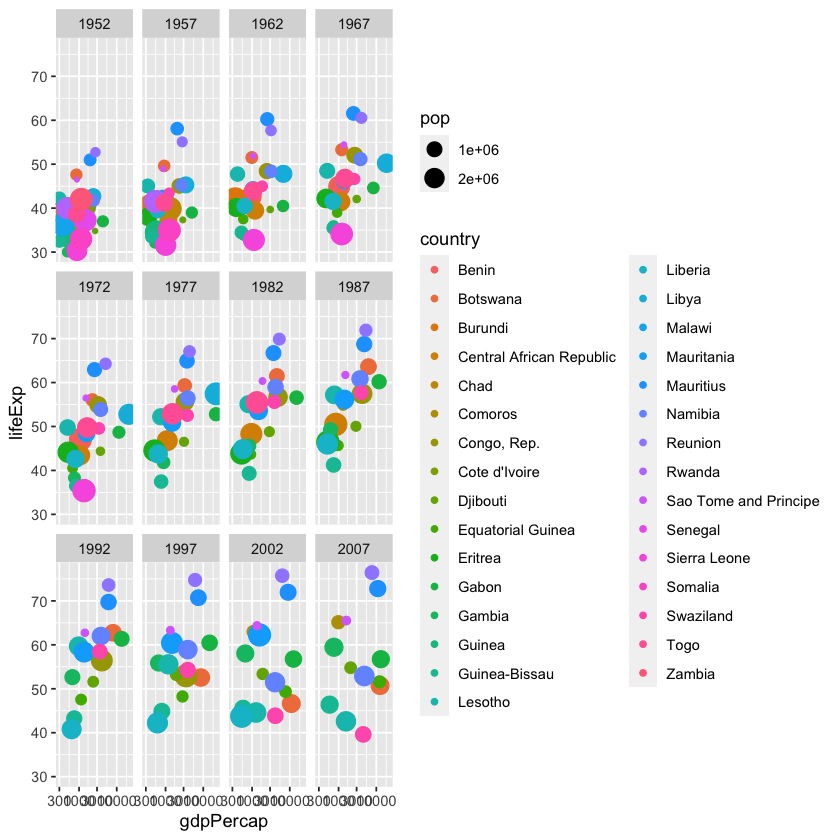

In [25]:
b <- a %>%
filter(pop_group == "1")

ggplot(b, aes(x = gdpPercap , y = lifeExp, color = country, size = pop)) +
  geom_point() +
scale_x_log10() +
facet_wrap(~ year)



In [19]:
summary(gapminder)
str(gapminder)
glimpse(gapminder)

        country        continent        year         lifeExp     
 Afghanistan:  12   Africa  :624   Min.   :1952   Min.   :23.60  
 Albania    :  12   Americas:300   1st Qu.:1966   1st Qu.:48.20  
 Algeria    :  12   Asia    :396   Median :1980   Median :60.71  
 Angola     :  12   Europe  :360   Mean   :1980   Mean   :59.47  
 Argentina  :  12   Oceania : 24   3rd Qu.:1993   3rd Qu.:70.85  
 Australia  :  12                  Max.   :2007   Max.   :82.60  
 (Other)    :1632                                                
      pop              gdpPercap       
 Min.   :6.001e+04   Min.   :   241.2  
 1st Qu.:2.794e+06   1st Qu.:  1202.1  
 Median :7.024e+06   Median :  3531.8  
 Mean   :2.960e+07   Mean   :  7215.3  
 3rd Qu.:1.959e+07   3rd Qu.:  9325.5  
 Max.   :1.319e+09   Max.   :113523.1  
                                       

tibble [1,704 × 6] (S3: tbl_df/tbl/data.frame)
 $ country  : Factor w/ 142 levels "Afghanistan",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ continent: Factor w/ 5 levels "Africa","Americas",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ year     : int [1:1704] 1952 1957 1962 1967 1972 1977 1982 1987 1992 1997 ...
 $ lifeExp  : num [1:1704] 28.8 30.3 32 34 36.1 ...
 $ pop      : int [1:1704] 8425333 9240934 10267083 11537966 13079460 14880372 12881816 13867957 16317921 22227415 ...
 $ gdpPercap: num [1:1704] 779 821 853 836 740 ...
Rows: 1,704
Columns: 6
$ country   <fct> "Afghanistan", "Afghanistan", "Afghanistan", "Afghanistan", …
$ continent <fct> Asia, Asia, Asia, Asia, Asia, Asia, Asia, Asia, Asia, Asia, …
$ year      <int> 1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, …
$ lifeExp   <dbl> 28.801, 30.332, 31.997, 34.020, 36.088, 38.438, 39.854, 40.8…
$ pop       <int> 8425333, 9240934, 10267083, 11537966, 13079460, 14880372, 12…
$ gdpPercap <dbl> 779.4453, 820.8530, 853.1007, 836.1971, 739.9811, 7

# Continue with Tidyverse (dplyr)

## Summarize()

Analyses will usually involve a cycle between these steps of data transformation and visualization, as well as additional components of the data science workflow.

Now you'll learn how to <b>summarize</b> many observations into a single data point.

For example, suppose you want to know the average life expectancy across all countries and years in the dataset. You would do this with the <b>summarize</b> function.

In [ ]:
gapminder

In [26]:
library(ggplot2)
library(gapminder)
library(dplyr)

gapminder %>% 
summarize(meanLifeExp = mean(lifeExp))

meanLifeExp
<dbl>
59.47444


In the output, we see the answer to our question: the mean life expectancy was about 59.47 years.

If you think about it, it doesn't really make sense to summarize across all countries and across all years. It may make more sense to ask questions about averages in a particular year, such as 2007.

To answer this, you can combine the summarize verb with filter: filter your data for a particular year first, then summarize the result.

In [27]:
gapminder %>%
filter(year == 2007) %>%
summarise(meanLifeExp = mean(lifeExp))

meanLifeExp
<dbl>
67.00742


 This shows you that the average life expectancy in the year 2007 was about 67 years.

You can create multiple summaries at once with the summarize. For example, suppose that along with finding the average life expectancy in 2007, you want to find the total population in that year.

In [29]:
gapminder %>%
filter(year == 2007) %>%
summarise(meanLifeExp = mean(lifeExp),
         totalpop = sum(as.numeric(pop))
         )

meanLifeExp,totalpop
<dbl>,<dbl>
67.00742,6251013179


In [ ]:
str(gapminder)

In [30]:
help(summarise)
?summarise

<b>Useful functions</b>

* Center: mean(), median()

* Spread: sd(), IQR(), mad()

* Range: min(), max(), quantile()

* Position: first(), last(), nth(),

* Count: n(), n_distinct()

* Logical: any(), all()



## Group_by()

We use the <b>summarize</b> function to answer questions about the entire dataset, or about a particular year. For example, here you're finding the average life expectancy and the total population in the year 2007. 

<b>What if we weren't interested just in the average for the year 2007, but for each of the years in the dataset? </b>

You could rerun this code and change the year each time, but that's very tedious...or

we can use the <b>group_by</b> function

In [6]:
head(gapminder)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134


In [32]:
gapminder %>%
group_by(year, continent) %>%
summarise(meanLifeExp = mean(lifeExp),
         totalpop = sum(as.numeric(pop)))

`summarise()` has grouped output by 'year'. You can override using the `.groups` argument.


year,continent,meanLifeExp,totalpop
<int>,<fct>,<dbl>,<dbl>
1952,Africa,39.13550,237640501
1952,Americas,53.27984,345152446
1952,Asia,46.31439,1395357351
1952,Europe,64.40850,418120846
1952,Oceania,69.25500,10686006
1957,Africa,41.26635,264837738
1957,Americas,55.96028,386953916
1957,Asia,49.31854,1562780599
1957,Europe,66.70307,437890351


This shows us that the total population started at 2.4 billion, and went up to 6.25 billion in 2007. 

We can also see that average life expectancy went up from 49 years in 1952 to 67 in 2007.

How to determinate the average life expectancy and the total population in 2007 within each continent.

In [33]:
gapminder %>%
filter(year == 1952) %>%
group_by(continent) %>%
summarise(meanLifeExp = mean(lifeExp),
         totalpop = sum(as.numeric(pop)))

continent,meanLifeExp,totalpop
<fct>,<dbl>,<dbl>
Africa,39.13550,237640501
Americas,53.27984,345152446
Asia,46.31439,1395357351
Europe,64.40850,418120846
Oceania,69.25500,10686006


We can see that Europe and Oceania have the highest life expectancy, and that Asia and Africa are lower. 

Now that you've calculated these statistics for each continent in 2007, you might be interested in how they changed for each continent over time.

In [11]:
gapminder %>%
group_by(continent, year) %>%
summarise(meanLifeExp = mean(lifeExp),
         totalpop = sum(as.numeric(pop)))

`summarise()` has grouped output by 'continent'. You can override using the `.groups` argument.



continent,year,meanLifeExp,totalpop
<fct>,<int>,<dbl>,<dbl>
Africa,1952,39.13550,237640501
Africa,1957,41.26635,264837738
Africa,1962,43.31944,296516865
Africa,1967,45.33454,335289489
Africa,1972,47.45094,379879541
Africa,1977,49.58042,433061021
Africa,1982,51.59287,499348587
Africa,1987,53.34479,574834110
Africa,1992,53.62958,659081517


## Slice()

slice() lets you index rows by their (integer) locations. It allows you to select, remove, and duplicate rows. It is accompanied by a number of helpers for common use cases:

<b>slice_head() and slice_tail()</b> select the first or last rows.

<b>slice_sample()</b> randomly selects rows.

<b>slice_min() and slice_max()</b> select rows with the smallest or largest values of a variable.

In [50]:
gapminder %>%
group_by(continent) %>% 
slice_head(n = 2)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134
Afghanistan,Asia,1982,39.854,12881816,978.0114
Afghanistan,Asia,1987,40.822,13867957,852.3959
Afghanistan,Asia,1992,41.674,16317921,649.3414


In [51]:
gapminder %>%
group_by(continent) %>% 
slice_tail(n = 2)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Zimbabwe,Africa,2002,39.989,11926563,672.0386
Zimbabwe,Africa,2007,43.487,12311143,469.7093
Venezuela,Americas,2002,72.766,24287670,8605.0478
Venezuela,Americas,2007,73.747,26084662,11415.8057
"Yemen, Rep.",Asia,2002,60.308,18701257,2234.8208
"Yemen, Rep.",Asia,2007,62.698,22211743,2280.7699
United Kingdom,Europe,2002,78.471,59912431,29478.9992
United Kingdom,Europe,2007,79.425,60776238,33203.2613
New Zealand,Oceania,2002,79.110,3908037,23189.8014


In [54]:
gapminder %>%
group_by(continent) %>% 
slice_min(pop, n = 1)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Sao Tome and Principe,Africa,1952,46.471,60011,879.5836
Trinidad and Tobago,Americas,1952,59.100,662850,3023.2719
Bahrain,Asia,1952,50.939,120447,9867.0848
Iceland,Europe,1952,72.490,147962,7267.6884
New Zealand,Oceania,1952,69.390,1994794,10556.5757


In [55]:
gapminder %>%
group_by(continent) %>% 
slice_max(pop, n = 1)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Nigeria,Africa,2007,46.859,135031164,2013.977
United States,Americas,2007,78.242,301139947,42951.653
China,Asia,2007,72.961,1318683096,4959.115
Germany,Europe,2007,79.406,82400996,32170.374
Australia,Oceania,2007,81.235,20434176,34435.367


The <b>slice_sample()</b> function in the dplyr package is used to randomly sample rows from a data frame. It is useful when you want to obtain a random subset of rows from your data. 

In [60]:
gapminder %>%
group_by(continent) %>% 
slice_sample(n = 3, replace = TRUE)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Kenya,Africa,1952,42.270,6464046,853.5409
Mozambique,Africa,1952,31.286,6446316,468.5260
Tanzania,Africa,1957,42.974,9452826,698.5356
Chile,Americas,1977,67.052,10599793,4756.7638
Cuba,Americas,1952,59.421,6007797,5586.5388
Bolivia,Americas,2007,65.554,9119152,3822.1371
Thailand,Asia,2007,70.616,65068149,7458.3963
Iraq,Asia,1962,51.457,7240260,8341.7378
Indonesia,Asia,1977,52.702,136725000,1382.7021


# Visualizing summarized data


In [34]:
by_year <- gapminder %>%
group_by(year) %>%
summarise(meanLifeExp = mean(lifeExp),
         totalpop = sum(as.numeric(pop)))

by_year

year,meanLifeExp,totalpop
<int>,<dbl>,<dbl>
1952,49.05762,2406957150
1957,51.50740,2664404580
1962,53.60925,2899782974
1967,55.67829,3217478384
1972,57.64739,3576977158
1977,59.57016,3930045807
1982,61.53320,4289436840
1987,63.21261,4691477418
1992,64.16034,5110710260


`geom_smooth()` using formula = 'y ~ x'


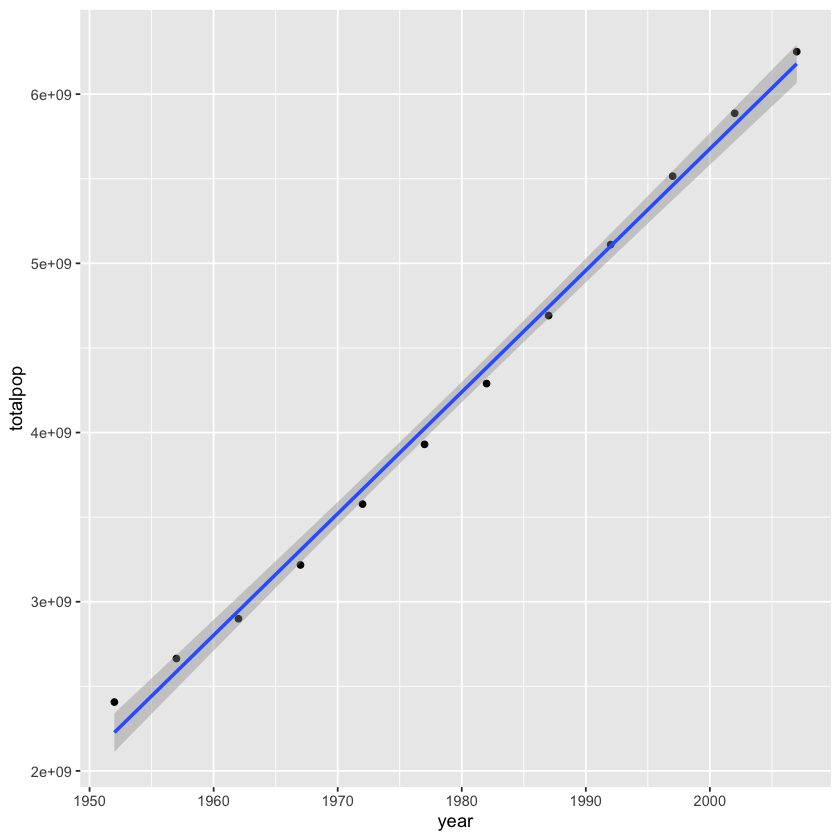

In [35]:
ggplot(by_year, aes(x = year, y = totalpop)) +
geom_point()+
geom_smooth(method="lm")

The resulting graph of population by year shows the change in the total population, which is going up over time. <b>ggplot2 puts the y-axis is in scientific notation, since showing it with nine zeros would be hard to read. 

`geom_smooth()` using formula 'y ~ x'



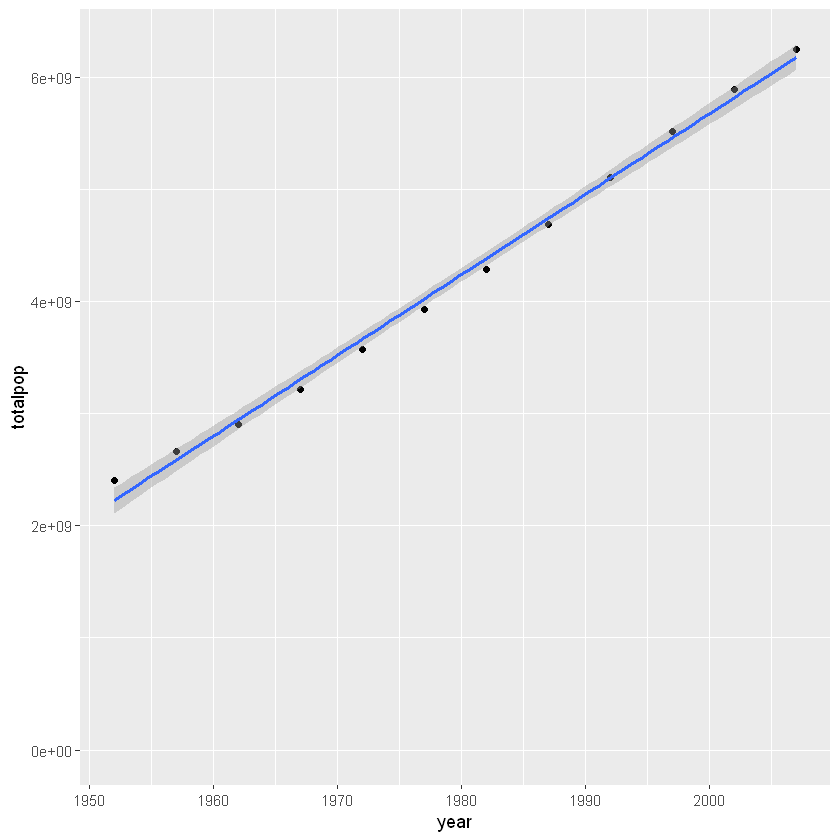

In [14]:
ggplot(by_year, aes(x = year, y = totalpop)) +
geom_point() +
expand_limits(y = 0) +
geom_smooth(method="lm")

`summarise()` has grouped output by 'year'. You can override using the `.groups` argument.


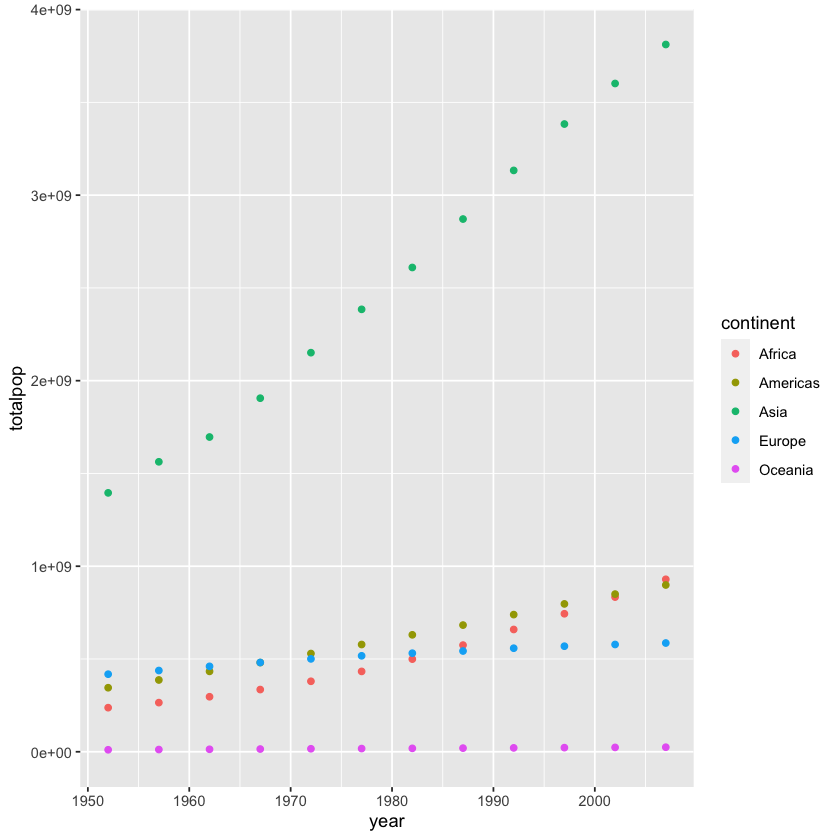

In [36]:
library(ggplot2)
library(gapminder)
library(dplyr)


by_year_continent <- gapminder %>%
group_by(year, continent) %>%
summarise(meanLifeExp = mean(lifeExp),
         totalpop = sum(as.numeric(pop)))

#by_year_continent

ggplot(by_year_continent, aes(x = year, y = totalpop, color = continent)) +
geom_point() +
expand_limits(y = 0) 

This lets us see that Asia was always the most populated continent and has been growing the most rapidly, that Oceania has a slower rate of growth, and that Africa has grown to surpass both Europe and the Americas in terms of population. 

year,medianLifeExp,maxGdpPercap
<int>,<dbl>,<dbl>
1952,45.1355,108382.35
1957,48.3605,113523.13
1962,50.8810,95458.11
1967,53.8250,80894.88
1972,56.5300,109347.87
1977,59.6720,59265.48
1982,62.4415,33693.18
1987,65.8340,31540.97
1992,67.7030,34932.92


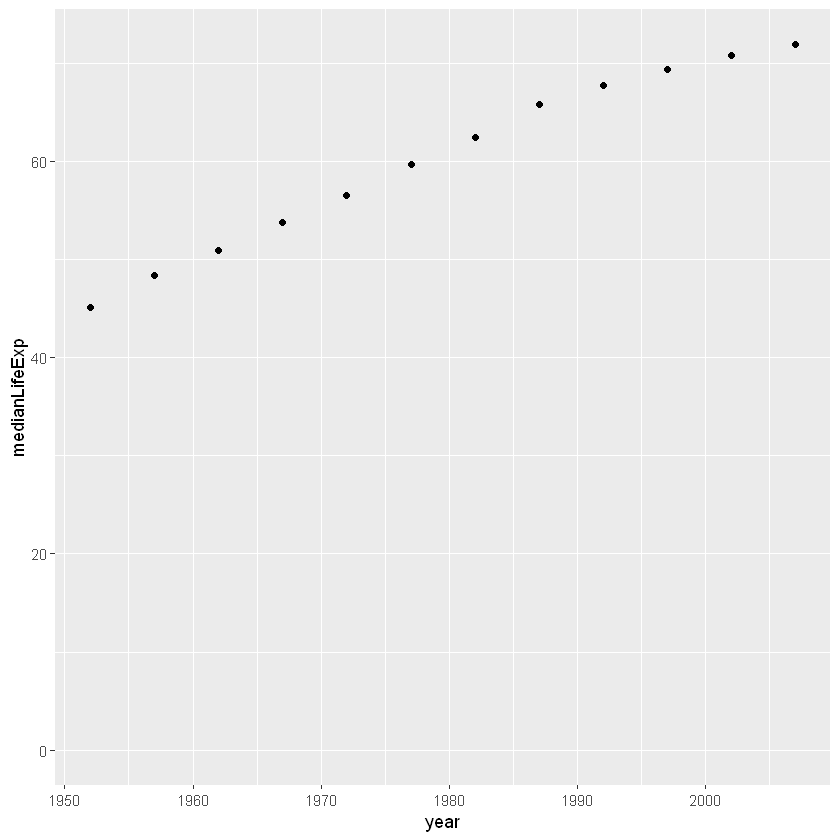

In [17]:
by_year <- gapminder %>%
  group_by(year) %>%
  summarize(medianLifeExp = median(lifeExp),
            maxGdpPercap = max(gdpPercap))

by_year

ggplot(by_year, aes(x = year, y = medianLifeExp)) +
geom_point() +
expand_limits(y = 0)

`summarise()` has grouped output by 'continent'. You can override using the `.groups` argument.



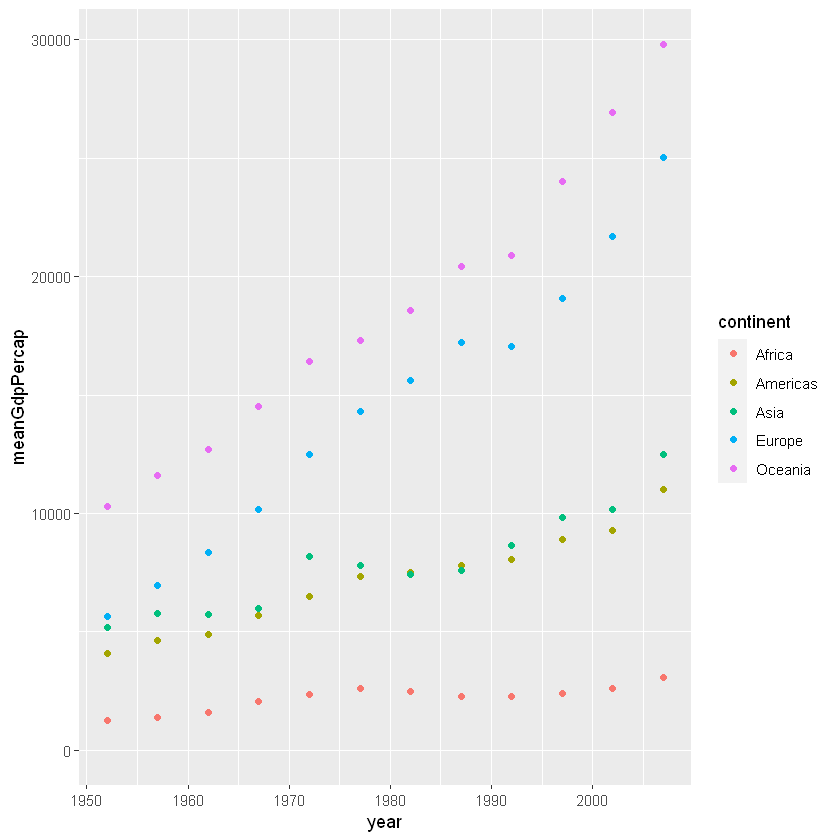

In [18]:
by_year_continent <- gapminder %>%
  group_by(continent, year) %>%
  summarize(meanGdpPercap = mean(gdpPercap))

ggplot(by_year_continent, aes(x = year, y = meanGdpPercap, color = continent)) +
geom_point() +
expand_limits(y = 0)

continent,medianLifeExp,medianGdpPercap
<fct>,<dbl>,<dbl>
Africa,52.9265,1452.267
Americas,72.8990,8948.103
Asia,72.3960,4471.062
Europe,78.6085,28054.066
Oceania,80.7195,29810.188


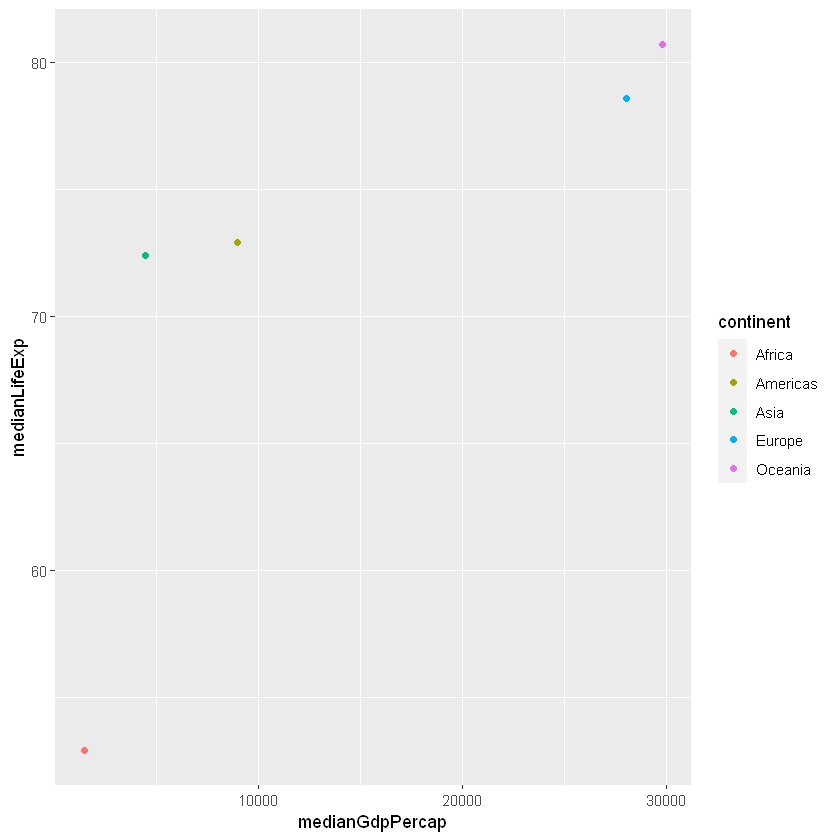

In [19]:
by_continent_2007 <- gapminder %>%
filter(year == 2007) %>%
  group_by(continent) %>%
  summarize( medianLifeExp = median(lifeExp),
      medianGdpPercap = median(gdpPercap))

by_continent_2007

ggplot(by_continent_2007, aes(x = medianGdpPercap, y = medianLifeExp, color = continent)) +
geom_point() 

# Types of visualizations


In [28]:
library(ggplot2)
library(gapminder)
library(dplyr)

## Line plots

Line plots, which are useful for showing change over time. 


### What is a line plot?

A line chart (aka line plot, line graph) uses points connected by line segments from left to right to demonstrate changes in value. The horizontal axis depicts a continuous progression, often that of time, while the vertical axis reports values for a metric of interest across that progression.

### When you should use a line plot?

You will use a line chart when you want to emphasize changes in values for one variable (plotted on the vertical axis) for continuous values of a second variable (plotted on the horizontal). This emphasis on patterns of change is sold by line segments moving consistently from left to right and observing the slopes of the lines moving up or down.

<b>On the horizontal axis, you need a variable that depicts continuous values that have a regular interval of measurement</b>. Very commonly, this variable is a temporal one, generating an observation every minute, hour, day, week, or month. The choice of interval size, or bin, is a decision that the analyst will usually need to make for the data.

<b>On the vertical axis, you will report the value of a second numeric variable</b> for points that fall in each of the intervals defined by the horizontal-axis variable. Often, this will be a statistical summary like a total or average value across events within each bin.

<b>Multiple lines can also be plotted in a single line chart to compare the trend between series</b>. A common use case for this is to observe the breakdown of the data across different subgroups. The ability to plot multiple lines also provides the line chart a special use case where it might not usually be selected. Normally, we would use a histogram to depict the frequency distribution of a single numeric variable. However, since it’s tricky to plot two histograms on the same set of axes, the line chart serves as a good mode of comparison as a substitute.

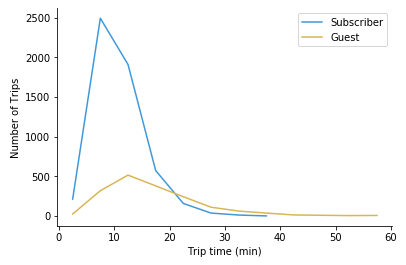

To use a line chart, data often needs to be aggregated into a table with two or more columns. Values in the first column indicate positions for points on the horizontal axis for each line to be plotted. Each following column indicates the vertical position for points of a single line.

In [20]:
library(gapminder)
library(dplyr)
#gapminder


gapminder %>%
filter(country == "Chile") 

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Chile,Americas,1952,54.745,6377619,3939.979
Chile,Americas,1957,56.074,7048426,4315.623
Chile,Americas,1962,57.924,7961258,4519.094
Chile,Americas,1967,60.523,8858908,5106.654
Chile,Americas,1972,63.441,9717524,5494.024
Chile,Americas,1977,67.052,10599793,4756.764
Chile,Americas,1982,70.565,11487112,5095.666
Chile,Americas,1987,72.492,12463354,5547.064
Chile,Americas,1992,74.126,13572994,7596.126


### Choose an appropriate measurement interval

An important aspect of creating a line chart is selecting the right interval or bin size. For temporal data, a too-broad of a measurement interval may mean that it takes too long to see where the data trend is leading, hiding away the useful signal. On the flip side of the coin, a too-short a measurement interval may only reveal noise rather than signal.

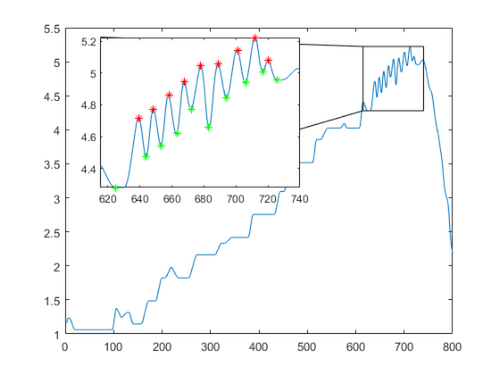

### Don’t plot too many lines

While there is the technical capacity to put many lines onto a single line chart, it is a good idea to be judicious in the amount of data that you plot. A good rule of thumb is to limit yourself to five or fewer lines.

If you find the need to plot more lines than can be read in a single axis, then you might consider faceting the plots into a grid of smaller line charts. It will be more difficult to see details in these plots, so it’s a good idea to sort them by some important characteristic (like average or final value) to help draw out important points. If you are using a tool that allows for interactive plots.

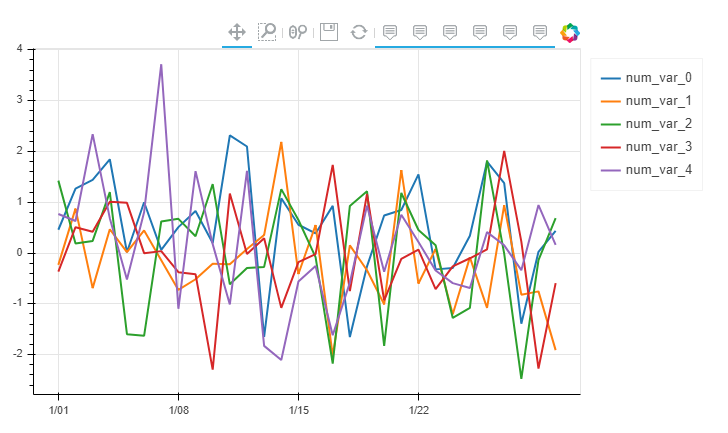

### Strictly using a zero-value baseline

Despite the zero baseline for the vertical axis being a requirement for bar charts and histograms, you do not need to include a zero baseline for a line chart. Recall that the main goal of a line chart is to emphasize changes in value, rather than the magnitude of the values themselves. In cases where a zero line is not meaningful or useful, it’s fine to zoom the vertical axis range into what will make the changes in value most informative.

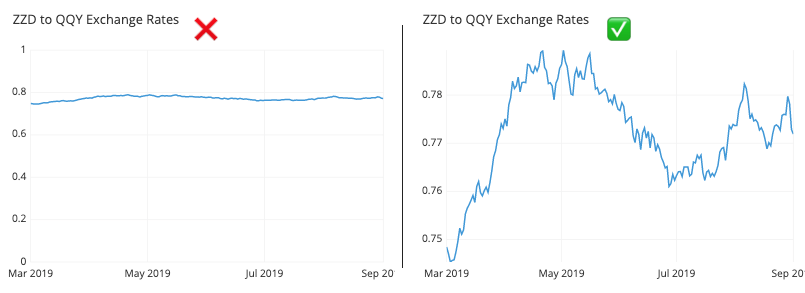

### Failing to identify uneven gaps between points

When the line chart is missing information for certain bins, gaps in the record may be interpreted as phantom values if the line does not include distinct dots at each observation. When there aren’t many points to plot, try showing all of the points and not just the line. If including the points would muddy up the interpretability of the plot, another alternative is to include a gap in the line to show where there are missing values.

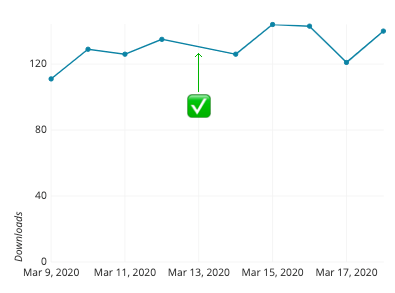

### Using a misleading dual axis

Examples of line charts with multiple lines have thus far had each line be part of the same domain, and thus plottable on the same axis. There’s nothing that limits each line to depict values on the same units, however. When a line plot includes two series, each depicting a summary of a different variable, then we end up with a dual axis plot.

The problem with a dual-axis plot is that it can easily be manipulated to be misleading. Depending on how each axis is scaled, the perceived relationship between the two lines can be changed.


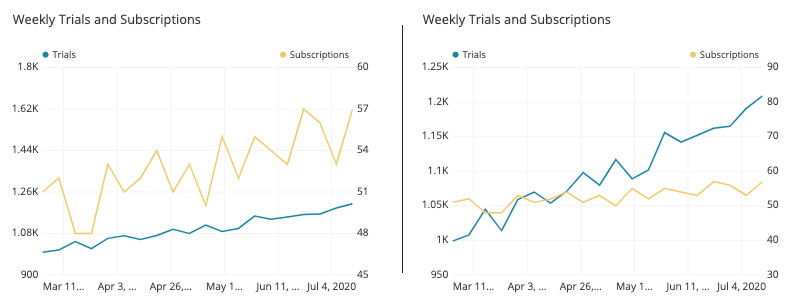








Instead, faceting the two lines into separate plots still allows for the general patterns of change to be observed for both variables, while reducing the temptations to compare them in misleading ways.

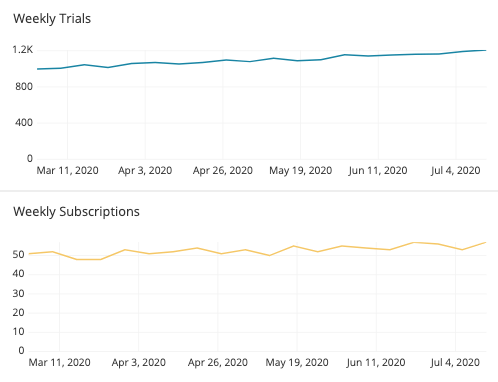

### let us go back to the code in R!

`summarise()` has grouped output by 'continent'. You can override using the `.groups` argument.



continent,year,medianGdpPercap
<fct>,<int>,<dbl>
Africa,1952,987.0256
Africa,1957,1024.0230
Africa,1962,1133.7837
Africa,1967,1210.3764
Africa,1972,1443.3725
Africa,1977,1399.6388
Africa,1982,1323.7283
Africa,1987,1219.5856
Africa,1992,1161.6314


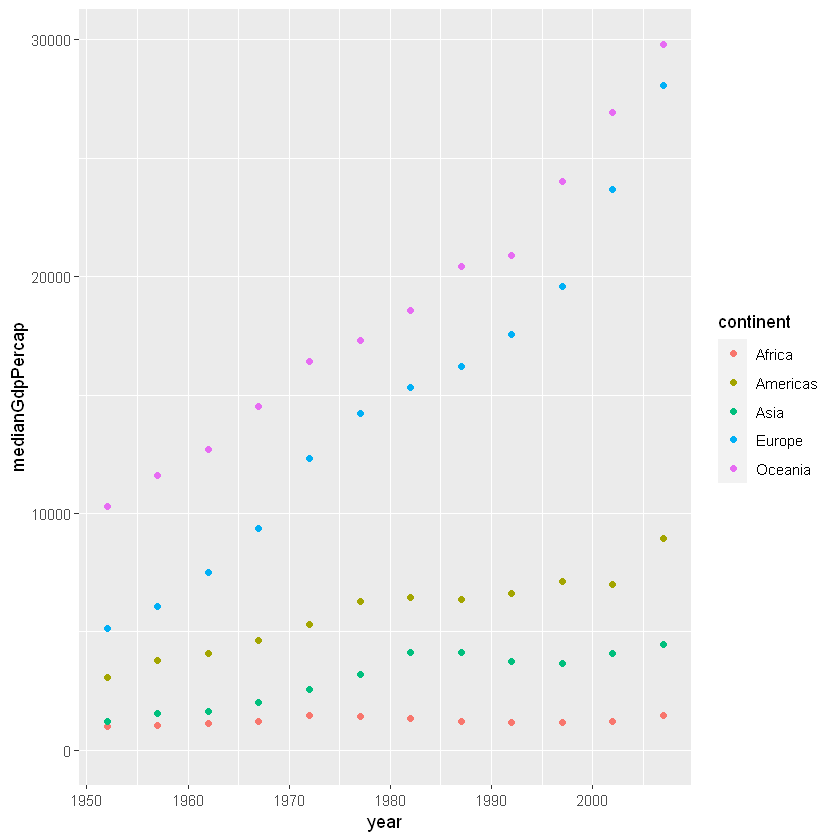

In [21]:
library(ggplot2)
library(gapminder)
library(dplyr)


by_year_continent <- gapminder %>%
  group_by(continent, year) %>%
  summarize(medianGdpPercap = median(gdpPercap))

by_year_continent


ggplot(by_year_continent, aes(x = year, y = medianGdpPercap, color = continent)) +
geom_point() +
expand_limits(y = 0)

`summarise()` has grouped output by 'continent'. You can override using the `.groups` argument.



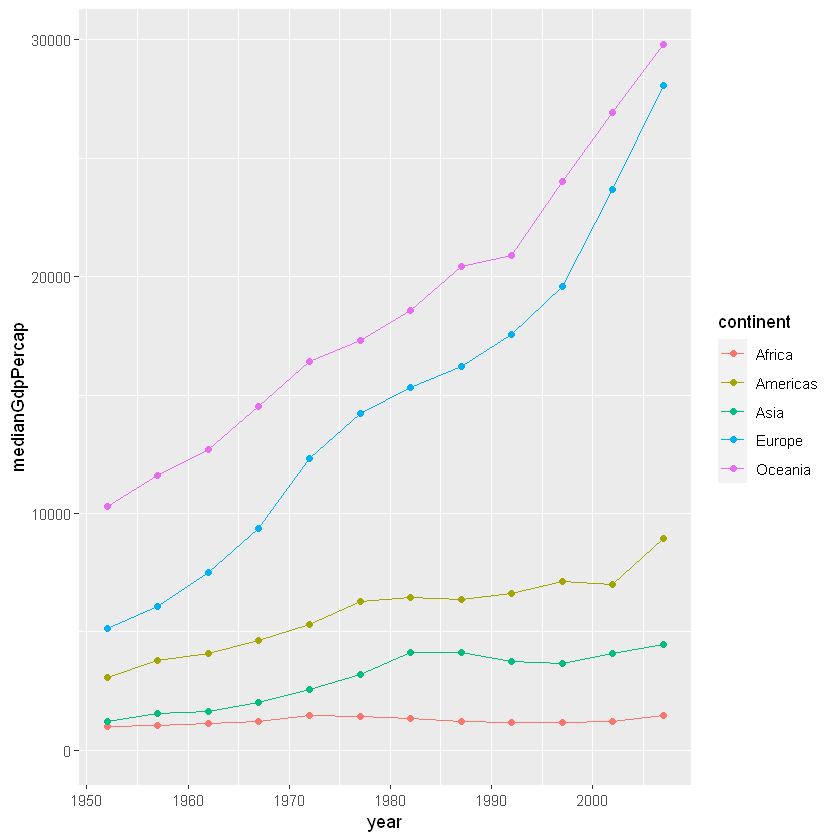

In [22]:
library(ggplot2)
library(gapminder)
library(dplyr)


by_year_continent <- gapminder %>%
  group_by(continent, year) %>%
  summarize(medianGdpPercap = median(gdpPercap))

ggplot(by_year_continent, aes(x = year, y = medianGdpPercap, color = continent)) +
geom_line() +
geom_point() +
expand_limits(y = 0) 

it's a bit easier to understand as a line plot, where the observations within each continent are connected. This makes it clearer that what we care about is the upward or downward trend over time. 

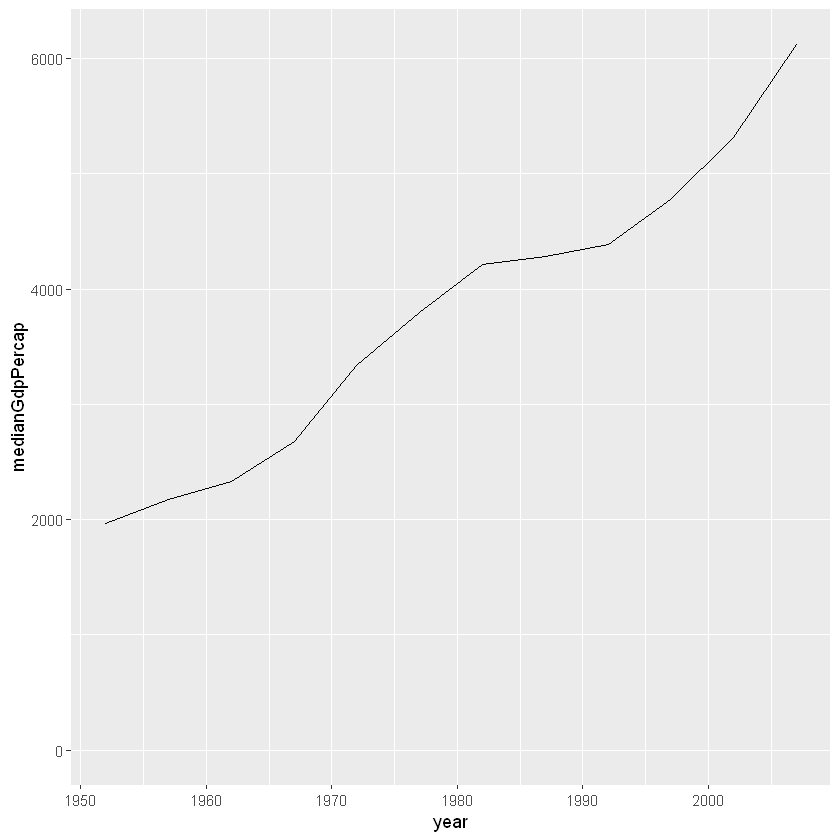

In [23]:
by_year <- gapminder %>%
group_by(year) %>%
summarise(medianGdpPercap = median(gdpPercap))

ggplot(by_year, aes(x = year, y = medianGdpPercap)) +
geom_line() +
expand_limits(y = 0)

`summarise()` has grouped output by 'year'. You can override using the `.groups` argument.



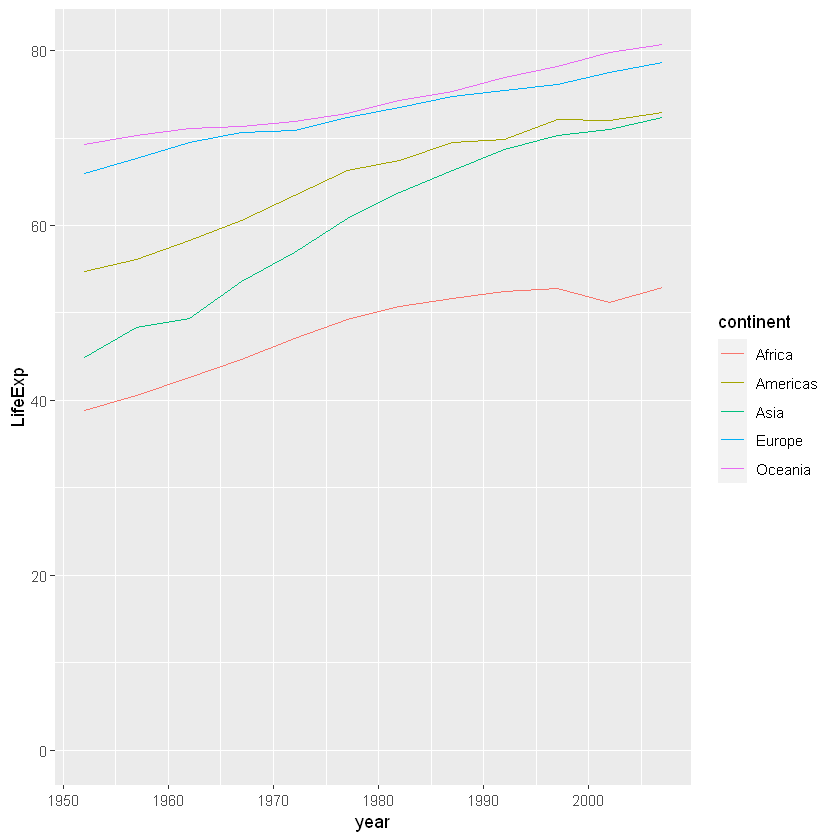

In [24]:
by_year_continent <- gapminder %>%
group_by(year, continent) %>%
summarise(LifeExp = median(lifeExp))



ggplot(by_year_continent, aes(x = year, y = LifeExp, color = continent)) +
geom_line() +
expand_limits(y = 0)

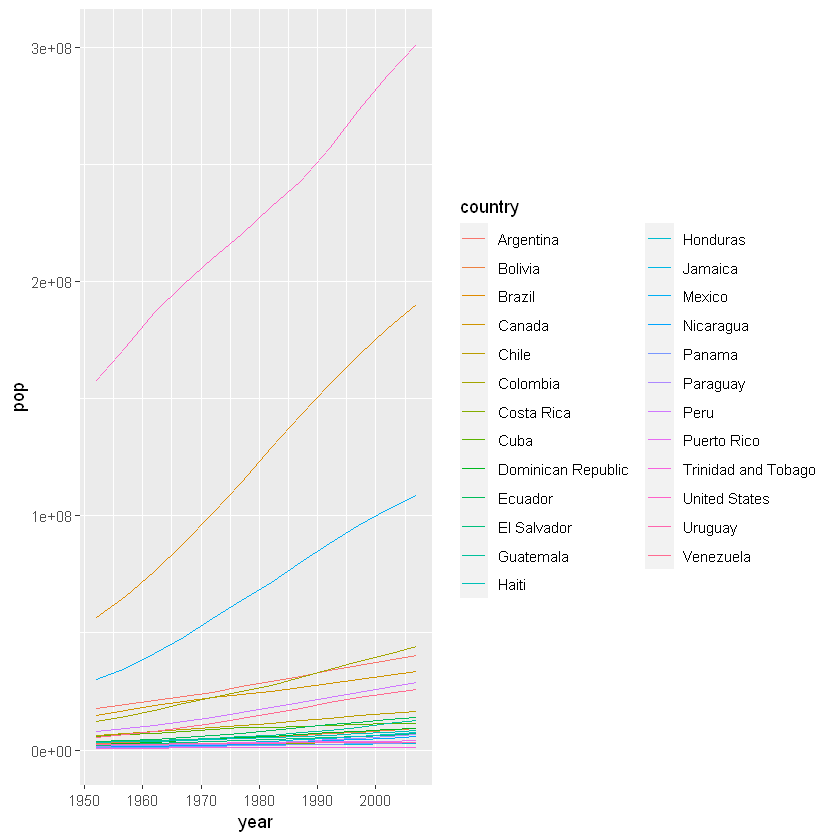

In [25]:
a1 <- gapminder %>%
filter(continent == "Americas") %>%
select(country, year, pop)


ggplot(a1, aes(x = year, y = pop, color = country)) +
geom_line() +
expand_limits(y = 0)



## Bar plots

Bar plots, which are good at comparing statistics for each of several categories. 

### What is a bar plot?

A bar chart (aka bar graph, column chart) plots numeric values for levels of a categorical feature as bars. Levels are plotted on one chart axis, and values are plotted on the other axis. <b>Each categorical value claims one bar, and the length of each bar corresponds to the bar’s value. Bars are plotted on a common baseline to allow for easy comparison of values.

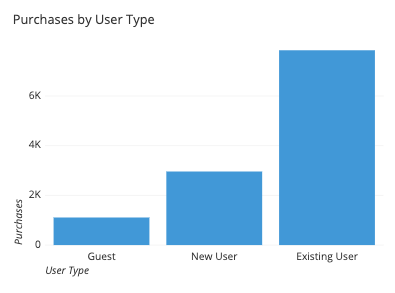

### When you should use a bar chart?

<b>A bar chart is used when you want to show a distribution of data points or perform a comparison of metric values across different subgroups of your data</b>. From a bar chart, we can see which groups are highest or most common, and how other groups compare against the others. Since this is a fairly common task, bar charts are a fairly ubiquitous chart type.

The primary variable of a bar chart is its categorical variable. A categorical variable takes discrete values, which can be thought of as labels. Examples include state or country, industry type, website access method (desktop, mobile), and visitor type (free, basic, premium). Some categorical variables have ordered values, like dividing objects by size (small, medium, large). In addition, some non-categorical variables can be converted into groups, like aggregating temporal data based on date (eg. dividing by quarter into 20XX-Q1, 20XX-Q2, 20XX-Q3, 20XX-Q4, etc.) The important point for this primary variable is that the groups are distinct.

In contrast, the secondary variable will be numeric in nature. The secondary variable’s values determine the length of each bar. These values can come from a great variety of sources. In its simplest form, the values may be a simple frequency count or proportion for how much of the data is divided into each category. Other times, the values may be an average, total, or some other summary measure computed separately for each group.

### Example of data structure

Data rendered as a bar chart might come in a compact form like the above table, with one column for the categories and the second column for their values. 

In [59]:
america <- gapminder %>%
filter(continent == "Americas") %>%
group_by(country) %>%
summarise(averagepop = mean(pop)) 

america

country,averagepop
<fct>,<dbl>
Argentina,28602240
Bolivia,5610395
Brazil,122312127
Canada,24462967
Chile,11205725
Colombia,27256100
Costa Rica,2400008
Cuba,9232576
Dominican Republic,5735697


Other times, data may come in its unaggregated form...

In [60]:
america <- gapminder %>%
filter(continent == "Americas") %>%
group_by(country) %>%
select(country, pop)

america

country,pop
<fct>,<int>
Argentina,17876956
Argentina,19610538
Argentina,21283783
Argentina,22934225
Argentina,24779799
Argentina,26983828
Argentina,29341374
Argentina,31620918
Argentina,33958947


### Use a common zero-valued baseline

First and foremost, make sure that all of your bars are being plotted against a zero-value baseline. Not only does that baseline make it easier for readers to compare bar lengths, it also maintains the truthfulness of your data visualization. A bar chart with a non-zero baseline or some other gap in the axis scale can easily misrepresent the comparison between groups since the ratio in bar lengths will not match the ratio in actual bar values.

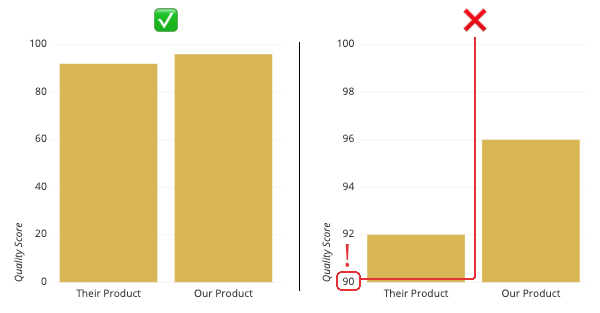

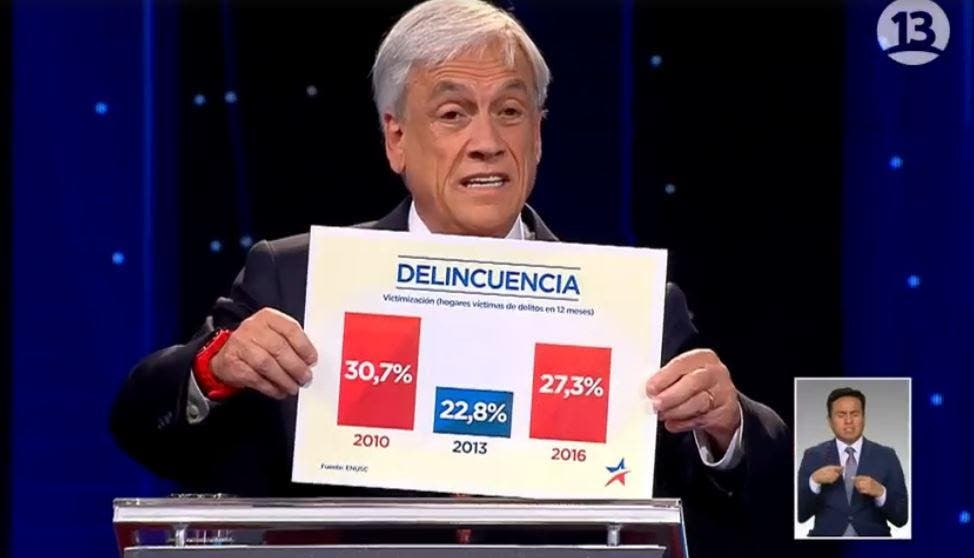




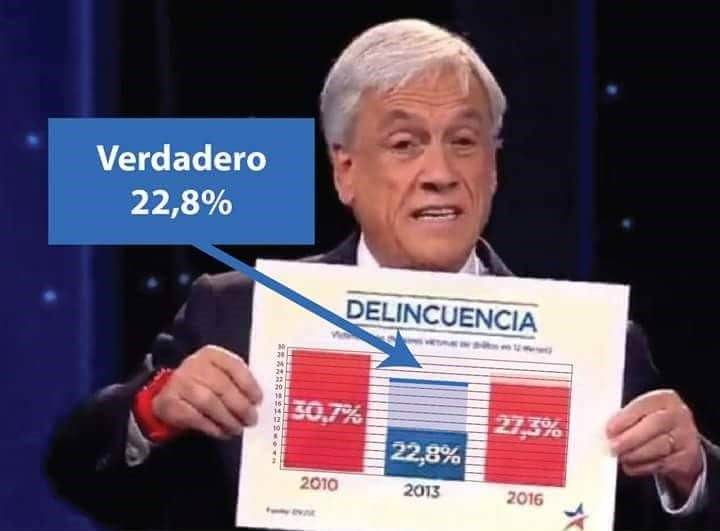

### Consider the ordering of category levels

One consideration you should have when putting together a bar chart is what order in which you will plot the bars. A standard convention to take is to sort the bars from longest to shortest: while it is always possible to compare the bar lengths no matter the order, this can reduce the burden on the reader to make those comparisons themselves. The major exception to this is if the category labels are inherently ordered in some way.

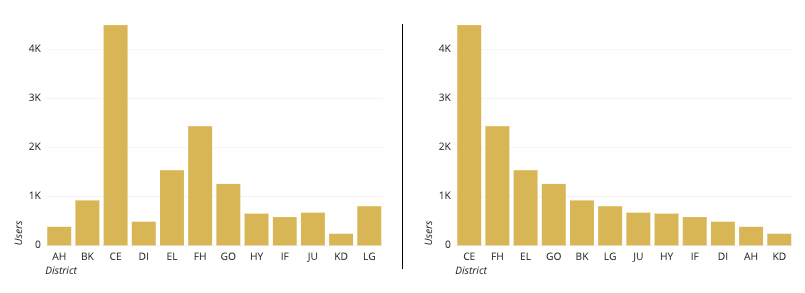

### Use color wisely

Another consideration is on how you should use color in your bar charts. Certain tools will color each bar differently by default, but this can distract the reader by implying additional meaning where none exists. Instead, color should be used with purpose. For example, you might use color to highlight specific columns for storytelling. Colors can also be used if they are meaningful for the categories posted (e.g. to match company or team colors).

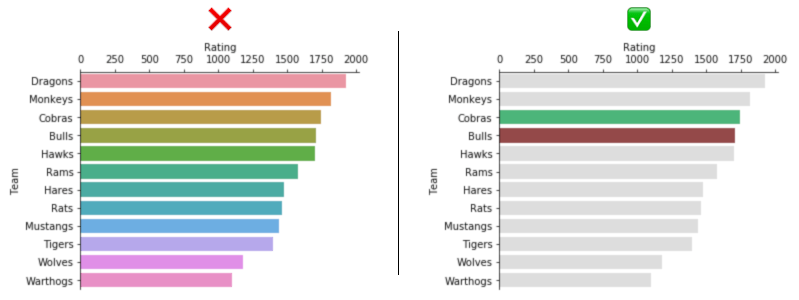

### Horizontal bars vs. vertical bars

A common bar chart variation is whether or not the bar chart should be oriented vertically (with categories on the horizontal axis) or horizontally (with categories on the vertical axis). While the vertical bar chart is usually the default, it’s a good idea to use a horizontal bar chart when you are faced with long category labels. In a vertical chart, these labels might overlap, and would need to be rotated or shifted to remain legible; the horizontal orientation avoids this issue.


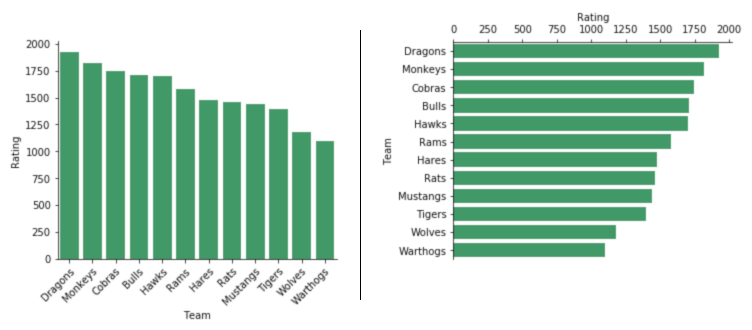

### Include value annotations

A common addition to bar charts are value annotations. While it is fairly easy for readers to compare bar lengths and gauge approximate values from a bar chart, exact values aren’t necessarily easy to state. Annotations can report these values where they are important, and are usually placed in the middle of the bar or at their ends.

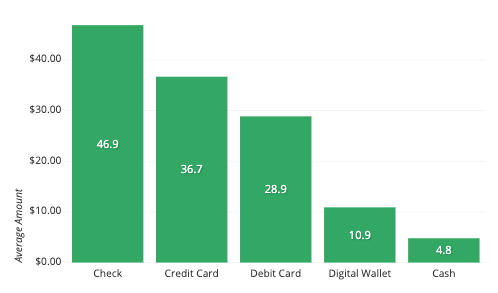

### Include variability whiskers

When the numeric values are a summary measure, a frequent consideration is whether or not to include error bars in the plot. Error bars are additional whiskers added to the end of each bar to indicate variability in the individual data points that contributed to the summary measure. Since there are many choices for uncertainty measure (e.g. standard deviation, confidence interval, interquartile range) it is important that when you display error bars, that you note in an annotation or comment what the error bars represent.

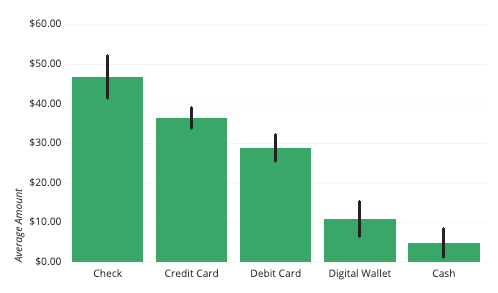

### let us go back to the code in R!

In [26]:
by_continent <- gapminder %>%
filter(year == 2007) %>%
group_by(continent) %>%
summarise(meanLifeExp = mean(lifeExp))

by_continent


continent,meanLifeExp
<fct>,<dbl>
Africa,54.80604
Americas,73.60812
Asia,70.72848
Europe,77.64860
Oceania,80.71950


This code finds the average life expectancy within each continent in the year 2007. That creates a table that looks like this, with one observation for each continent. Instead of just printing the table, you might want to represent the summary visually. For that, you would use a bar plot. 

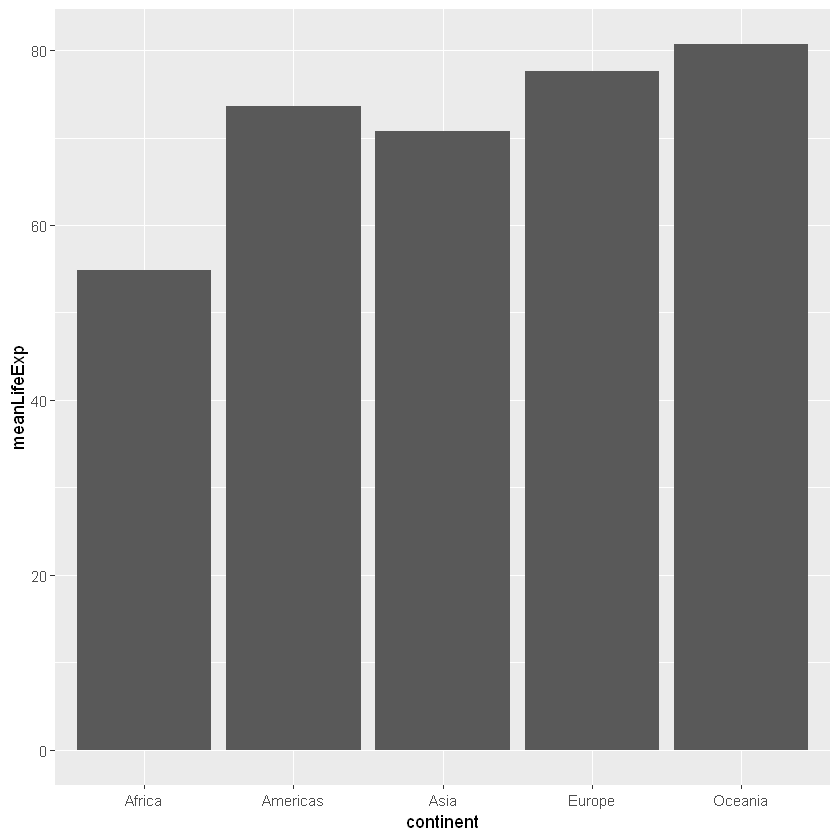

In [27]:
ggplot(by_continent, aes(x= continent, y = meanLifeExp)) +
geom_col()

continent,medianGdpPercap,meanGdpPercap
<fct>,<dbl>,<dbl>
Africa,1452.267,3089.033
Americas,8948.103,11003.032
Asia,4471.062,12473.027
Europe,28054.066,25054.482
Oceania,29810.188,29810.188


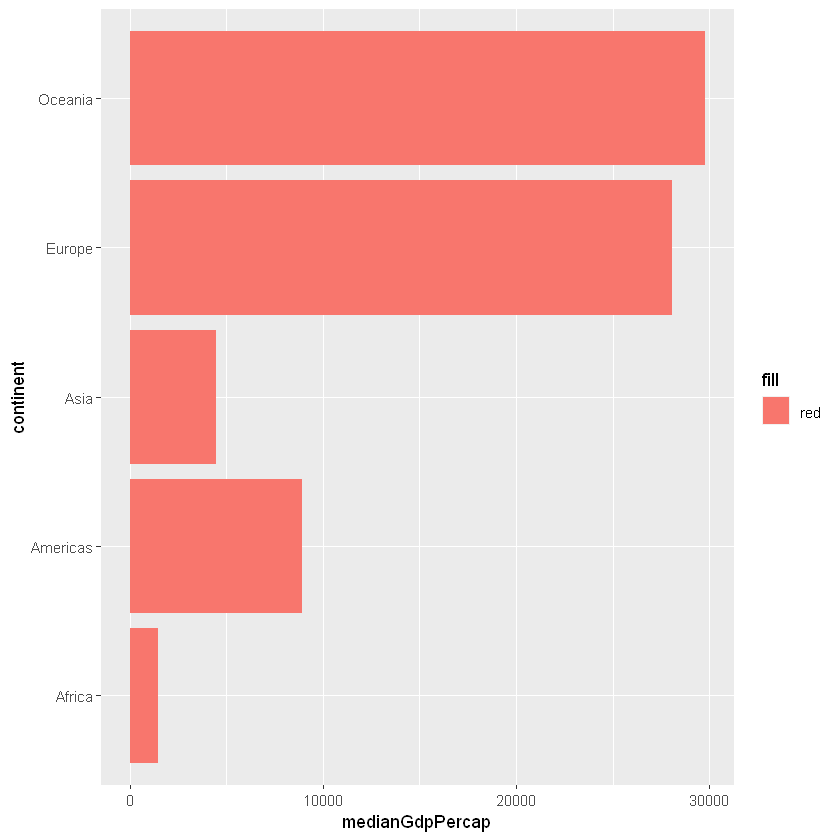

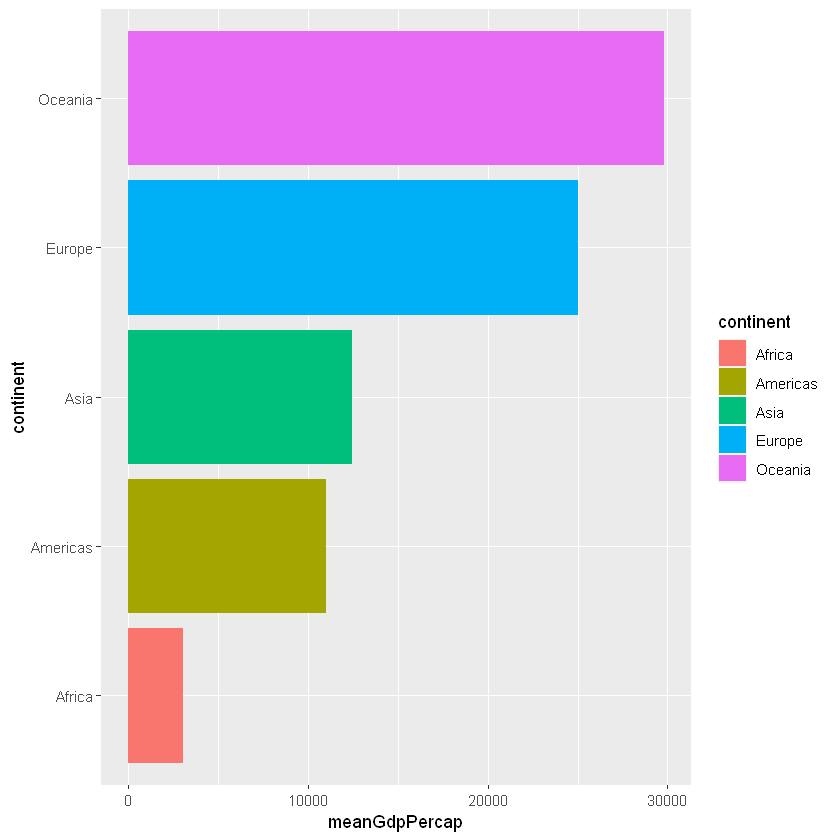

In [29]:
by_continent1 <- gapminder %>%
filter(year == 2007) %>%
group_by(continent) %>%
summarise(medianGdpPercap = median(gdpPercap), meanGdpPercap = mean(gdpPercap))

by_continent1

ggplot(by_continent1, aes(x= continent, y = medianGdpPercap, fill="red")) +
geom_col()+ coord_flip()

ggplot(by_continent1, aes(x= continent, y = meanGdpPercap, fill=continent)) +
geom_col()+ coord_flip()


country,meanGdpPercap,sdGdpPercap
<fct>,<dbl>,<dbl>
Australia,19980.60,7815.405
New Zealand,17262.62,4409.009


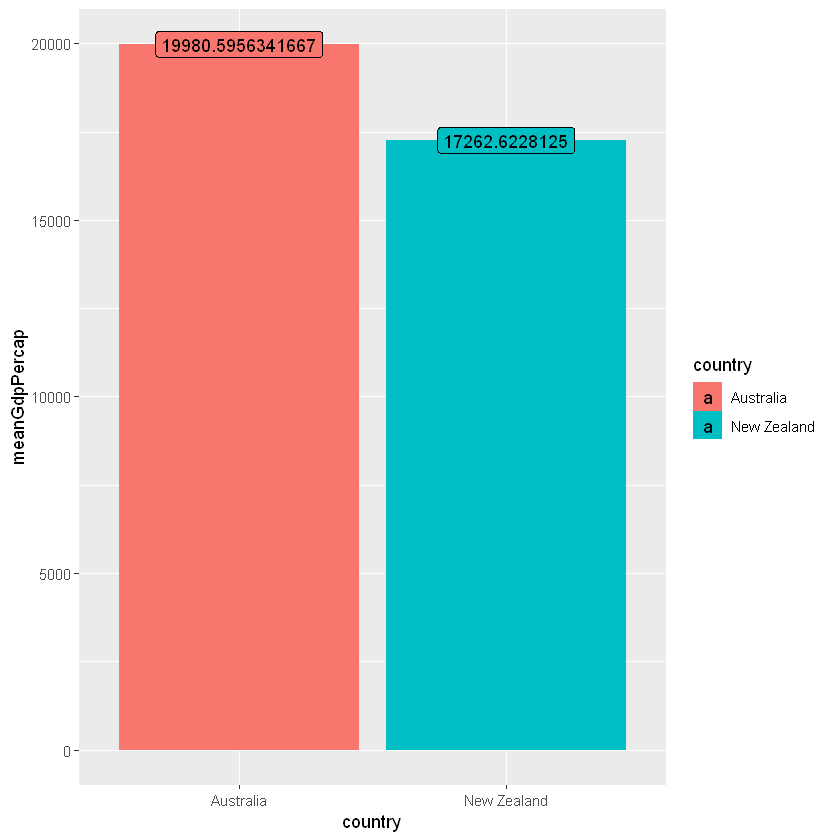

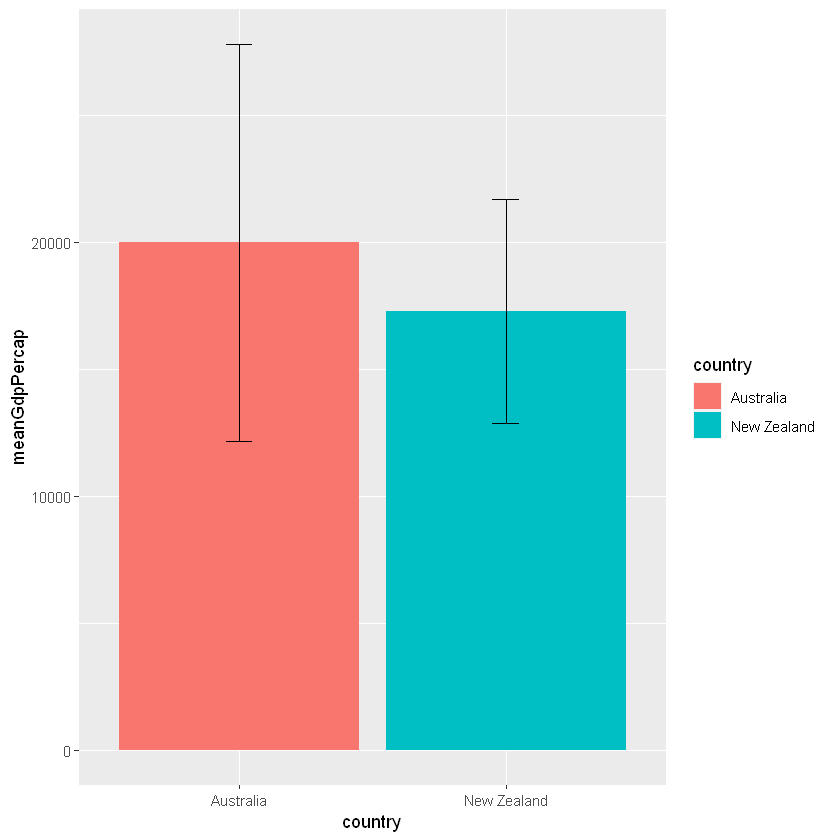

In [30]:
oceania <- gapminder %>%
filter(continent == "Oceania") %>%
group_by(country) %>%
summarise(meanGdpPercap = mean(gdpPercap), sdGdpPercap = sd(gdpPercap))

oceania

# Create a bar plot with labels
ggplot(oceania, aes(x= country, y = meanGdpPercap, fill = country)) +
geom_col() +
geom_label(aes(x=country, label=meanGdpPercap))
#geom_text(aes(label = meanGdpPercap), vjust = -1) 


# Create a bar plot with errors
ggplot(oceania, aes(x= country, y = meanGdpPercap, fill = country)) +
geom_col() +
geom_errorbar(aes(ymin=meanGdpPercap-sdGdpPercap, ymax=meanGdpPercap+sdGdpPercap), width=.1,
                 position=position_dodge(.9)) 

In [ ]:
?geom_label

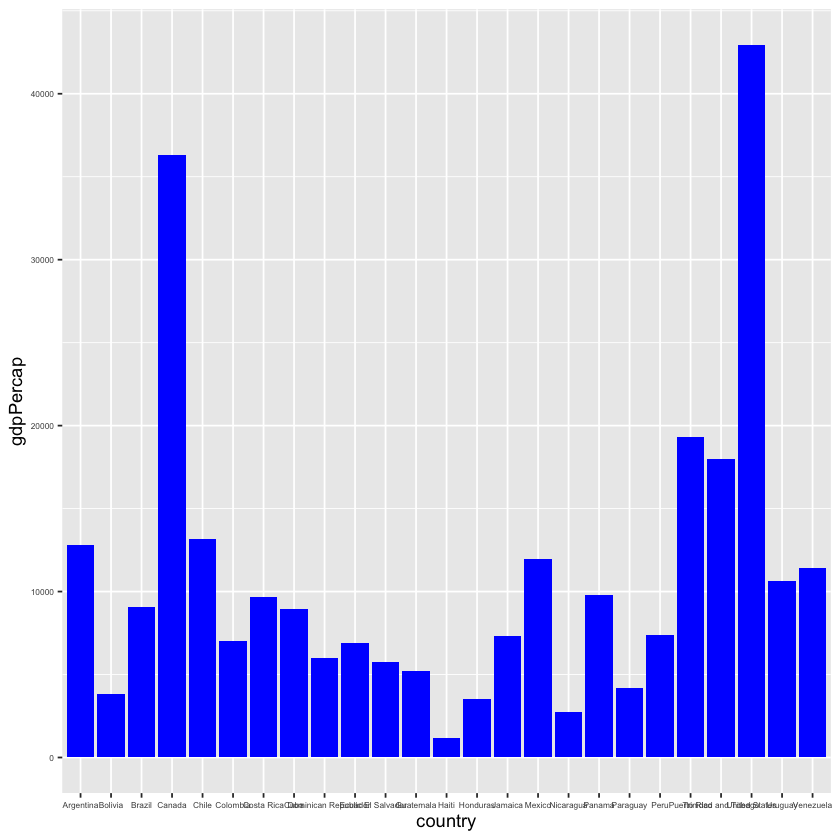

In [37]:
america <- gapminder %>%
filter(year == 2007, continent == "Americas") 


# Create a bar plot of gdpPercap by country
ggplot(america, aes(x= country, y = gdpPercap)) +
geom_col(fill = "blue") + 
# coord_flip() +
theme(axis.text = element_text(size = 5))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Haiti,Americas,2007,60.916,8502814,1201.637
Nicaragua,Americas,2007,72.899,5675356,2749.321
Honduras,Americas,2007,70.198,7483763,3548.331
Bolivia,Americas,2007,65.554,9119152,3822.137
Paraguay,Americas,2007,71.752,6667147,4172.838
Guatemala,Americas,2007,70.259,12572928,5186.050
El Salvador,Americas,2007,71.878,6939688,5728.354
Dominican Republic,Americas,2007,72.235,9319622,6025.375
Ecuador,Americas,2007,74.994,13755680,6873.262


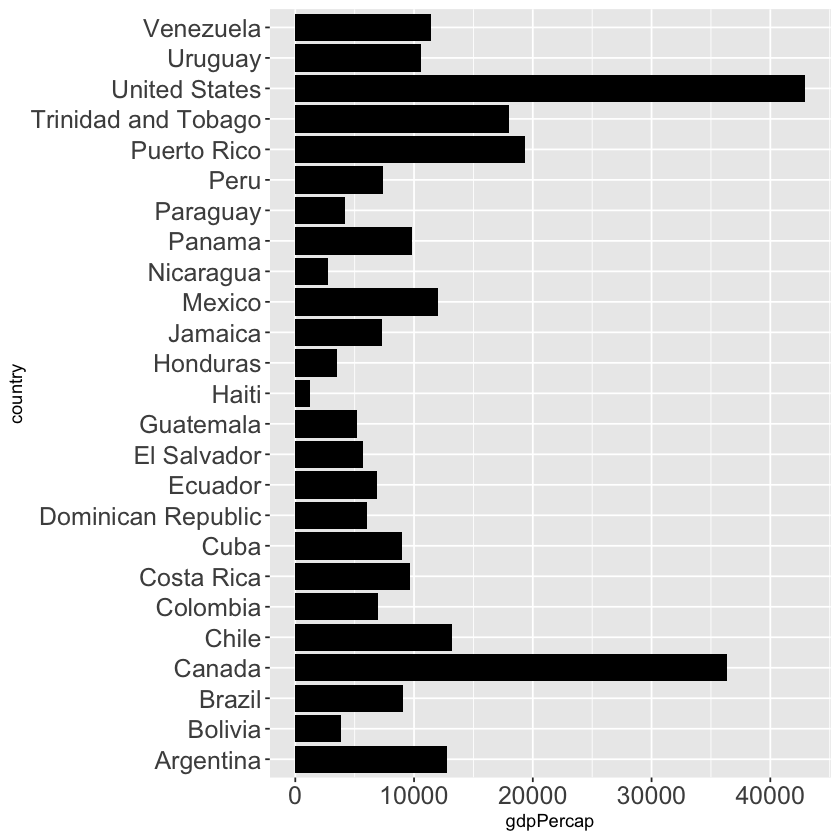

In [38]:
#Sorting????

america2 <- gapminder %>%
filter(year == 2007, continent == "Americas") %>%
arrange(gdpPercap)

america2

# Create a bar plot of gdpPercap by country
ggplot(america2, aes(x= country, y = gdpPercap)) +
geom_col(fill = "black") + 
coord_flip()  +
theme(axis.text = element_text(size = 15))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Argentina,Americas,2007,75.320,40301927,12779.380
Bolivia,Americas,2007,65.554,9119152,3822.137
Brazil,Americas,2007,72.390,190010647,9065.801
Canada,Americas,2007,80.653,33390141,36319.235
Chile,Americas,2007,78.553,16284741,13171.639
Colombia,Americas,2007,72.889,44227550,7006.580
Costa Rica,Americas,2007,78.782,4133884,9645.061
Cuba,Americas,2007,78.273,11416987,8948.103
Dominican Republic,Americas,2007,72.235,9319622,6025.375


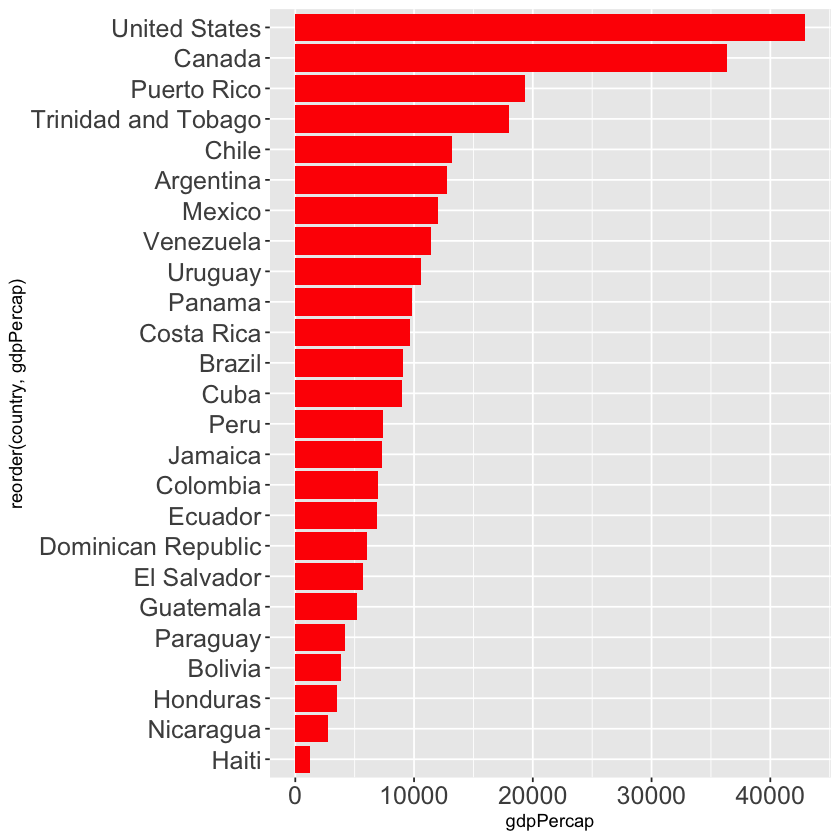

In [39]:
#Now is sorted

america3 <- gapminder %>%
filter(year == 2007, continent == "Americas")

america3

# Create a bar plot of gdpPercap by country
ggplot(america3, aes(x= reorder(country, gdpPercap), y = gdpPercap)) +
geom_col(fill = "red") + 
coord_flip()  +
theme(axis.text = element_text(size = 15))

In [ ]:
?reorder

## Stacked Bar plots

### What is a stacked bar chart?

The stacked bar chart (aka stacked bar graph) extends the standard bar chart from looking at numeric values across two or more categorical variables. Each bar in a standard bar chart is divided into a number of sub-bars stacked end to end, each one corresponding to a level of the second categorical variable.

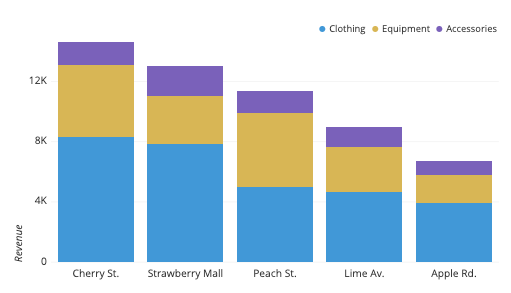

The stacked bar chart above depicts revenue from a fictional fitness retailer for a particular period of time, across two categorical variables: store location and department. The primary categorical variable is store location: we can see from the sorted overall bar heights that the Cherry St. location has the highest revenue and Apple Rd. lowest. Each bar is subdivided based on levels of the second categorical variable, department. We can see that for most locations, clothing is quite a bit larger in sales than equipment, which in turn is larger than accessories. The Strawberry Mall location appears to have a lower proportion of revenue attributed to equipment, while equipment has a larger share for Peach St.

### When you should use a stacked bar chart

The main objective of a standard bar chart is to compare numeric values between levels of a categorical variable. One bar is plotted for each level of the categorical variable, each bar’s length indicating numeric value. A stacked bar chart also achieves this objective, but also targets a second goal.

We want to move to a stacked bar chart when we care about the relative decomposition of each primary bar based on the levels of a second categorical variable. Each bar is now comprised of a number of sub-bars, each one corresponding with a level of a secondary categorical variable. The total length of each stacked bar is the same as before, but now we can see how the secondary groups contributed to that total.

### Order of categorical variables

One important consideration in building a stacked bar chart is to decide which of the two categorical variables will be the primary variable (dictating major axis positions and overall bar lengths) and which will be the secondary (dictating how each primary bar will be subdivided). The most ‘important’ variable should be the primary; use domain knowledge and the specific type of categorical variables to make a decision on how to assign your categorical variables. As another consideration, variables with more levels are generally better as primary variables; we want to limit the number of secondary levels to a fairly small amount to make the stack breakdowns easier to read.

### Maintain a zero-baseline

When a standard bar chart encounters a negative value, the corresponding bar just gets plotted below or to the left of the baseline (depending on if the bars are vertically or horizontally oriented, respectively). In a stacked bar chart, a similar representation can be performed, just stacking bars in the negative direction.

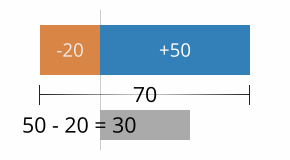

However, when positive bars and negative bars are combined, it is no longer the case that the overall length of the bar corresponds to the bar’s total value. When this occurs, it is a good idea to plot an additional line or series of points on top of the bars to show the true total: the difference between the lengths of the positive bars and negative bars.

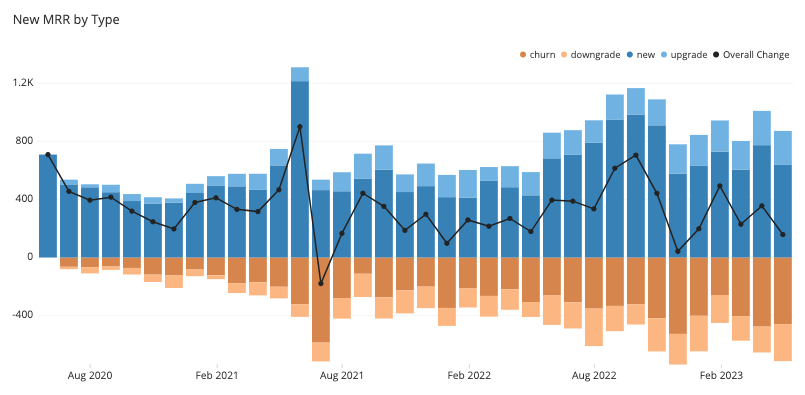

### Ordering of category levels


With a stacked bar chart, you will need to consider the order of category levels for both categorical variables to be plotted. The rule of thumb for standard bar charts can be applied in both variables: order the bars from largest to smallest unless there is an intrinsic order of levels.

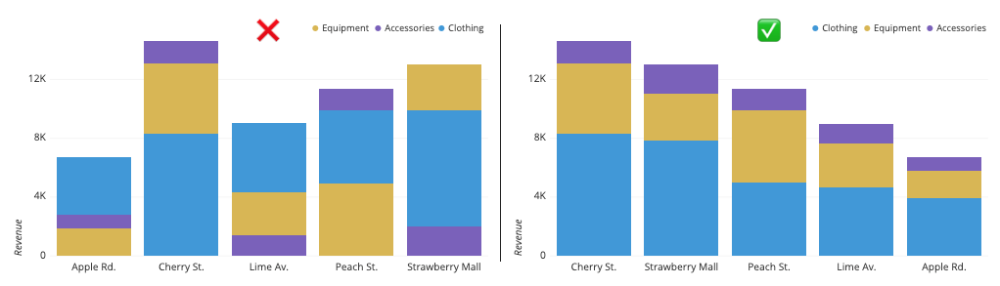

### Choosing effective colors

While the general recommendation is to stick with a single color in a standard bar chart, use of color to distinguish secondary variable levels is an inevitability for a stacked bar chart. The important point is to make sure that the choice of color palette to assign to each categorical level matches the variable type: a qualitative palette for purely categorical variables, and sequential, or diverging for variables with a meaningful order.


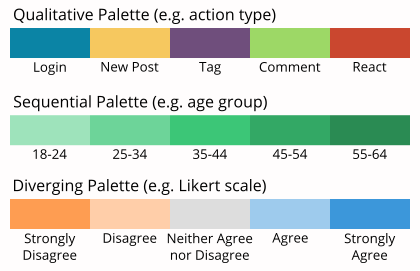

### Interpreting values on individual groups in a stacked area chart

While it is straightforward to compare the total numeric values across the levels of the primary categorical variable, it is less straightforward to gauge other divisions or comparisons using the secondary categorical variable. If we want to see the change in a secondary level across the primary categorical variable, this can only be easily done for the level plotted against the baseline. For all other secondary levels, their baseline will experience shifts, making it more difficult to judge how the sub-bar lengths change across primary bars. In the below example, it can be difficult to tell that the central yellow group is actually decreasing slightly over time.

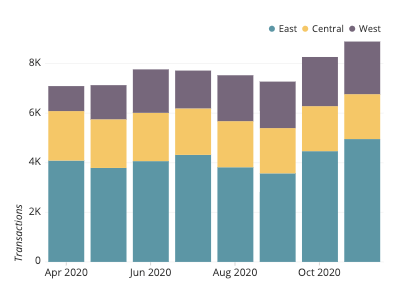

Even trying to compare sub-bars within each primary bar can be difficult. Even when following a guideline to sort secondary category levels by overall size, this presents no guarantee that they will be sorted by size within a particular primary bar. In the same image above, it can be hard to tell where the purple “West” group overtakes the yellow “Central” group in size.

Keep in mind that one of the standard goals of a stacked bar chart is to make relative judgements about the secondary categorical variable, and that making precise judgments are not as important. If comparing the sub-groups is important, then a different chart type like the <b>line chart</b> or <b>grouped bar chart</b> is warranted.

### Common stacked bar chart options

#### Horizontal stacked bar chart

Just like the standard bar chart, the bars in a stacked bar chart can be oriented horizontally (with primary categories on the vertical axis) as well as vertically (with primary categories on the horizontal axis). The horizontal orientation serves the same benefits as before, allowing for the easy display of long category levels without rotation or truncation.

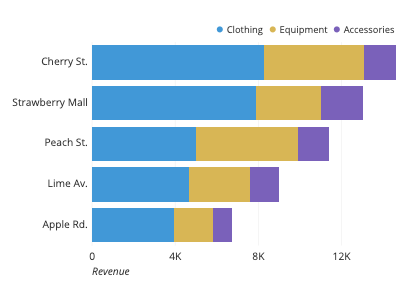

#### Percentage stacked bar chart

Another common option for stacked bar charts is the percentage, or relative frequency, stacked bar chart. Here, each primary bar is scaled to have the same height, so that each sub-bar becomes a percentage contribution to the whole at each primary category level. This removes our ability to compare the primary category levels’ totals, but allows us to perform a better analysis of the secondary groups’ relative distributions. The fixing of the heights of each primary bar to be the same also creates another baseline at the top of the chart where a second subgroup can be tracked across primary bars.

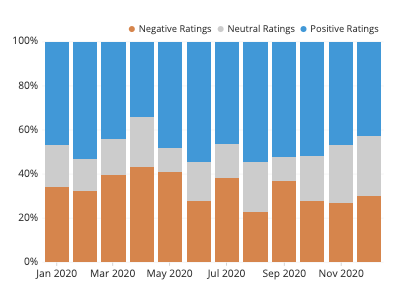

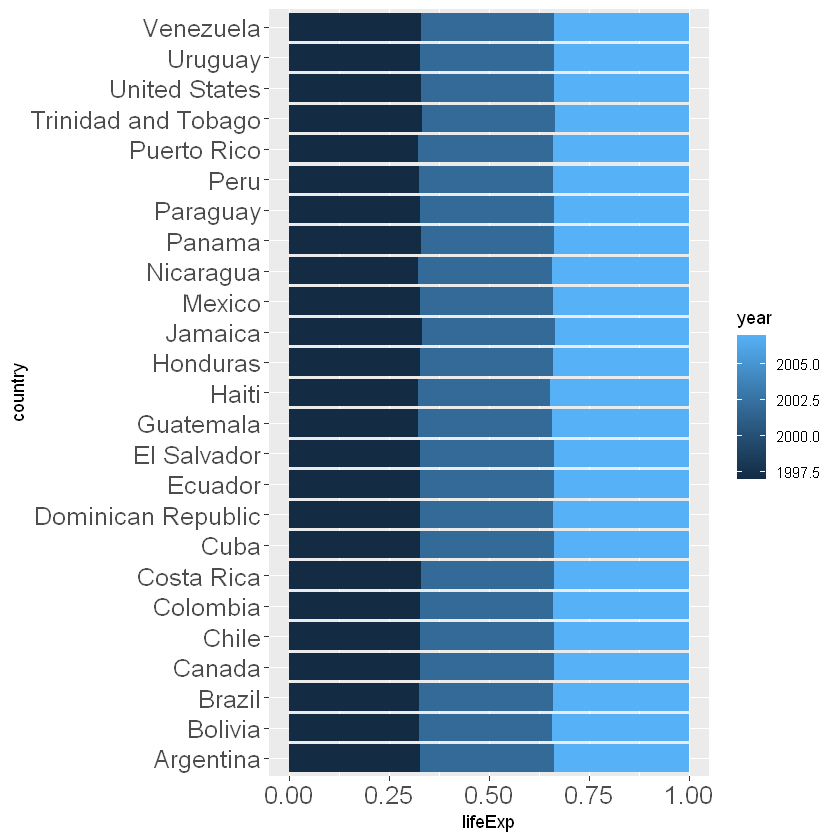

In [72]:
Americas <- gapminder %>%
filter(continent == "Americas", year >= 1997, year <= 2007) 

#Americas

# Create a bar plot with labels
ggplot(Americas, aes(x= country, y = lifeExp, fill = year)) +
geom_bar(position = "fill", stat = "identity") +
coord_flip()  +
theme(axis.text = element_text(size = 15))



#### Stacked bar

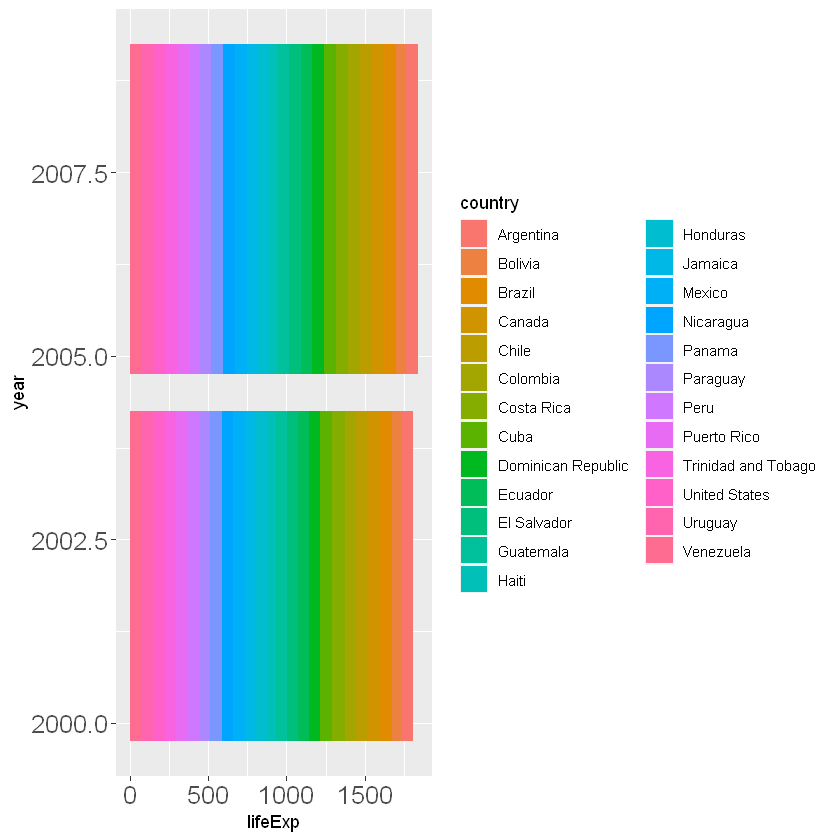

In [75]:
Americas <- gapminder %>%
filter(continent == "Americas", year >= 2002, year <= 2007) 

#Americas

# Create a bar plot with labels
ggplot(Americas, aes(x= year, y = lifeExp, fill = country)) +
geom_bar(position = "stack", stat = "identity") +
coord_flip()  +
theme(axis.text = element_text(size = 15))


This plot sucks cause there are too many levels in the secondary category!. A better way is:

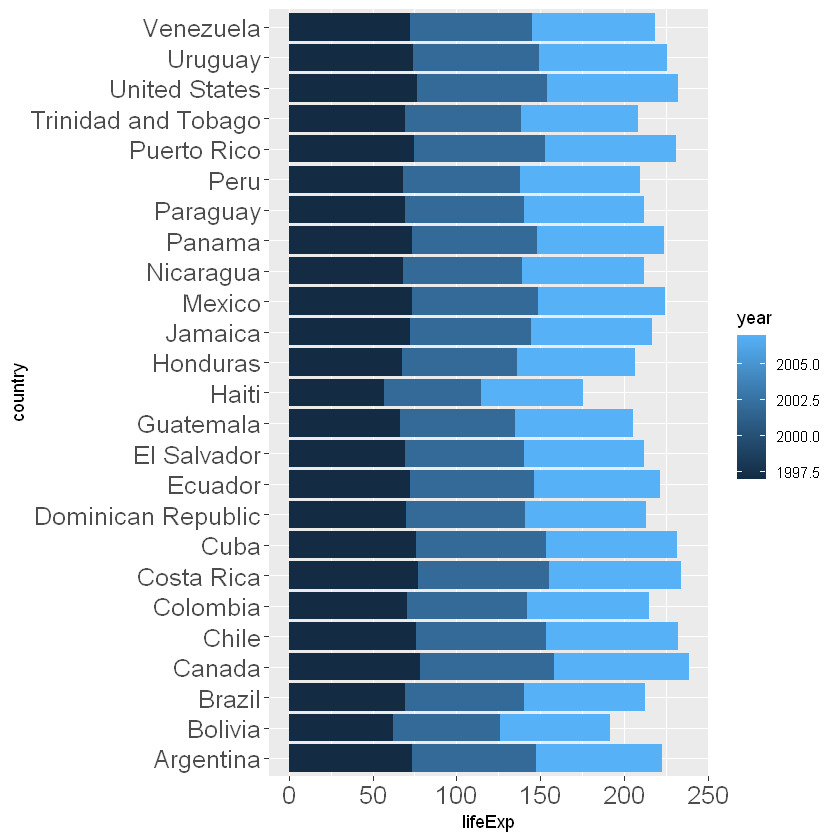

In [76]:
Americas <- gapminder %>%
filter(continent == "Americas", year >= 1997, year <= 2007) 

#Americas

# Create a bar plot with labels
ggplot(Americas, aes(x= country, y = lifeExp, fill = year)) +
geom_bar(position = "stack", stat = "identity") +
coord_flip()  +
theme(axis.text = element_text(size = 15))


#### Grouped stack bar

A grouped bar chart (aka clustered bar chart, multi-series bar chart) extends the bar chart, plotting numeric values for levels of two categorical variables instead of one. Bars are grouped by position for levels of one categorical variable, with color indicating the secondary category level within each group.

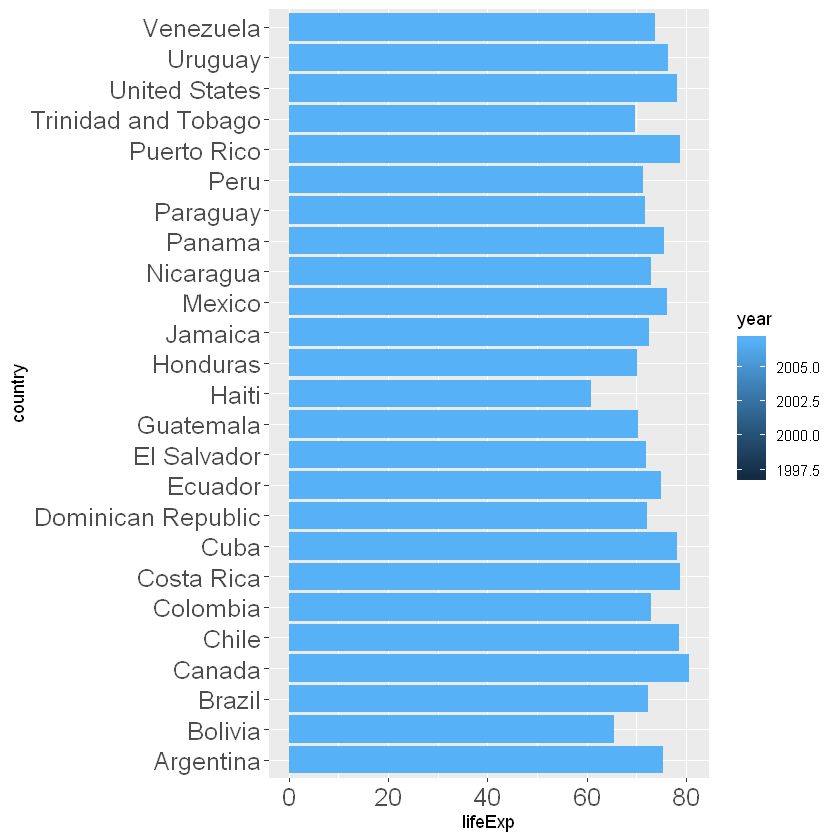

In [61]:

Americas <- gapminder %>%
filter(continent == "Americas", year >= 1997, year <= 2007) 

#Americas

# Create a bar plot with labels
ggplot(Americas, aes(x= country, y = lifeExp, fill = year)) +
geom_bar(position = position_dodge(), stat = "identity") +
coord_flip()  +
theme(axis.text = element_text(size = 15))

The plot dont work cause the year variable must be categorical (factor), for this: 

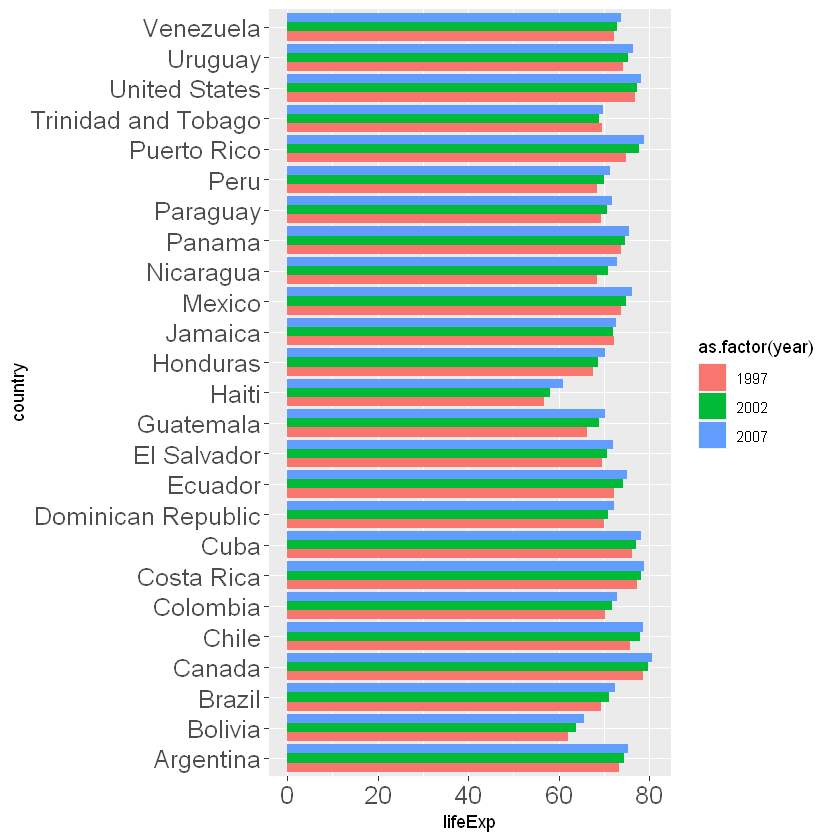

In [78]:
library(gapminder)
library(ggplot2)
library(dplyr)

Americas <- gapminder %>%
filter(continent == "Americas", year >= 1997, year <= 2007) 

#Americas

# Create a bar plot with labels
ggplot(Americas, aes(x= country, y = lifeExp, fill = as.factor(year))) +
geom_bar(position = position_dodge(), stat = "identity") +
coord_flip()  +
theme(axis.text = element_text(size = 15))

## Histograms

Histograms, which describe the distribution of a one-dimensional numeric variable. 

### What is a histogram?

A histogram is a chart that plots the distribution of a numeric variable’s values as a series of bars. Each bar typically covers a range of numeric values called a bin or class; a bar’s height indicates the frequency of data points with a value within the corresponding bin.

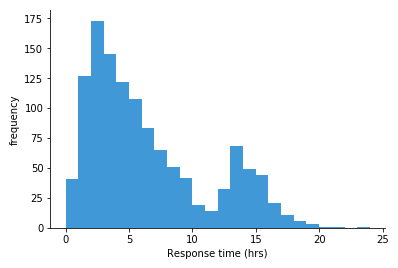



### When you should use a histogram?

Histograms are good for showing general distributional features of dataset variables. You can see roughly where the peaks of the distribution are, whether the distribution is skewed or symmetric, and if there are any outliers.

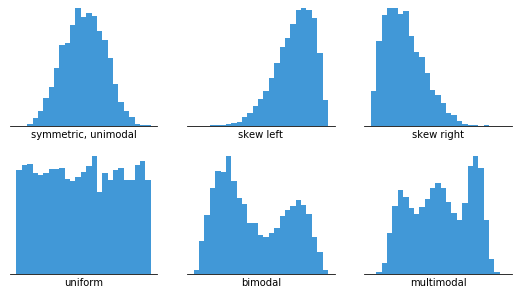

In order to use a histogram, we simply require a variable that takes continuous numeric values. This means that the differences between values are consistent regardless of their absolute values. For example, even if the score on a test might take only integer values between 0 and 100, a same-sized gap has the same meaning regardless of where we are on the scale: the difference between 60 and 65 is the same 5-point size as the difference between 90 to 95.

Information about the number of bins and their boundaries for tallying up the data points is not inherent to the data itself. Instead, setting up the bins is a separate decision that we have to make when constructing a histogram. The way that we specify the bins will have a major effect on how the histogram can be interpreted

### Example of data structure

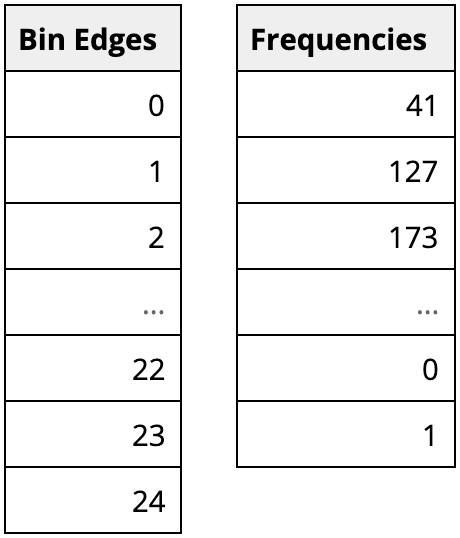

One way that visualization tools can work with data to be visualized as a histogram is from a summarized form like above. Here, the first column indicates the bin boundaries, and the second the number of observations in each bin. Alternatively, certain tools can just work with the original, unaggregated data column, then apply specified binning parameters to the data when the histogram is created.

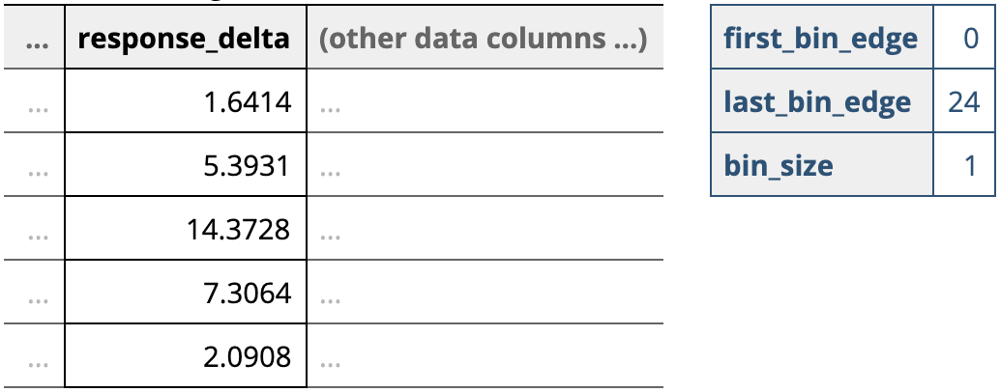

### Use a zero-valued baseline

An important aspect of histograms is that they must be plotted with a zero-valued baseline. Since the frequency of data in each bin is implied by the height of each bar, changing the baseline or introducing a gap in the scale will skew the perception of the distribution of data.

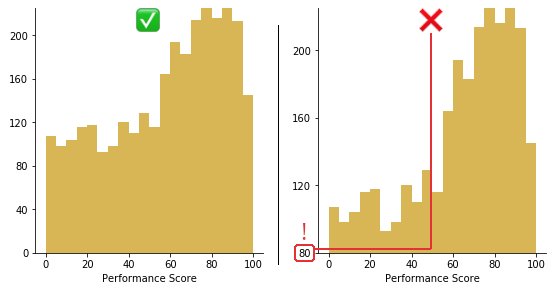

### Choose an appropriate number of bins

While tools that can generate histograms usually have some default algorithms for selecting bin boundaries, you will likely want to play around with the binning parameters to choose something that is representative of your data.

Choice of bin size has an inverse relationship with the number of bins. The larger the bin sizes, the fewer bins there will be to cover the whole range of data. With a smaller bin size, the more bins there will need to be. It is worth taking some time to test out different bin sizes to see how the distribution looks in each one, then choose the plot that represents the data best. If you have too many bins, then the data distribution will look rough, and it will be difficult to discern the signal from the noise. On the other hand, with too few bins, the histogram will lack the details needed to discern any useful pattern from the data.

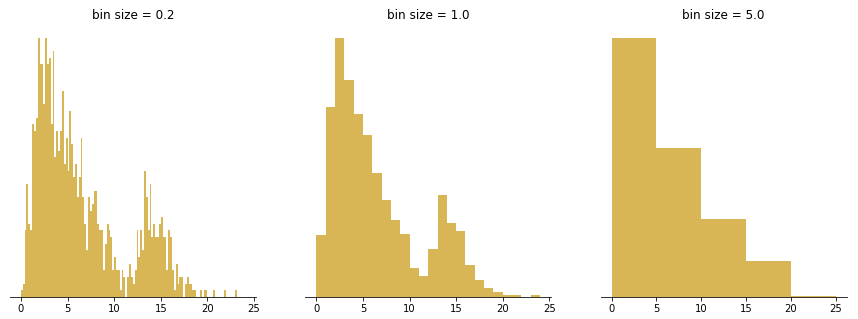

### Measured variable is not continuous numeric

As noted in the opening sections, a histogram is meant to depict the frequency distribution of a continuous numeric variable. When our variable of interest does not fit this property, we need to use a different chart type instead: a bar chart. A variable that takes categorical values, like user type (e.g. guest, user) or location are clearly non-numeric, and so should use a bar chart. However, there are certain variable types that can be trickier to classify: those that take on discrete numeric values and those that take on time-based values.

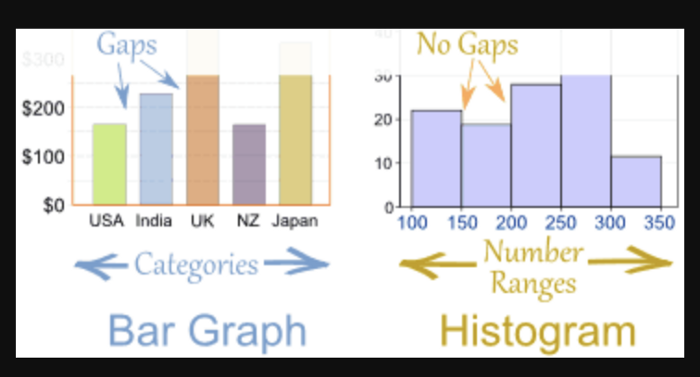

### Using unequal bin sizes

When data is sparse, such as when there’s a long data tail, the idea might come to mind to use larger bin widths to cover that space. However, creating a histogram with bins of unequal size is not strictly a mistake, but doing so requires some major changes in how the histogram is created and can cause a lot of difficulties in interpretation.

The technical point about histograms is that the total area of the bars represents the whole, and the area occupied by each bar represents the proportion of the whole contained in each bin. When bin sizes are consistent, this makes measuring bar area and height equivalent. In a histogram with variable bin sizes, however, the height can no longer correspond with the total frequency of occurrences. Doing so would distort the perception of how many points are in each bin, since increasing a bin’s size will only make it look bigger. 

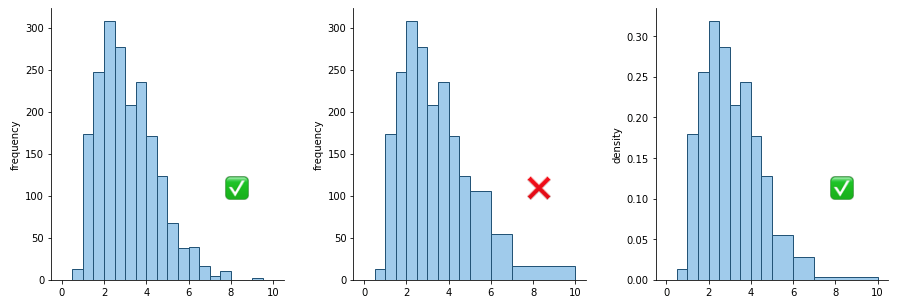

### let us go back to the code in R!


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


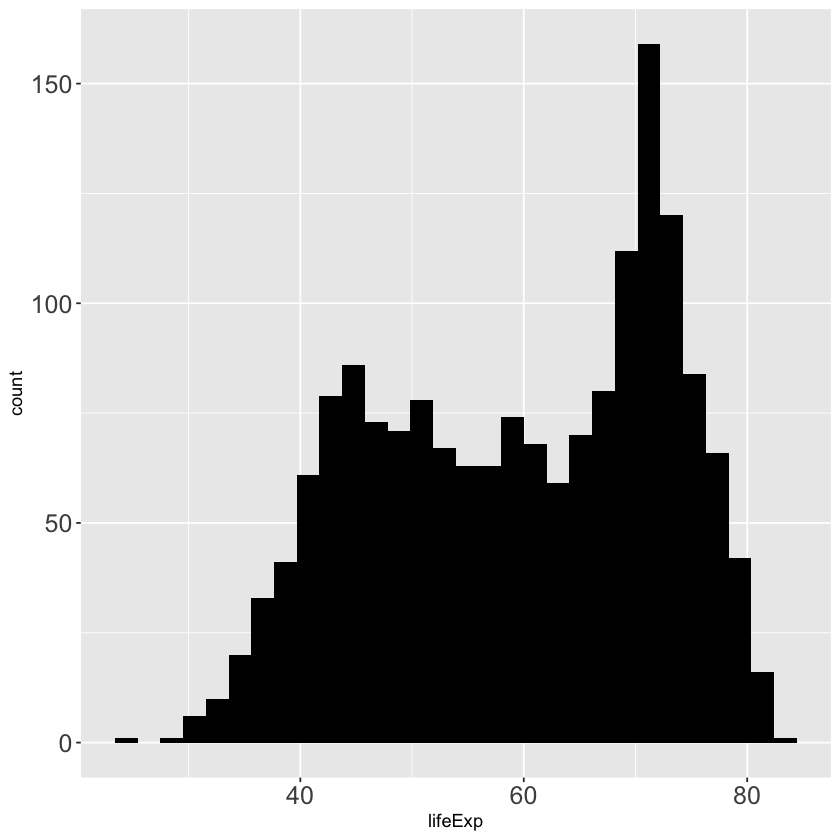

In [1]:
library(ggplot2)
library(gapminder)
library(dplyr)


ggplot(gapminder, aes(x = lifeExp)) +
geom_histogram(fill = "black")+
theme(axis.text = element_text(size = 15))

In [1]:
library(gapminder)
gapminder

Warning message:
"package 'gapminder' was built under R version 3.6.3"


country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134
Afghanistan,Asia,1982,39.854,12881816,978.0114
Afghanistan,Asia,1987,40.822,13867957,852.3959
Afghanistan,Asia,1992,41.674,16317921,649.3414


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


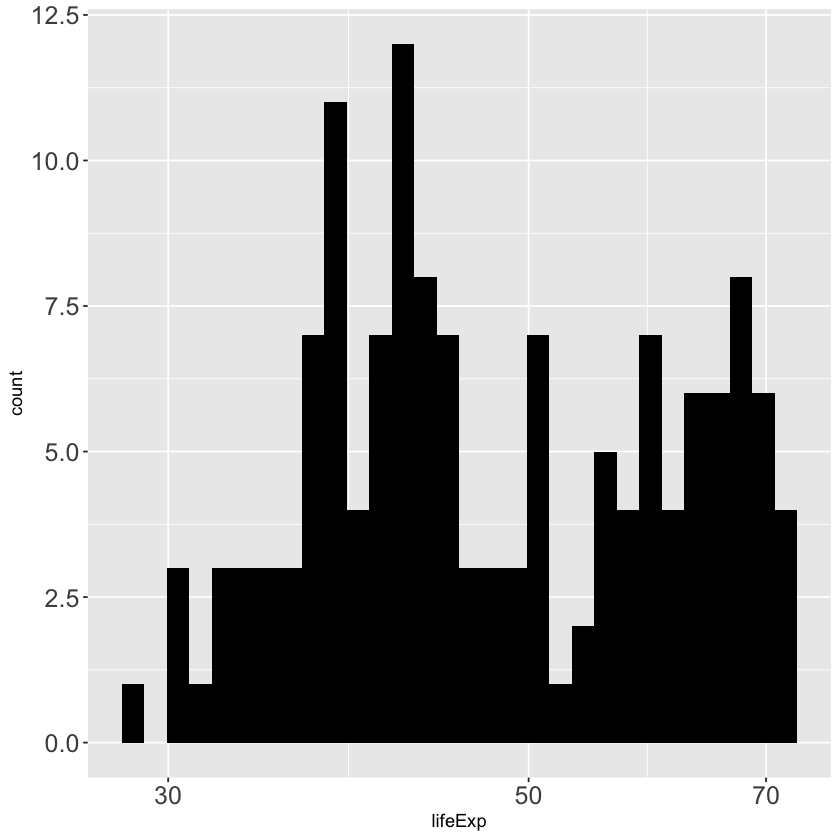

In [9]:
library(dplyr)
library(gapminder)
library(ggplot2)

gapminder_1952 <- gapminder %>%
  filter(year == 1952)

# Create a histogram of population (pop_by_mil)
ggplot(gapminder_1952, aes(x = lifeExp)) +
geom_histogram(fill = "black") +
theme(axis.text = element_text(size = 15)) +
scale_x_log10() 


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


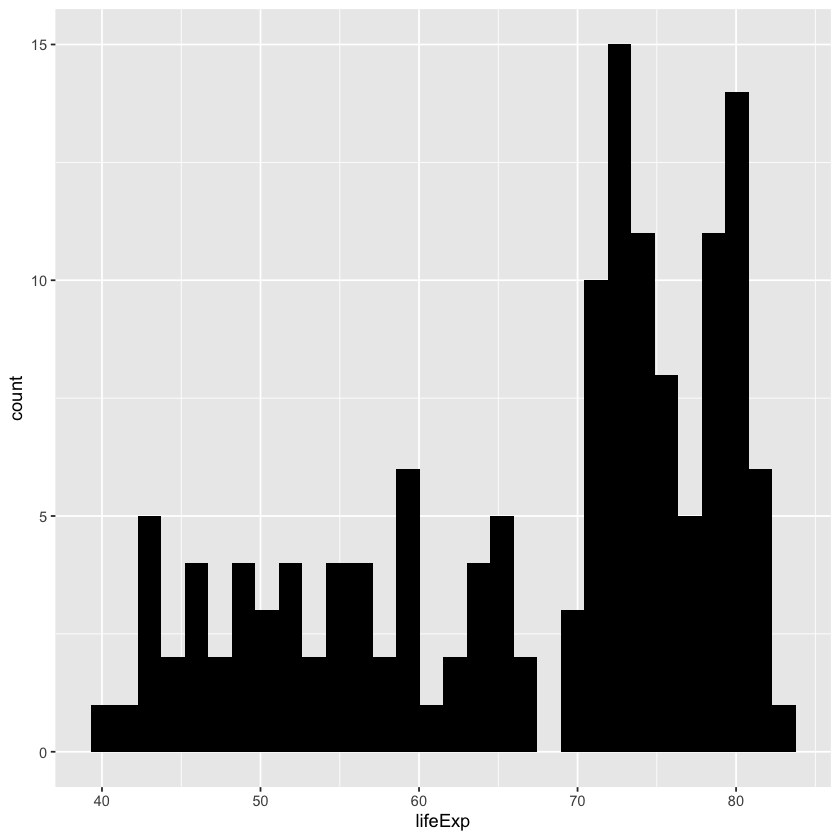

In [3]:
gapminder_2007 <- gapminder %>%
  filter(year == 2007)

# Create a histogram of population (pop_by_mil)
ggplot(gapminder_2007, aes(x = lifeExp)) +
geom_histogram(fill = "black")

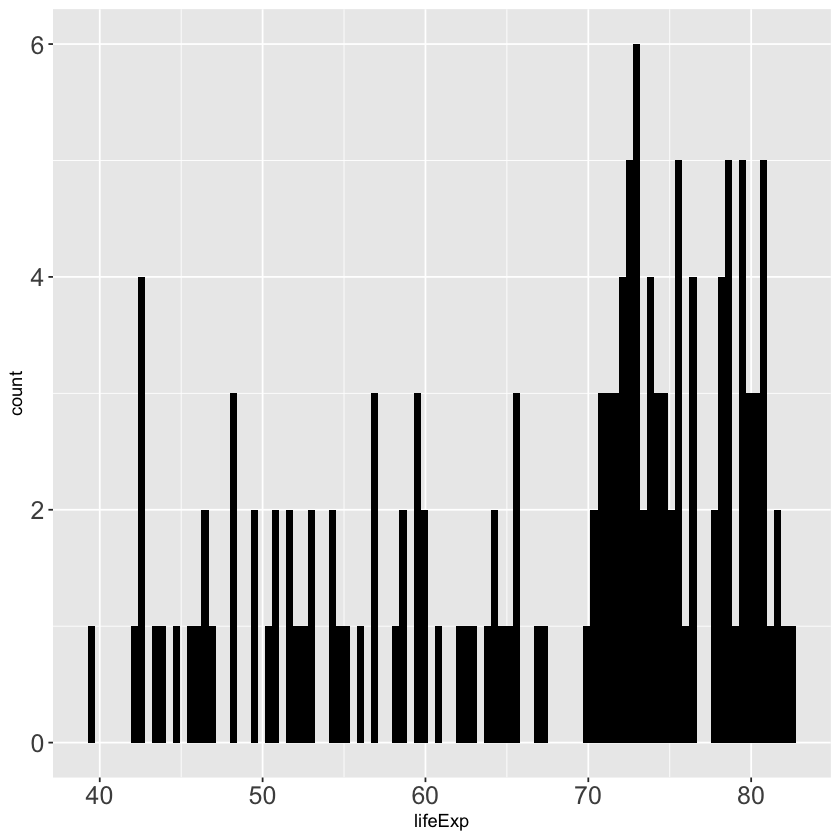

In [4]:
gapminder_2007 <- gapminder %>%
  filter(year == 2007)

# Create a histogram of population (pop_by_mil)
ggplot(gapminder_2007, aes(x = lifeExp)) +
geom_histogram(bins = 100, fill = "black") +
theme(axis.text = element_text(size = 15))

`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


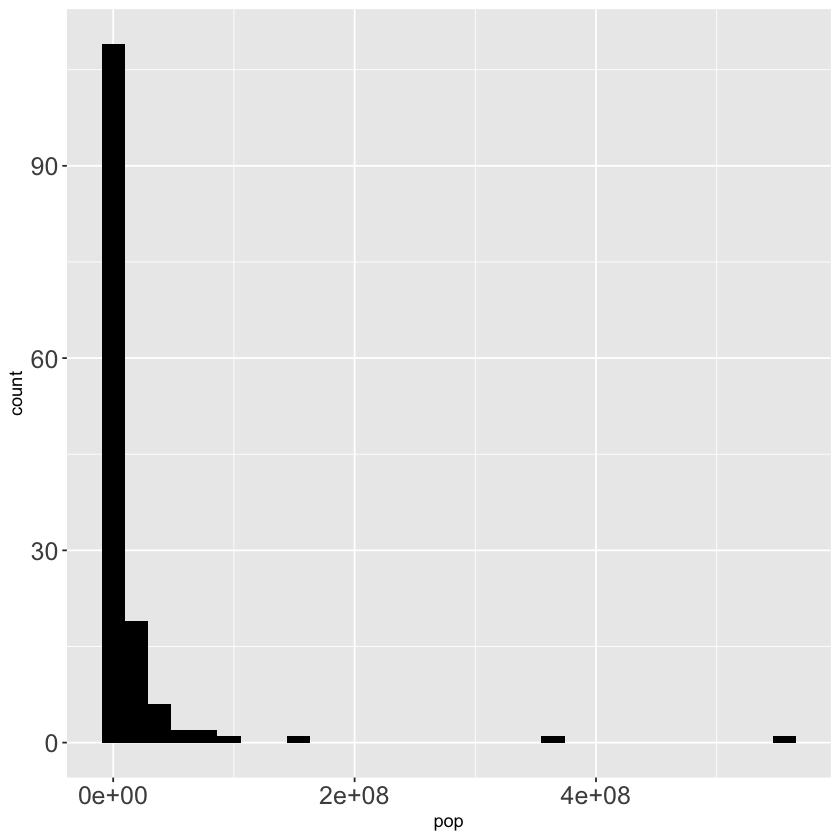

In [5]:
gapminder_1952 <- gapminder %>%
  filter(year == 1952)

# Create a histogram of population (pop), with x on a log scale
ggplot(gapminder_1952, aes(x = pop)) +
geom_histogram(fill = "black") +
theme(axis.text = element_text(size = 15))

`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


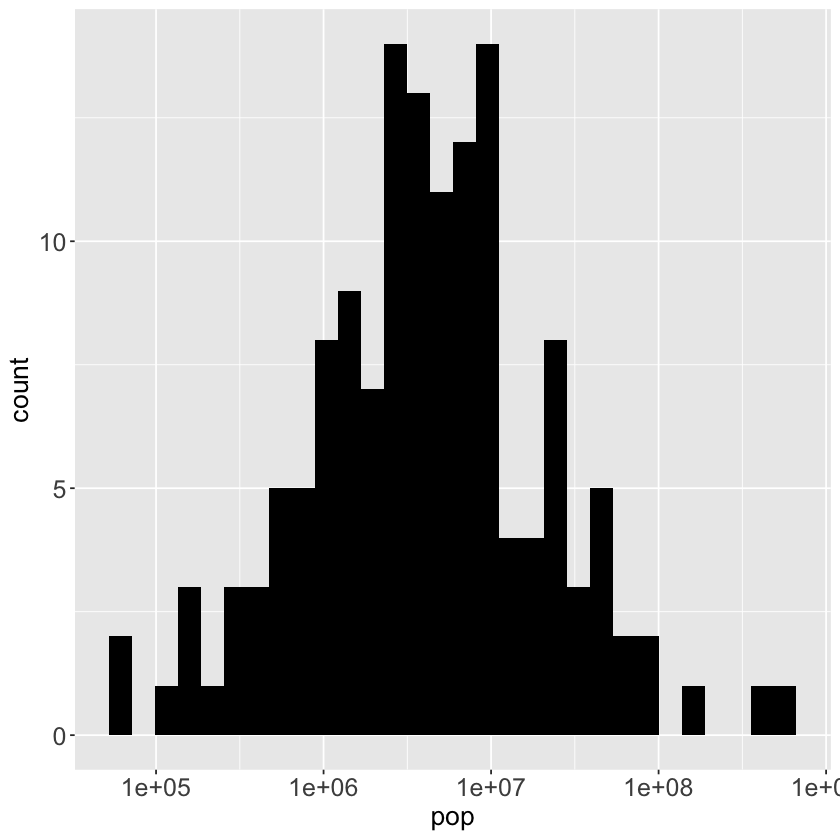

In [6]:
gapminder_1952 <- gapminder %>%
  filter(year == 1952)

# Create a histogram of population (pop), with x on a log scale
ggplot(gapminder_1952, aes(x = pop)) +
geom_histogram(fill = "black")+
scale_x_log10() +
theme(axis.text = element_text(size = 15),  
      axis.title.x = element_text(size = 16), 
      axis.title.y = element_text(size = 16))

## Box plots

Box plots, which compare the distribution of a numeric variable among several categories.

### What is a box plot?

A box plot (aka box and whisker plot) uses boxes and lines to depict the distributions of one or more groups of numeric data. Box limits indicate the range of the central 50% of the data, with a central line marking the median value. Lines extend from each box to capture the range of the remaining data, with dots placed past the line edges to indicate outliers.

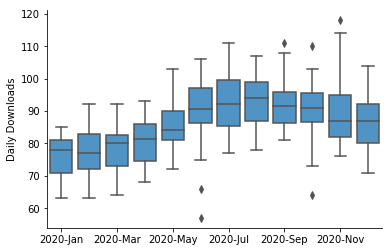

The example box plot above shows daily downloads for a fictional digital app, grouped together by month. From this plot, we can see that downloads increased gradually from about 75 per day in January to about 95 per day in August. There also appears to be a slight decrease in median downloads in November and December. Points show days with outlier download counts: there were two days in June and one day in October with low downloads compared to other days in the month. The box and whiskers plot provides a cleaner representation of the general trend of the data, compared to the equivalent line chart.

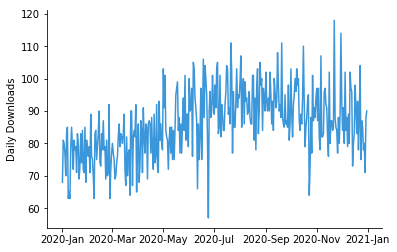

### When you should use a box plot

Box plots are used to show distributions of numeric data values, especially when you want to compare them between multiple groups. They are built to provide high-level information at a glance, offering general information about a group of data’s symmetry, skew, variance, and outliers. It is easy to see where the main bulk of the data is, and make that comparison between different groups.

On the downside, a box plot’s simplicity also sets limitations on the density of data that it can show. With a box plot, we miss out on the ability to observe the detailed shape of distribution, such as if there are oddities in a distribution’s modality (number of ‘humps’ or peaks) and skew.

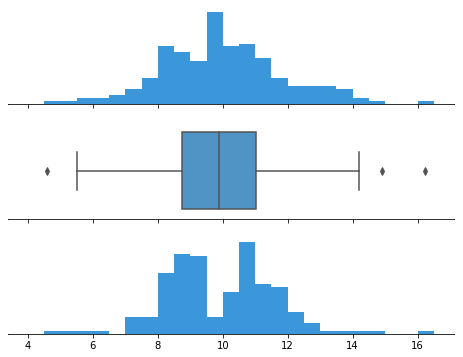

### Interpreting a box and whiskers

Construction of a box plot is based around a dataset’s quartiles, or the values that divide the dataset into equal fourths. The <b>first quartile (Q1)</b> is greater than 25% of the data and less than the other 75%. The <b>second quartile (Q2)</b> sits in the middle, dividing the data in half. Q2 is also known as the <b>median</b>. The <b>third quartile (Q3)</b> is larger than 75% of the data, and smaller than the remaining 25%. In a box and whiskers plot, the ends of the box and its center line mark the locations of these three quartiles.

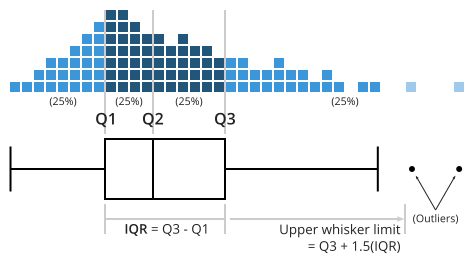

The distance between <b>Q3 and Q1</b> is known as the <b>interquartile range (IQR)</b> and plays a major part in how long the whiskers extending from the box are. Each whisker extends to the furthest data point in each wing that is within 1.5 times the IQR. Any data point further than that distance is considered an outlier, and is marked with a dot. There are other ways of defining the whisker lengths, which are discussed below.

https://muse.union.edu/dvorakt/what-drives-the-length-of-whiskers-in-a-box-plot/

https://towardsdatascience.com/why-1-5-in-iqr-method-of-outlier-detection-5d07fdc82097

When a data distribution is symmetric, you can expect the median to be in the exact center of the box: the distance between Q1 and Q2 should be the same as between Q2 and Q3. Outliers should be evenly present on either side of the box. If a distribution is skewed, then the median will not be in the middle of the box, and instead off to the side. You may also find an imbalance in the whisker lengths, where one side is short with no outliers, and the other has a long tail with many more outliers.

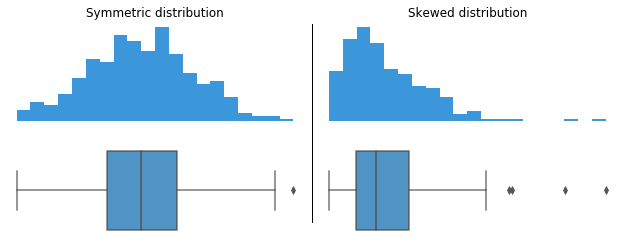

### Consider the order of groups

If the groups plotted in a box plot do not have an inherent order, then you should consider arranging them in an order that highlights patterns and insights. One common ordering for groups is to sort them by median value.



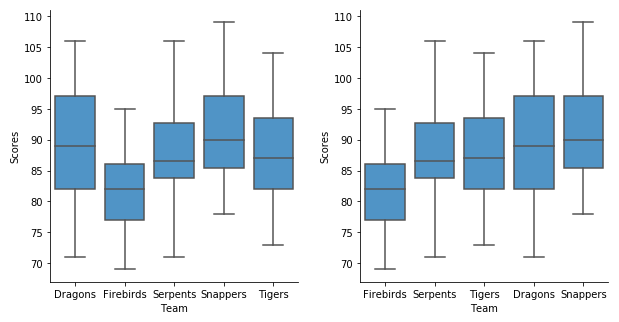

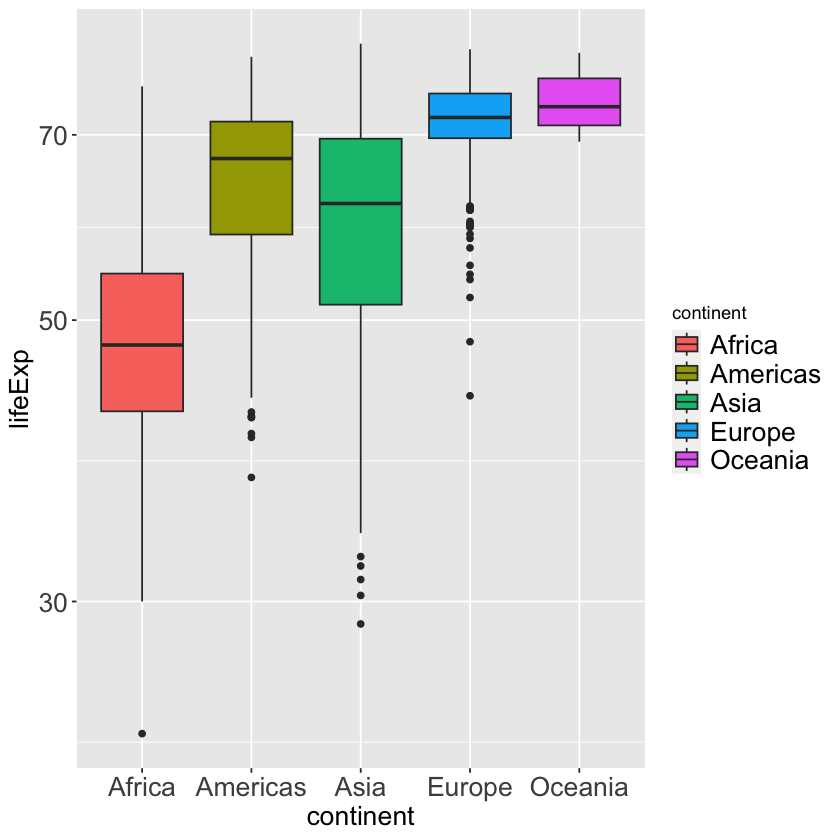

In [13]:
library(gapminder)
library(ggplot2)
library(dplyr)

ggplot(gapminder, aes(x = continent, y = lifeExp, fill = continent)) + 
geom_boxplot() + 
theme(axis.text = element_text(size = 16),  
      axis.title.x = element_text(size = 16), 
      axis.title.y = element_text(size = 16),
#      legend.title = element_text(size = 16),
     legend.text = element_text(size = 16)) +
scale_y_log10()

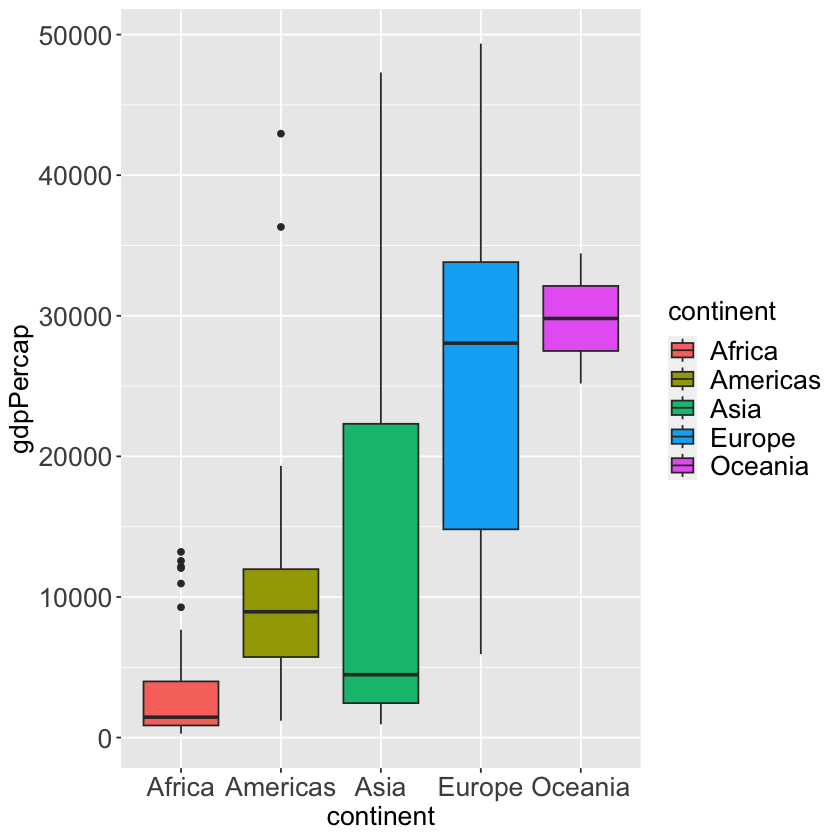

In [14]:
gapminder_1952 <- gapminder %>%
  filter(year == 2007)

# Create a boxplot comparing gdpPercap among continents
ggplot(gapminder_1952, aes(x = continent, y = gdpPercap, fill = continent)) + 
geom_boxplot() + 
theme(axis.text = element_text(size = 16),  
      axis.title.x = element_text(size = 16), 
      axis.title.y = element_text(size = 16),
     legend.title = element_text(size = 16),
     legend.text = element_text(size = 16)) 

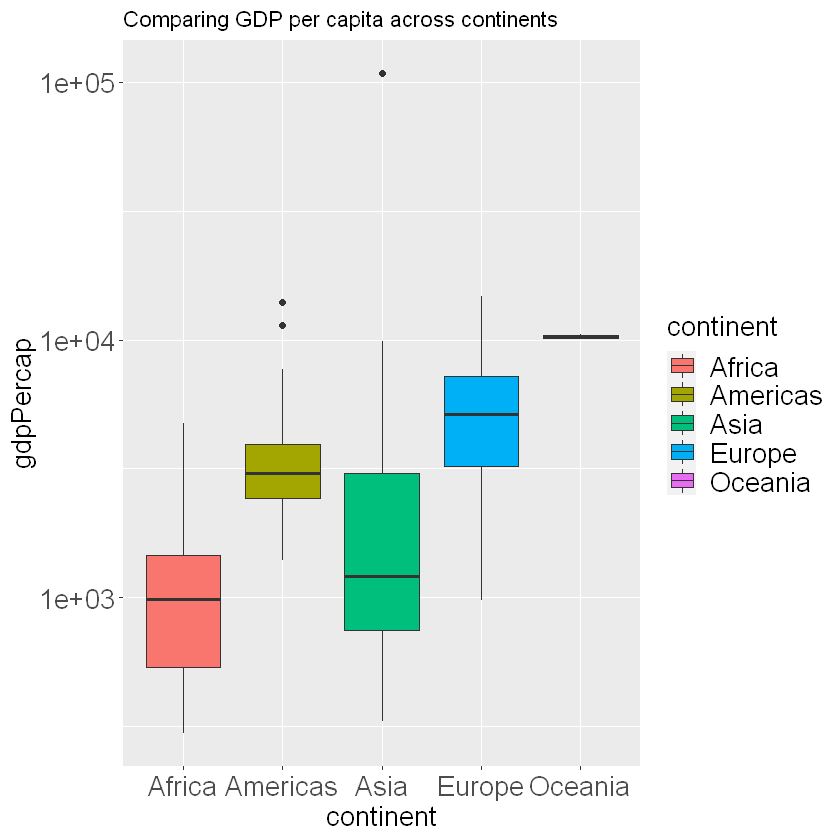

In [45]:
gapminder_1952 <- gapminder %>%
  filter(year == 1952)

# Create a boxplot comparing gdpPercap among continents
ggplot(gapminder_1952, aes(x = continent, y = gdpPercap, fill = continent)) + 
geom_boxplot() + 
scale_y_log10() +
theme(axis.text = element_text(size = 16),  
      axis.title.x = element_text(size = 16), 
      axis.title.y = element_text(size = 16),
     legend.title = element_text(size = 16),
     legend.text = element_text(size = 16)) +
  labs(title = "Comparing GDP per capita across continents")

https://r-graph-gallery.com/89-box-and-scatter-plot-with-ggplot2.html

## Violin plot

A violin plot depicts distributions of numeric data for one or more groups using density curves. The width of each curve corresponds with the approximate frequency of data points in each region. Densities are frequently accompanied by an overlaid chart type, such as box plot, to provide additional information.

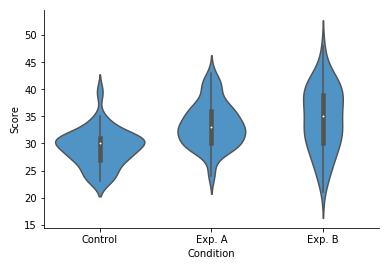


The example violin plot above depicts the results of a fictional experiment with one control group and two experimental conditions. In the middle of each density curve is a small box plot, with the rectangle showing the ends of the first and third quartiles and central dot the median. We can see from the plot that the two experimental techniques provided different benefits compared to the control. However, the second experimental condition (B) has a much more elongated distribution compared to the other two groups, without a distinct peak. The latter fact would have been missed with the box plot alone

### When you should use a violin plot

Violin plots are used when you want to observe the distribution of numeric data, and are especially useful when you want to make a comparison of distributions between multiple groups. The peaks, valleys, and tails of each group’s density curve can be compared to see where groups are similar or different. Additional elements, like box plot quartiles, are often added to a violin plot to provide additional ways of comparing groups, and will be discussed below.

### A brief explanation of density curves

The density curve, aka kernel density plot or kernel density estimate (KDE), is a less-frequently encountered depiction of data distribution, compared to the more common histogram. Below, we’ll perform a brief explanation of how density curves are built.

In a KDE, each data point contributes a small area around its true value. The shape of this area is called the kernel function. Kernels can take different shapes from smooth bell curves to sharp triangular peaks. In addition, kernels can have different width, or bandwidth, affecting the influence of each individual data point. Bandwidth size is usually determined by using mathematical rules of thumb, but can be tweaked depending on the shape and skew of the data to be plotted.

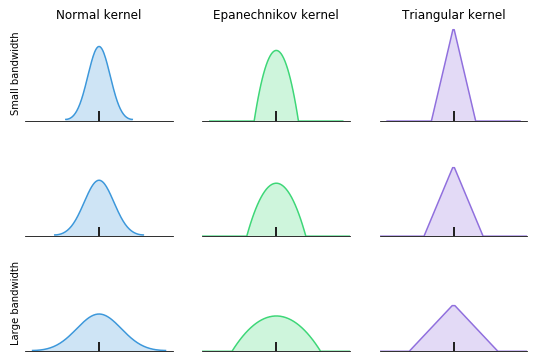


To build the final density curve, the areas for all data points are stacked up into a complete whole. Each data point has an equivalent influence on the final distribution. As there are more data points in a region, the height of the density curve in that area will increase.

Kernel density estimation is best used when a fair amount of data is available, resulting in more stable density estimates. With few data points available, it can be easy to be misled by the smoothness of the curve or the length of the tails past the largest and smallest points.

In a violin plot, individual density curves are built around center lines, rather than stacked on baselines. Other than this difference in display pattern, curves in a violin plot follow the exact same construction and interpretation.

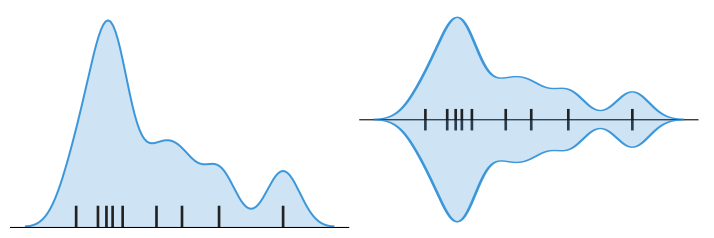

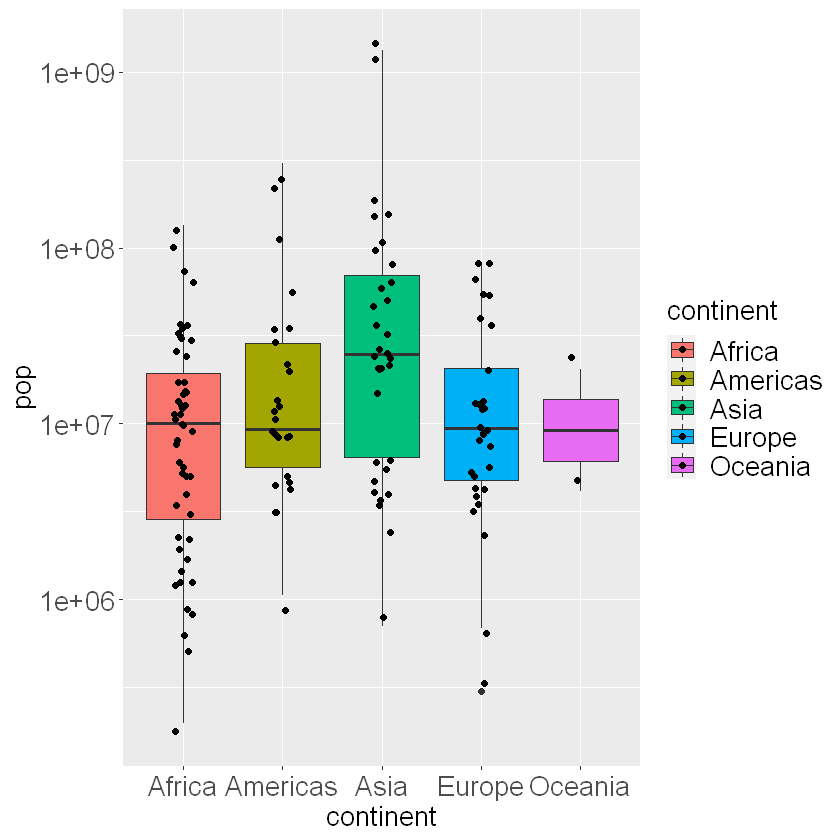

In [46]:
ggplot(gapminder_2007, aes(x = continent, y = pop, fill = continent)) + 
geom_boxplot() + 
scale_y_log10() +
theme(axis.text = element_text(size = 16),  
      axis.title.x = element_text(size = 16), 
      axis.title.y = element_text(size = 16),
     legend.title = element_text(size = 16),
     legend.text = element_text(size = 16)) +
  geom_jitter(width = 0.1, height = 0.1, colour = "black")

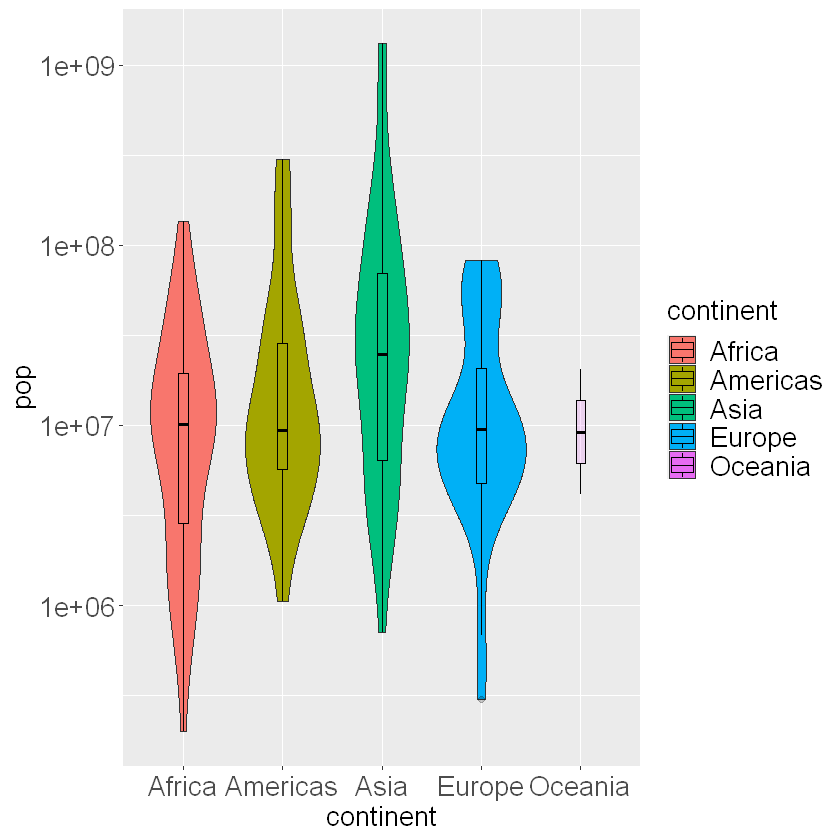

In [47]:
ggplot(gapminder_2007, aes(x = continent, y = pop, fill = continent))  + 
geom_violin() + 
scale_y_log10() +
geom_boxplot(width=0.1, color="black", alpha=0.2) +
theme(axis.text = element_text(size = 16),  
      axis.title.x = element_text(size = 16), 
      axis.title.y = element_text(size = 16),
     legend.title = element_text(size = 16),
     legend.text = element_text(size = 16)) 



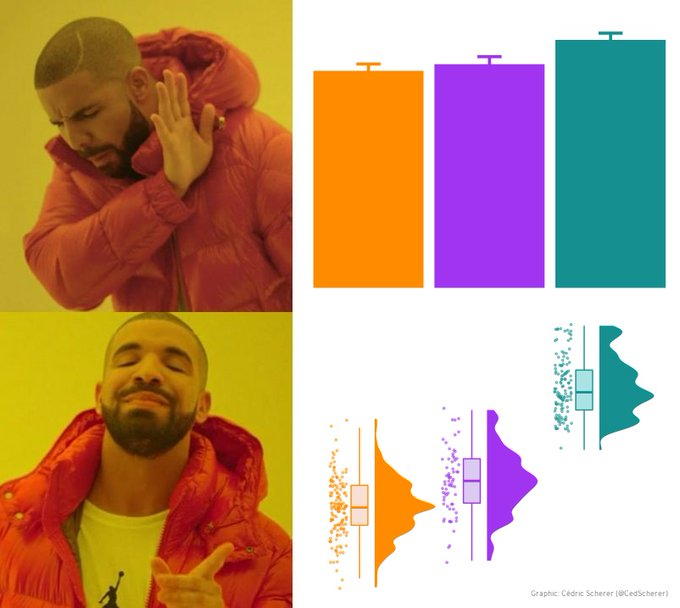

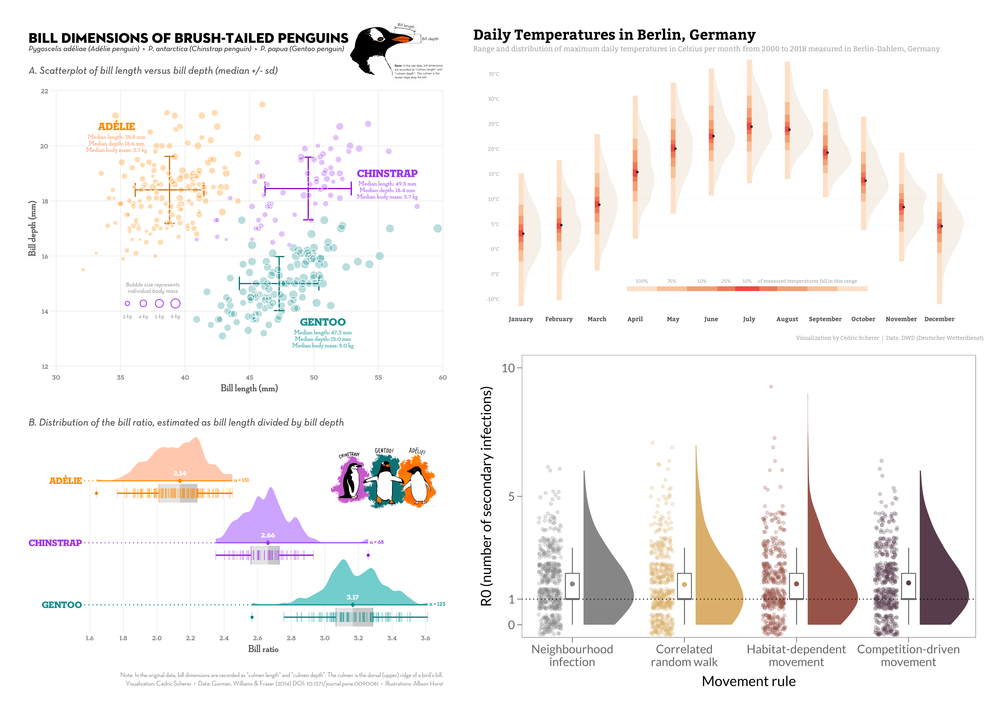

In [12]:
#install.packages("ggdist")

In [13]:
library(ggdist)

ERROR: Error in library(ggdist): there is no package called 'ggdist'


In [8]:
ggplot(gapminder_2007, aes(x = continent, y = pop)) + 
  ## add half-violin from {ggdist} package
  ggdist::stat_halfeye(
    ## custom bandwidth
    adjust = .5, 
    ## adjust height
    width = .6, 
    ## move geom to the right
    justification = -.2, 
    ## remove slab interval
    .width = 0, 
    point_colour = NA
  ) + 
  geom_boxplot(
    width = .12, 
    ## remove outliers
    outlier.color = NA ## `outlier.shape = NA` works as well
  ) +
  ## add dot plots from {ggdist} package
  ggdist::stat_dots(
    ## orientation to the left
    side = "left", 
    ## move geom to the left
    justification = 1.1, 
    ## adjust grouping (binning) of observations 
    binwidth = .25
  ) + 
  ## remove white space on the left
  coord_cartesian(xlim = c(1.2, NA))

ERROR: Error in loadNamespace(name): there is no package called 'ggdist'


https://www.cedricscherer.com/2021/06/06/visualizing-distributions-with-raincloud-plots-and-how-to-create-them-with-ggplot2/

## Pie plots

### What is a pie chart?

A pie chart shows how a total amount is divided between levels of a categorical variable as a circle divided into radial slices. Each categorical value corresponds with a single slice of the circle, and the size of each slice (both in area and arc length) indicates what proportion of the whole each category level takes.

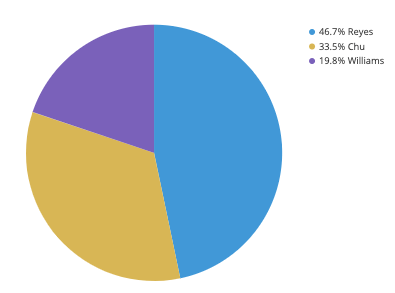

The pie chart above depicts the distribution of votes for a fictional election for a small city. We can see that Reyes, represented by the first blue slice, has just less than half of the votes. Chu (yellow) is in second, with about a third of the votes, while Williams (purple) is last, with about a fifth of the votes. The annotations in the upper right give us a more precise judgment of the proportions, but the pie chart tells the overarching story of where the votes fell.

### When you should use a pie chart

Pie charts have a fairly narrow use-case that is encapsulated particularly well by its definition. In order to use a pie chart, you must have some kind of whole amount that is divided into a number of distinct parts. Your primary objective in a pie chart should be to compare each group’s contribution to the whole, as opposed to comparing groups to each other. If the above points are not satisfied, the pie chart is not appropriate, and a different plot type should be used instead.

The values that comprise a whole and the categories that divide the whole generally come in two major varieties. First of all, is when the ‘whole’ represents a total count. Examples of this include votes in an election divided by candidate, or number of transactions divided by user type (e.g. guest, new user, existing user).

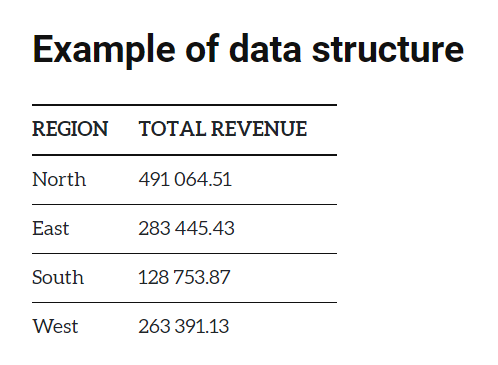

Data for a pie chart can be summarized in a table like the above, where the first column indicates a category, and the second the proportion, frequency, or amount of that category. Usually, the total does not need to be specified separately unless it is to be listed somewhere else on a generated figure.

### Best practices for using a pie chart

#### Include annotations

It is actually very difficult to discern exact proportions from pie charts, outside of small fractions like 1/2 (50%), 1/3 (33%), and 1/4 (25%). Furthermore, if the slice values are meant to depict amounts rather than proportions, pie charts typically lack the tick marks to allow for estimation of values directly from slice sizes. It is for these reasons that annotations are a standard inclusion for pie charts.

#### Consider the order of slices

A good order for slices can make it much easier for a reader to understand what the plot is saying. A typical ordering goes from the largest slice to the smallest slice, very useful when there are categories with very similar values. However, if the category levels have an inherent ordering, then plotting slices in that order is usually better.

#### Limit the number of pie slices

Pie charts with a large number of slices can be difficult to read. It can be difficult to see the smallest slices, and it can be difficult to choose enough colors to make all of the slices distinct. Recommendations vary, but if you have more than about five categories, you might want to think about using a different chart type. As another option, you might consider lumping small slices into a single ‘other’ slice, colored in a neutral gray.

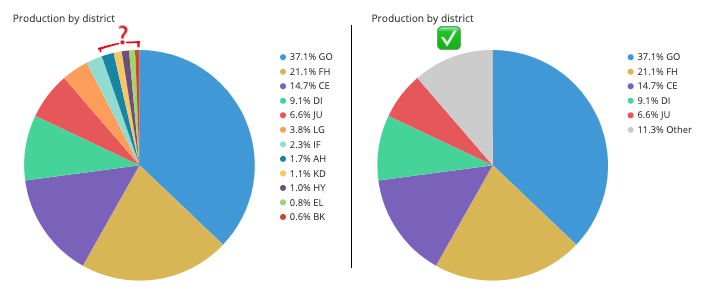

#### Avoid distorting effects

Reading a pie chart accurately requires that the slices’ areas, arc lengths, and angles all point to an accurate representation of the data. While avoiding 3-d effects is a good idea for any plot, it is especially important for pie charts. Squashing or stretching the circle or adding unnecessary depth can easily distort how large each slice compares to the whole.

Another distortion can come from the ‘exploded’ pie chart, where slices are pulled out from the center for emphasis. This emphasis comes with a cost, where the gaps can make it more difficult to actually gauge the part-to-whole comparison.

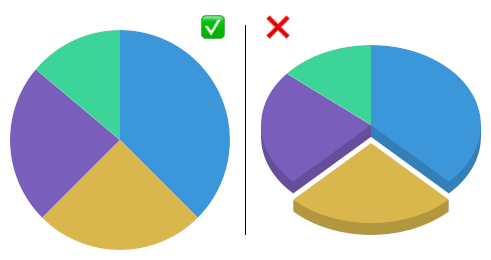

#### Fitting a pie to incompatible data

One of the most common mistakes with using a pie chart is to fit it to data that does not represent a parts-to-whole comparison. This confusion occurs most often when the values to be plotted are percentages or proportions, but don’t comprise a complete whole. The example below shows how frequently the people surveyed used each of four applications, but since many people used multiple apps, the proportions sum to much more than 100%.

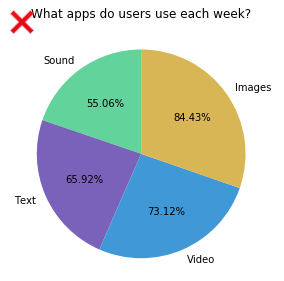

#### Using pie charts to compare groups to one another

If you want to make comparisons between groups rather than from each group to the whole, then you are better off with a different chart type. Even when sorting slices by size, it can be difficult to tell how different two slices are, especially when they move away from the start / end point. In the below example, you might assume that the second slice is larger than the third due to order, but the corresponding bar chart actually shows the opposite. The main thing that you can really say from the pie chart is that both slices are approximately the same proportions from the whole.

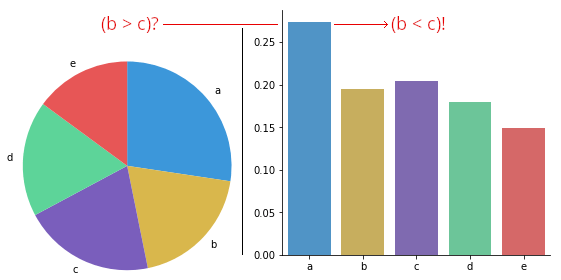

#### Comparing values across multiple pie charts

here may be cases where you will want to compare multiple pies to one another: for example, comparing user demographic distribution across multiple years. However, this runs into a similar issue as the previous section, where you want to compare groups to one another. Even worse, it’s a comparison between pies, so you can’t rely on the order of slices as easily for the comparison. Expressing the data using a different plot, like stacked bar chart, grouped bar chart, or line chart, is often a better choice when this kind of group-to-group comparison is desired. 

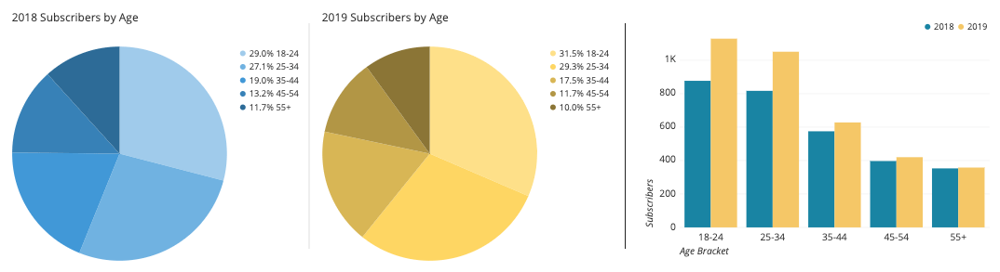

<b>Now it is your turn to put into practice the lessons we have been learning in this course. Using the gapminder dataset, select two variables to display as a pie chart

a clue:

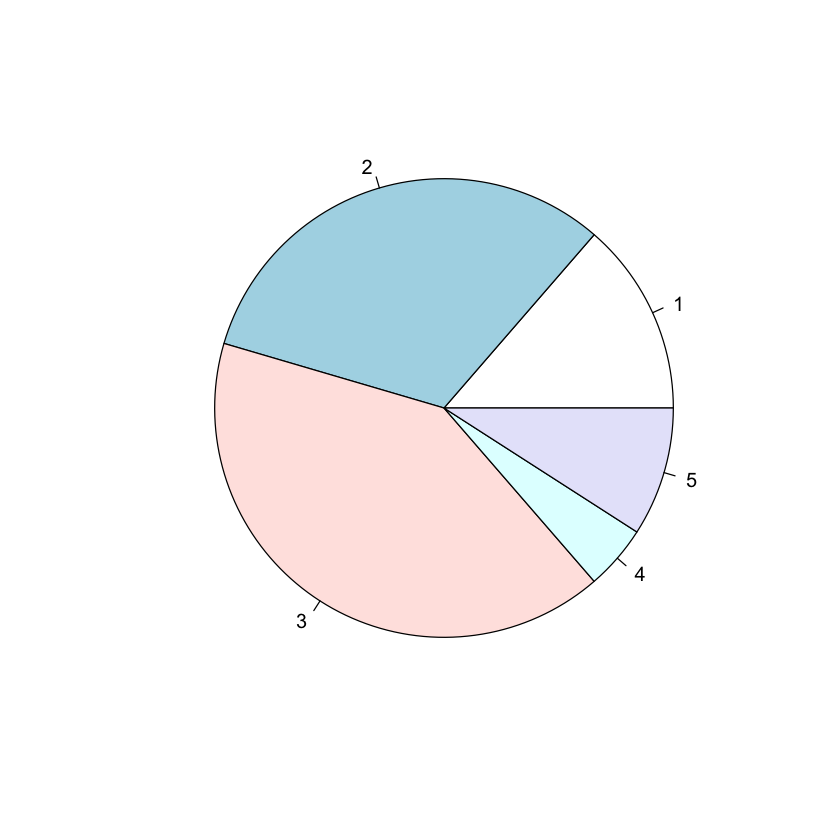

In [15]:
# Create Data
Prop <- c(3,7,9,1,2)
 
# Make the default Pie Plot
pie(Prop)

There is no specific <b>geom</b> to build piechart with <b>ggplot2</b>. The trick is to build a barplot and use <b>coord_polar</b> to make it circular. This is why the pie() function described above is probably a better alternative.

group,value
<fct>,<dbl>
A,13
B,7
C,9
D,21
E,2


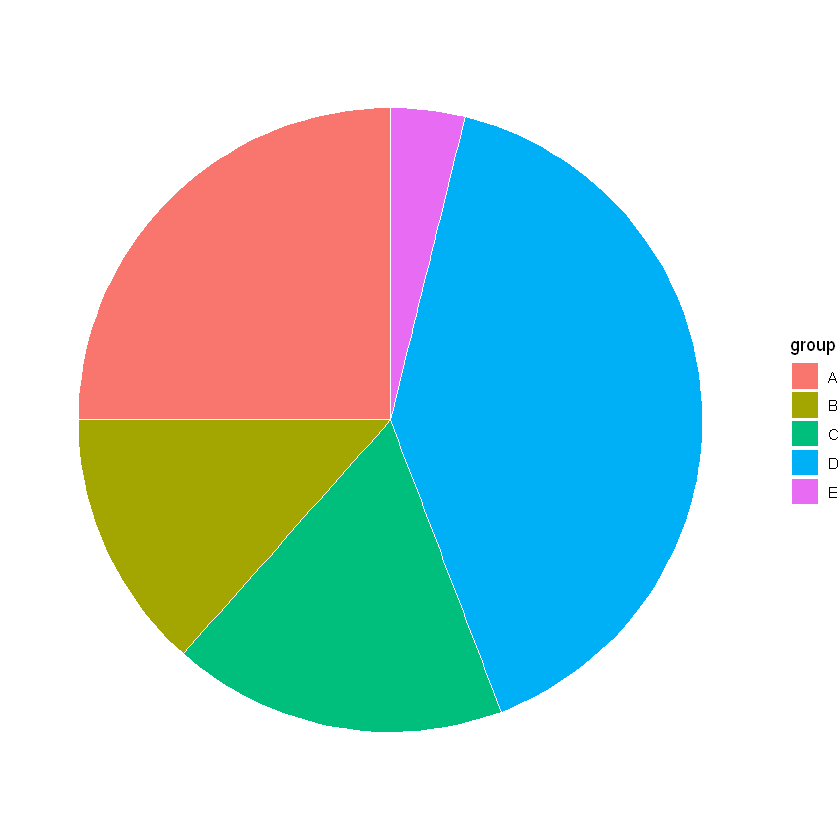

In [50]:
# Load ggplot2
library(ggplot2)

# Create Data
data <- data.frame(
  group=LETTERS[1:5],
  value=c(13,7,9,21,2)
)

data 

# Basic piechart
ggplot(data, aes(x="", y=value, fill=group)) +
  geom_bar(stat="identity", width=1, color="white") +
  coord_polar("y", start=0) +
  
  theme_void() # remove background, grid, numeric labels

group,value,prop,ypos
<fct>,<dbl>,<dbl>,<dbl>
E,2,3.846154,1.923077
D,21,40.384615,24.038462
C,9,17.307692,52.884615
B,7,13.461538,68.269231
A,13,25.000000,87.500000


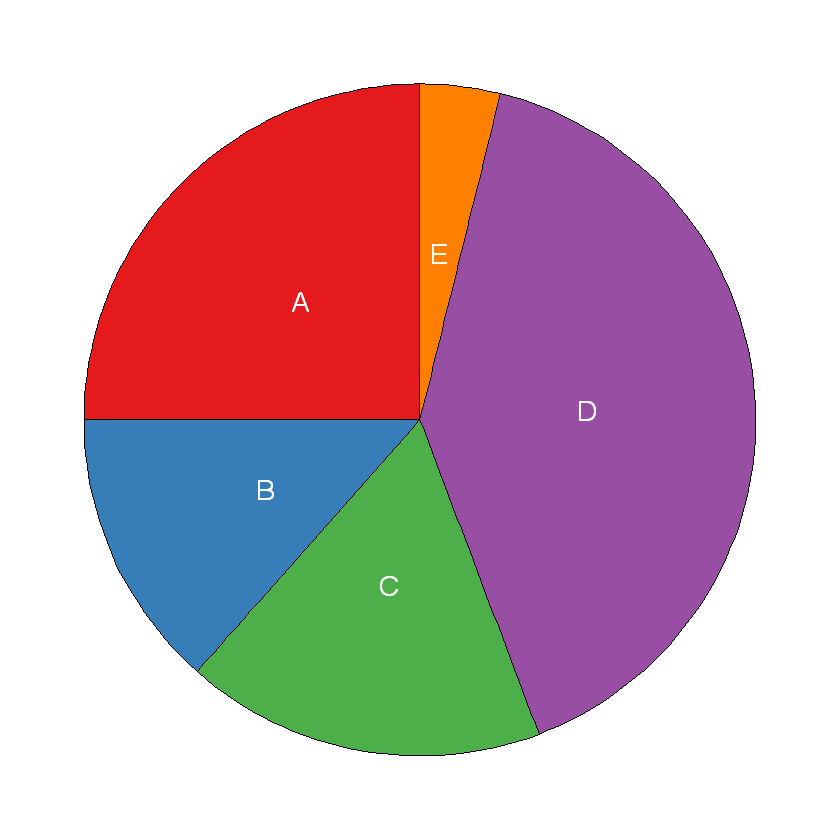

In [51]:
# Load ggplot2
library(ggplot2)
library(dplyr)

# Create Data
data <- data.frame(
  group=LETTERS[1:5],
  value=c(13,7,9,21,2)
)

# Compute the position of labels
data <- data %>% 
  arrange(desc(group)) %>%
  mutate(prop = value / sum(data$value) *100) %>%
  mutate(ypos = cumsum(prop)- 0.5*prop )

data
# Basic piechart
ggplot(data, aes(x="", y=prop, fill=group)) +
  geom_bar(stat="identity", width=1, color="black") +
  coord_polar("y", start=0) +
  theme_void() + 
  theme(legend.position="none") +
  
  geom_text(aes(y = ypos, label = group), color = "white", size=6) +
  scale_fill_brewer(palette="Set1")

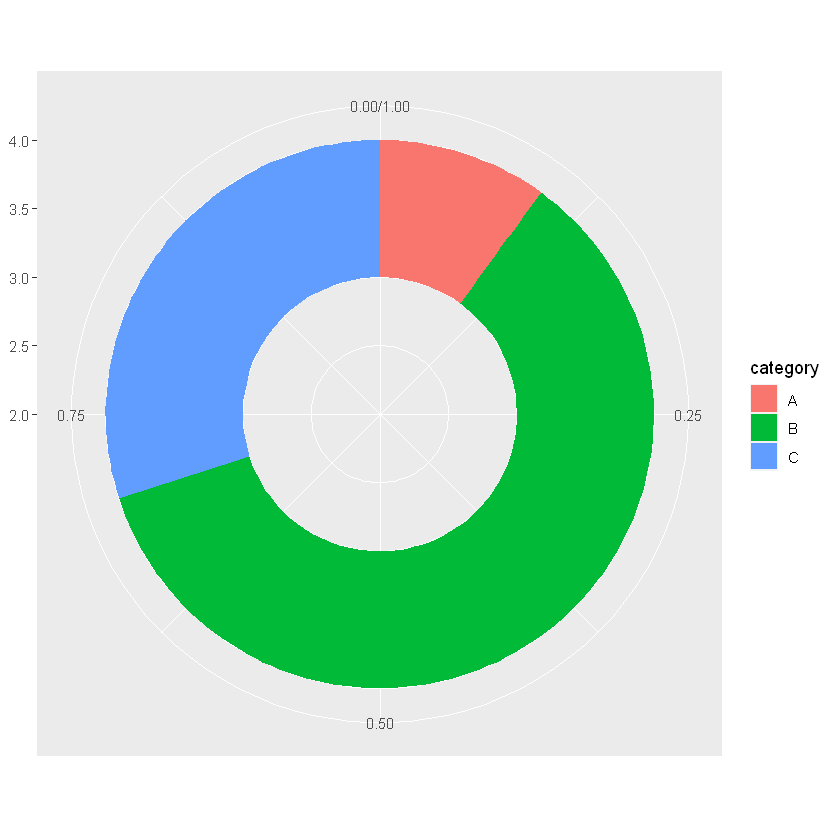

In [52]:
library(ggplot2)
 
# Create test data.
data <- data.frame(
  category=c("A", "B", "C"),
  count=c(10, 60, 30)
)
 
# Compute percentages
data$fraction = data$count / sum(data$count)

# Compute the cumulative percentages (top of each rectangle)
data$ymax = cumsum(data$fraction)

# Compute the bottom of each rectangle
data$ymin = c(0, head(data$ymax, n=-1))
 
# Make the plot
ggplot(data, aes(ymax=ymax, ymin=ymin, xmax=4, xmin=3, fill=category)) +
     geom_rect() +
     coord_polar(theta="y") + # Try to remove that to understand how the chart is built initially
     xlim(c(2, 4)) # Try to remove that to see how to make a pie chart

#https://r-graph-gallery.com/128-ring-or-donut-plot.html

## Heatmap

### What is a heatmap?

A heatmap (aka heat map) depicts values for a main variable of interest across two axis variables as a grid of colored squares. The axis variables are divided into ranges like a bar chart or histogram, and each cell’s color indicates the value of the main variable in the corresponding cell range.

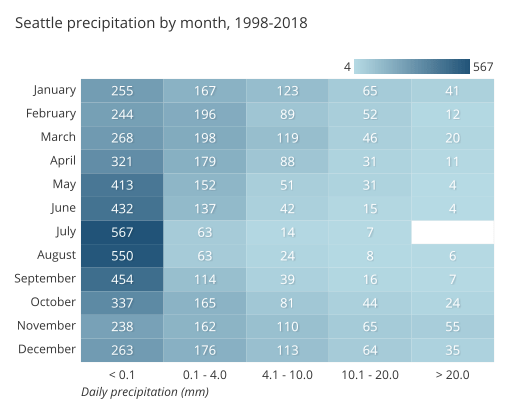

The example heatmap above depicts the daily precipitation distribution, grouped by month, and recorded over eleven years in Seattle, Washington. Each cell reports a numeric count, like in a standard data table, but the count is accompanied by a color, with larger counts associated with darker colorings. From the heat map, we can see from the darkest colorings in the left-most column that most days had no precipitation across the entire year. The pattern in cell colors across months also shows that rain is more common in the winter from November to March, and least common in the summer months of July and August.

### 2-d density plots

The term heatmap is also used in a more general sense, where data is not constrained to a grid. For example, tracking tools for websites can be set up to see how users interact with the site, like studying where a user clicks, or how far down a page readers tend to scroll.

Every click (or other tracking event) is associated with a position, which radiates a small amount of numeric value around its location. These values are totaled together across all events and then plotted with an associated colormap. The visual language of these tools’ output, associating value with color, is similar to the type of heatmap defined at the top, just without a grid-based structure. Heatmaps of this type are sometimes also known as 2-d density plots.

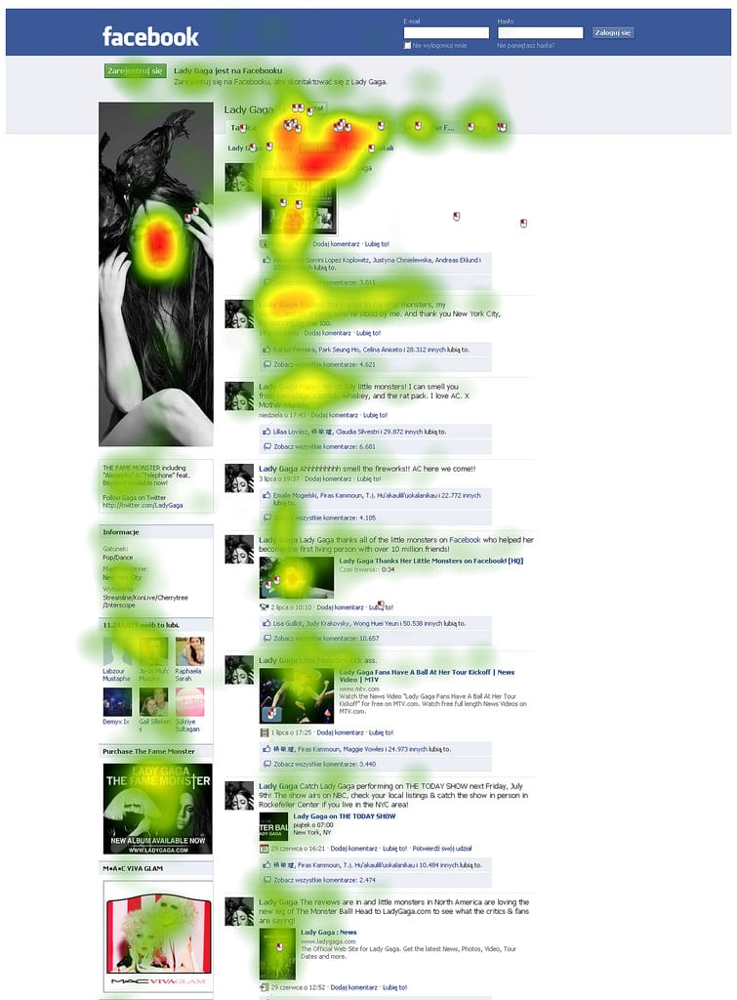

### When you should use a heatmap

Heatmaps are used to show relationships between two variables, one plotted on each axis. By observing how cell colors change across each axis, you can observe if there are any patterns in value for one or both variables.

The variables plotted on each axis can be of any type, whether they take on categorical labels or numeric values. In the latter case, the numeric value must be binned like in a histogram in order to form the grid cells where colors associated with the main variable of interest will be plotted.

Cell colorings can correspond to all manner of metrics, like a frequency count of points in each bin, or summary statistics like mean or median for a third variable. One way of thinking of the construction of a heatmap is as a table or matrix, with color encoding on top of the cells. In certain applications, it is also possible for cells to be colored based on non-numeric values (e.g. general qualitative levels of low, medium, high).

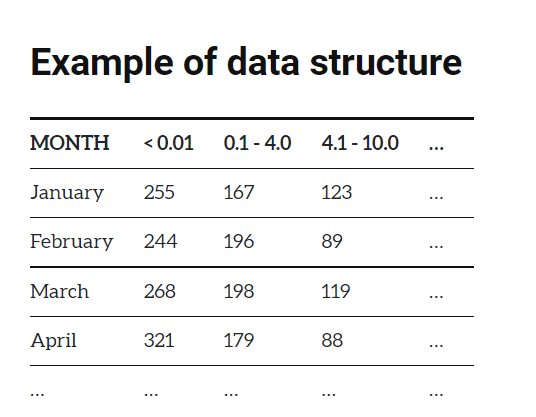

Different visualization applications can have different ways of accepting data for plotting as a heatmap. In one major form, data can be supplied in the same way it would be naturally displayed as a table. The first column will hold values for one axis of the heatmap, while the names of the remaining columns will correspond with bins for the remaining axis. Values in those columns will be encoded into the heatmap itself.

The other common form for heatmap data sets it up in a three-column format. Each cell in the heatmap is associated with one row in the data table. The first two columns specify the ‘coordinates’ of the heat map cell, while the third column indicates the cell’s value.

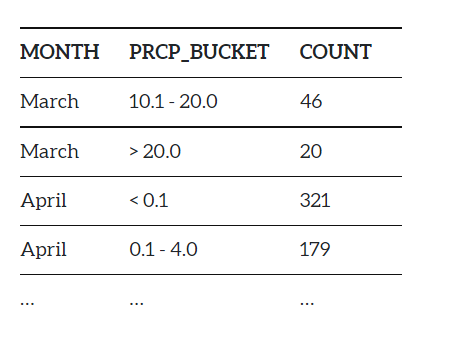

### Best practices for using a heatmap

#### Choose an appropriate color palette

Color is a core component of this chart type, so it’s worth making sure that you choose an appropriate color palette to match the data. Most frequently, there will be a sequential color ramp between value and color, where lighter colors correspond to smaller values and darker colors to larger values, or vice versa. However, a diverging color palette may be used when values have a meaningful zero point.

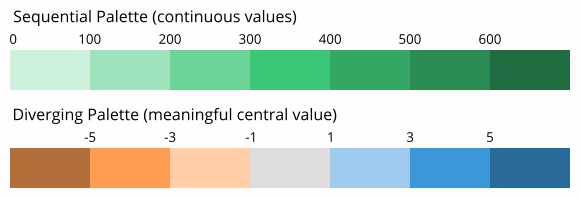

#### Include a legend

As an associated note, it is generally required for a heatmap to include a legend for how colors map to numeric values. Since color on its own has no inherent association with value, a key is vital for viewers to grasp the values in a heatmap. An exception for including a legend can come when the absolute association of value to color is not important, only the relative patterns of data plotted.

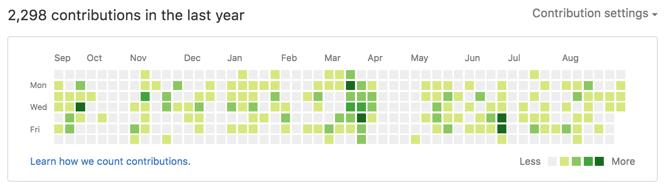

#### Show values in cells

There is a lack of precision for mapping color to value, especially compared to other encodings like position or length. Where possible, it is a good idea to add cell value annotations to the heatmap as a double encoding of value.

#### Sort levels by similarity or value

When one or both axis variables in a plot are categorical in nature, it can be worth considering changing the order in which those axis variable levels are plotted. If the categories do not have an inherent ordering, we might want to choose an order that best helps the reader grasp patterns in the data. A common option is to sort categories by their average cell value from largest to smallest.

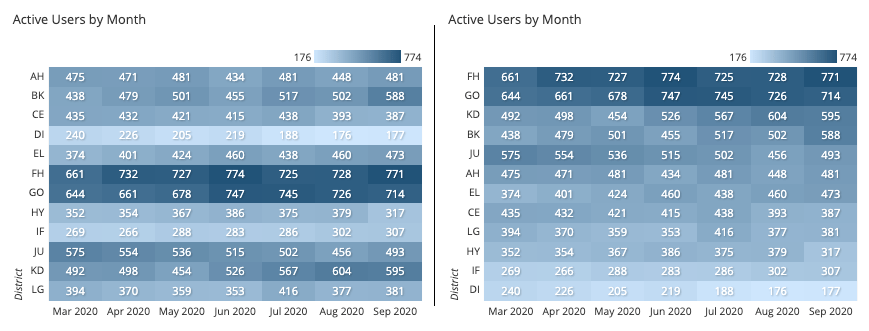

#### Select useful tick marks

For numeric axis variables, choices can be made in how bins are set up and how they are indicated in the chart. If there are few bins, it is fine to keep tick marks on each bin like for a categorical axis variable. However, when there are a lot of bins, a better option is to plot tick marks between sets of bins to avoid overcrowding. The number of bins that you should use and how large they are will depend on the nature of the data, so it can be a good idea to experiment with different settings. 

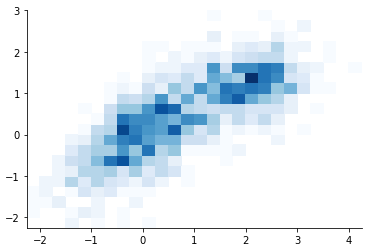

### Common heatmap options

#### Clustered heatmap

Instead of having the horizontal axis represent levels or values of a single variable, it is a common variation to have it represent measurements of different variables or metrics. If we set the vertical axis as individual observations, we end up with something resembling a standard data table, where each row is an observation and the columns the entity’s value on each measured variable.

This type of heatmap is sometimes known as a clustered or clustering heatmap, since the goal of this kind of chart is to build associations between both the data points and their features. We want to see which individuals are similar or different from each other, with a similar objective for variables. Analysis tools that construct this type of heatmap will usually implement clustering as part of their process. This use case is found in areas like the biological sciences, such as when studying similarities in gene expression across individuals.

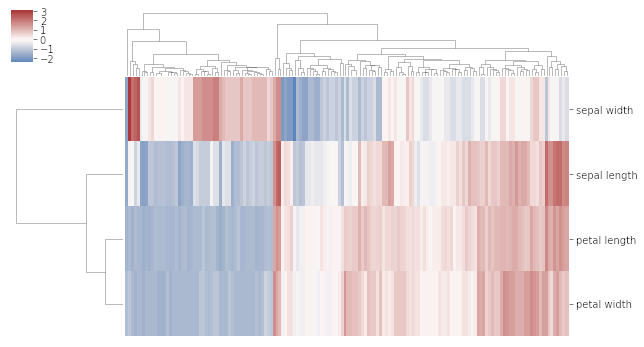

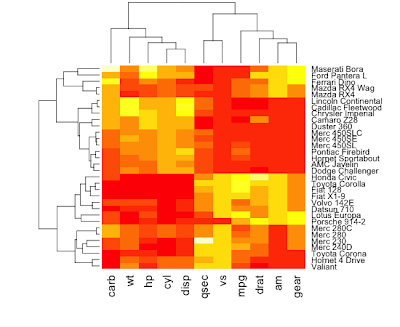

### Correlogram

A correlogram is a variant of the heatmap that replaces each of the variables on the two axes with a list of numeric variables in the dataset. Each cell depicts the relationship between the intersecting variables, such as a linear correlation.

Correlograms are often seen in an exploratory role, helping analysts understand relationships between variables in service of building descriptive or predictive statistical models.

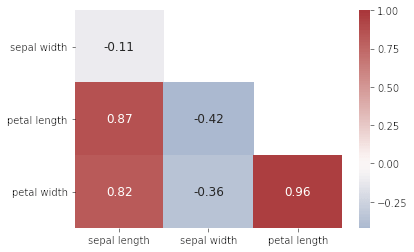

<b>Now it is your turn to put into practice the lessons we have been learning in this course. Using the gapminder dataset, select variables to display as a heatmap

a clue:

The heatmap() function is natively provided in R. It produces high quality matrix and offers statistical tools to normalize input data, run clustering algorithm and visualize the result with dendrograms. It is one of the very rare case where I prefer base R to ggplot2.

ggplot2 allows to build heatmaps thanks to geom_tile(). However, I personally prefer the heatmap() function above since only it offers option for normalization, clustering and Dendrogram.

country,continent,year,lifeExp,pop,gdpPercap
Afghanistan,Asia,1952,28.80100,8425333,779.4453
Afghanistan,Asia,1957,30.33200,9240934,820.8530
Afghanistan,Asia,1962,31.99700,10267083,853.1007
Afghanistan,Asia,1967,34.02000,11537966,836.1971
Afghanistan,Asia,1972,36.08800,13079460,739.9811
Afghanistan,Asia,1977,38.43800,14880372,786.1134


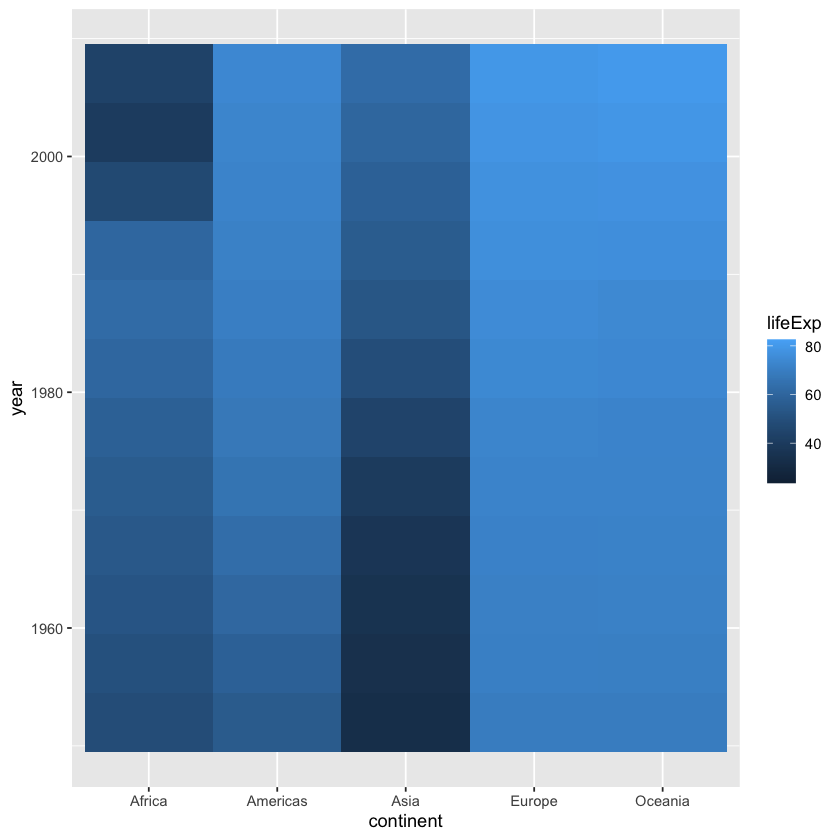

In [17]:
library(dplyr)
# The mtcars dataset:

data2 <- gapminder %>% select(continent, lifeExp, year)

# data <- as.matrix(mtcars)
data3 <- as.matrix(gapminder)

head(data3)

# Default Heatmap
# heatmap(data3[,2])

ggplot(gapminder, aes(x = continent, y = year, fill = lifeExp)) + geom_tile() 

In [ ]:
head(gapminder)

Note that it takes as input a matrix. If you have a data frame, you can convert it to a matrix with as.matrix(), but you need numeric variables only.

<b>Normalizing</b> the matrix is done using the scale argument of the heatmap() function. It can be applied to row or to column. Here the column option is chosen, since we need to absorb the variation between column.

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
Valiant,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
Duster 360,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2


,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
Valiant,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
Duster 360,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2
Merc 280,19.2,6,167.6,123,3.92,3.440,18.30,1,0,4,4


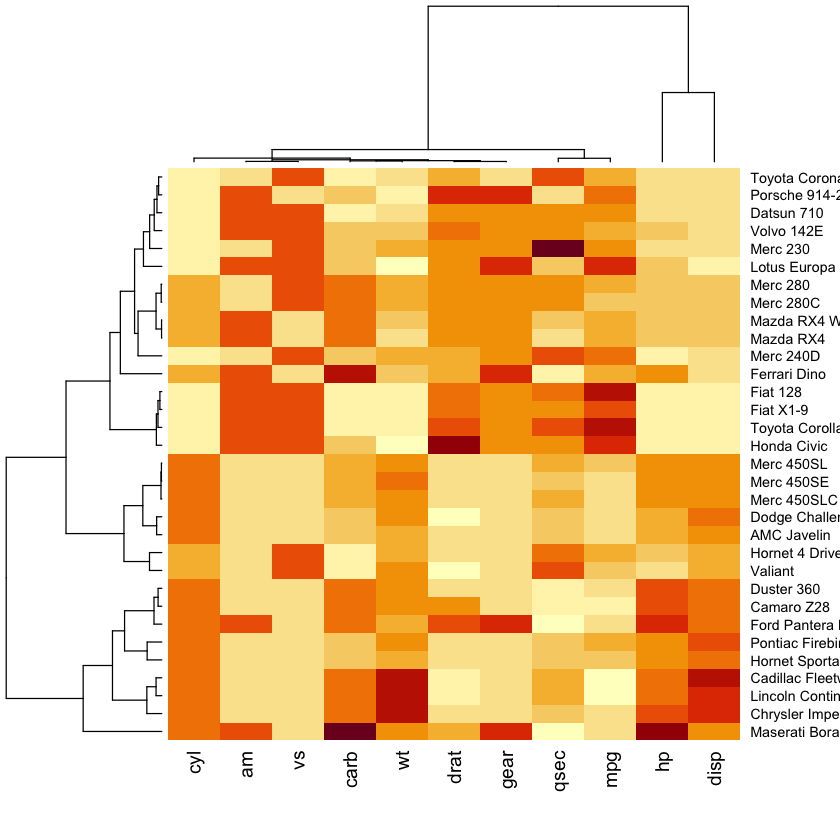

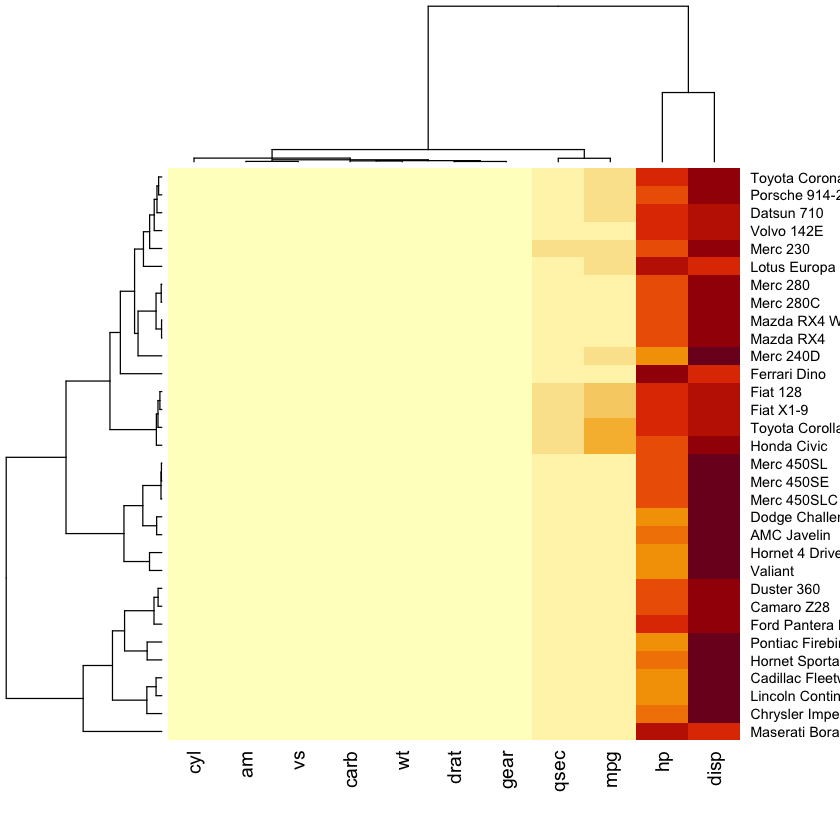

In [18]:
# Use 'scale' to normalize
mtcars

data <- as.matrix(mtcars)

data

heatmap(data, scale="column")

heatmap(data, scale="row")

You may have noticed that order of both rows and columns is different compare to the native mtcar matrix. This is because heatmap() reorders both variables and observations using a clustering algorithm: it computes the distance between each pair of rows and columns and try to order them by similarity.

Moreover, the corresponding dendrograms are provided beside the heatmap. We can avoid it and just visualize the raw matrix: use the Rowv and Colv arguments as follow.

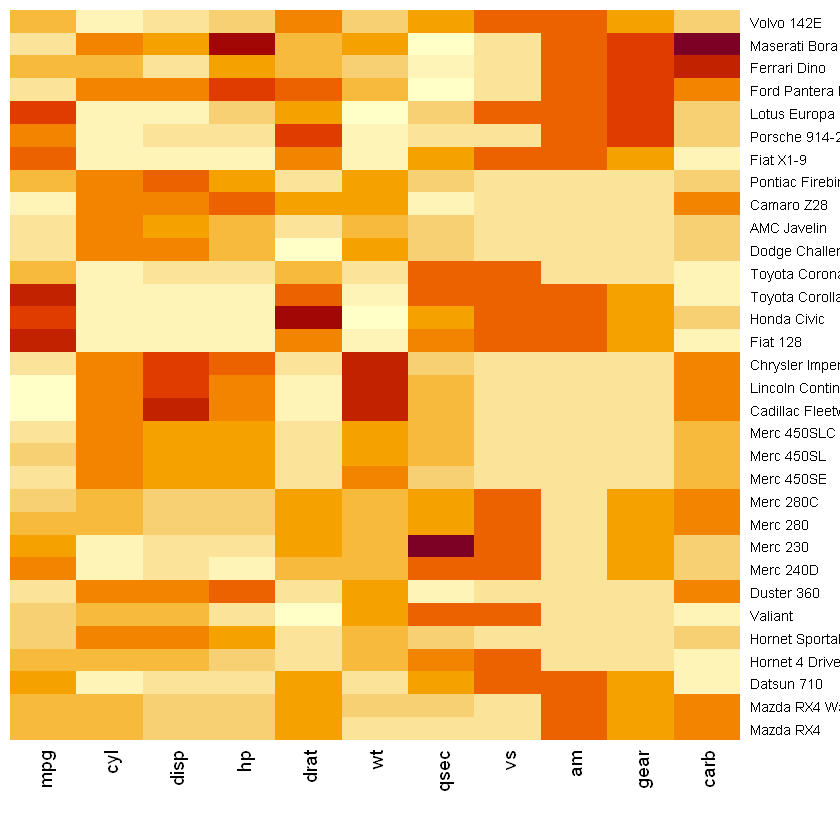

In [23]:
# No dendrogram nor reordering for neither column or row
heatmap(data, Colv = NA, Rowv = NA, scale="column")

<b>Color palette</b>

There are several ways to custom the color palette:

use the native palettes of R: 
* terrain.color()

* rainbow()

* heat.colors()

* topo.colors()

* cm.colors()




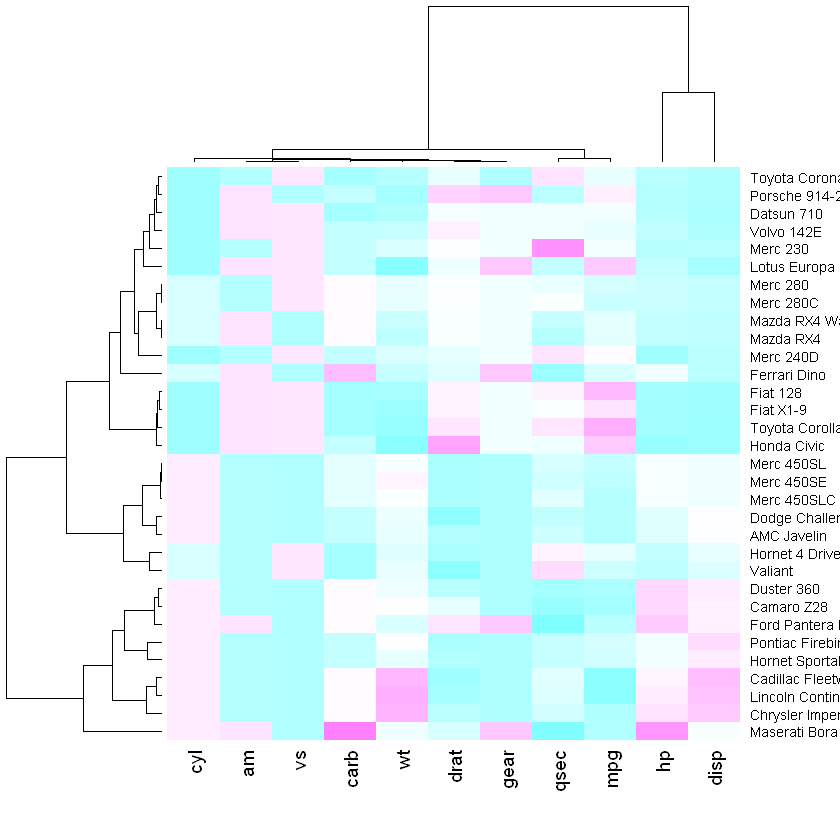

Warning message:
"package 'RColorBrewer' was built under R version 3.6.3"


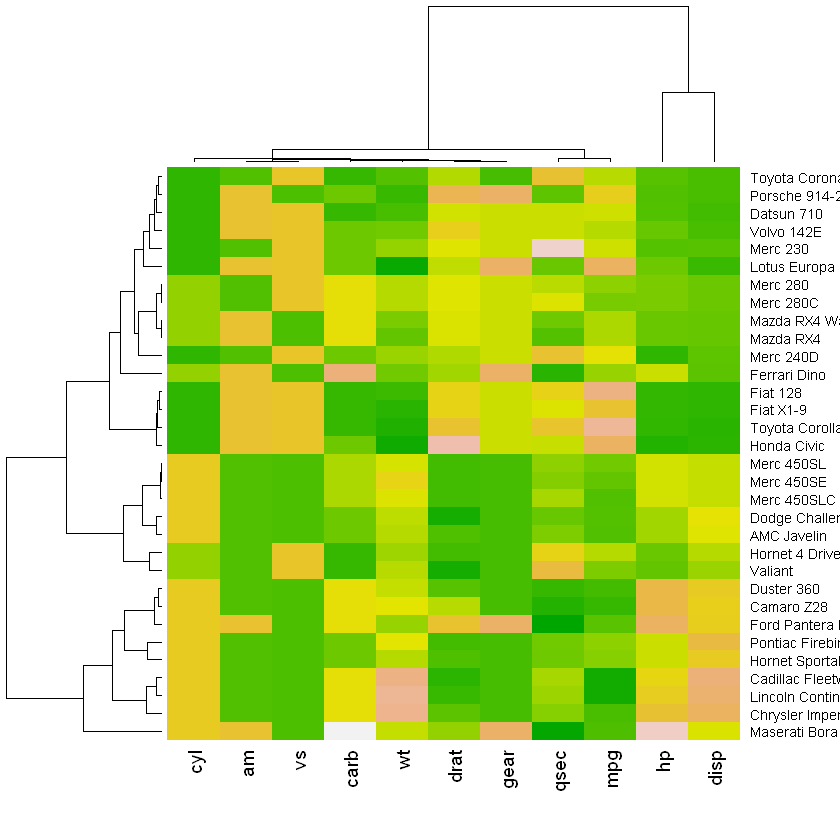

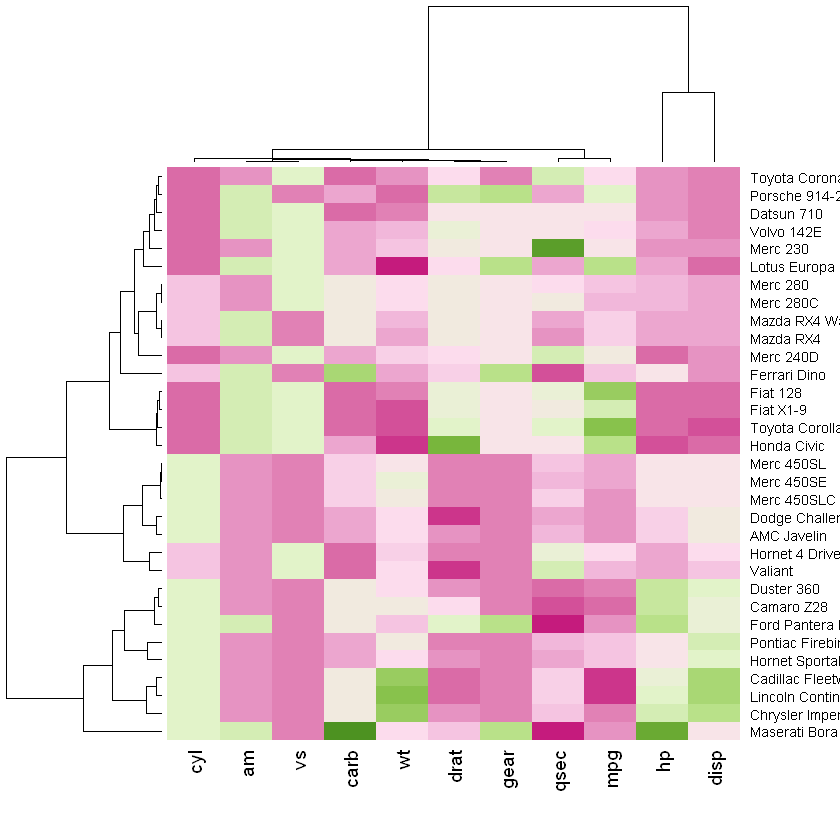

In [24]:
# 1: native palette from R
heatmap(data, scale="column", col = cm.colors(256))
heatmap(data, scale="column", col = terrain.colors(256))
 
# 2: Rcolorbrewer palette
library(RColorBrewer)
coul <- colorRampPalette(brewer.pal(8, "PiYG"))(25)
heatmap(data, scale="column", col = coul)

https://r-graph-gallery.com/215-the-heatmap-function.html

https://r-graph-gallery.com/correlogram.html

## R graph gallery 

### https://r-graph-gallery.com/

GGPLOT themes: 

https://ggplot2.tidyverse.org/reference/ggtheme.html?s=09